# Classification of field plastics in California
Annie Taylor

July 2024 to Feb 2026

Sentinel-2 classification of field plastic (plastic mulch and hoop house) use in key counties in California using GEE python API

### Import packages

In [1]:
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from IPython.display import display, HTML
from datetime import datetime, timedelta
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import geopandas as gpd
import altair as alt
import rasterio #used for pt sampling in section 8, zonal stats testing
from rasterio.plot import show
import seaborn as sns
import os
from rasterio.mask import mask # for area calc, can probably delete
import rioxarray
import xarray
from rasterstats import zonal_stats

#### Authenticate to earth engine account
User will need to change the cloud project to their GEE project and then go through the authentification workflow

In [2]:
cloud_project = 'ee-tnc-annietaylor'
try:
    ee.Initialize(project=cloud_project)
except:
    ee.Authenticate()
    ee.Initialize(project=cloud_project)

In [3]:
# editing the geemap.ee_to_df function slightly due to an issue with it's drop call specifying axis

def ee_to_df_edit(
    ee_object,
    columns=None,
    remove_geom=True,
    sort_columns=False,
    **kwargs,
):
    """Converts an ee.FeatureCollection to pandas dataframe.

    Args:
        ee_object (ee.FeatureCollection): ee.FeatureCollection.
        columns (list): List of column names. Defaults to None.
        remove_geom (bool): Whether to remove the geometry column. Defaults to True.
        sort_columns (bool): Whether to sort the column names. Defaults to False.
        kwargs: Additional arguments passed to ee.data.computeFeature.

    Raises:
        TypeError: ee_object must be an ee.FeatureCollection

    Returns:
        pd.DataFrame: pandas DataFrame
    """
    if isinstance(ee_object, ee.Feature):
        ee_object = ee.FeatureCollection([ee_object])

    if not isinstance(ee_object, ee.FeatureCollection):
        raise TypeError("ee_object must be an ee.FeatureCollection")

    if remove_geom:
        data = ee_object.map(
            lambda f: ee.Feature(None, f.toDictionary(f.propertyNames().sort()))
        )
    else:
        data = ee_object

    kwargs["expression"] = data
    kwargs["fileFormat"] = "PANDAS_DATAFRAME"

    df = ee.data.computeFeatures(kwargs)

    if isinstance(columns, list):
        df = df[columns]

    if remove_geom and ("geo" in df.columns):
        df = df.drop(columns=["geo"])

    if sort_columns:
        df = df.reindex(sorted(df.columns), axis=1)

    return df

### Old training dataset import/stats -- archive

In [4]:
# # Training data - import from repo 
# # Import the csvs with lat/longs as dfs (could all be one csv/df, keeping separate for testing)
# # train_path = "N:/OCEANS_Program/Plastics/Agricultural_Plastics/Validated Training Data/" # can use this when connected to VPN 
# train_path = 'data/Validated_Training_Data/'
# santamaria = pd.read_csv(train_path + 'SantaMaria_val_o.csv')
# mendocino = pd.read_csv(train_path + 'MendocinoCounty_val_o.csv')
# # watsonville = pd.read_csv(train_path + 'Watsonville_val.csv')
# watsonville = pd.read_csv(train_path + 'Watsonville_val_BM.csv')
# # replace 'black mulch' with 'blackmulch' to avoid issues with space in label
# watsonville['Type'] = watsonville['Type'].replace('black mulch', 'blackmulch')
# oxnard_original = pd.read_csv(train_path + 'YYT_RElabeled_points_date_fixed.csv')
# # Drop the 'TARGET_FID' column from the 'oxnard' DataFrame - shouldn't need this anymore
# # oxnard_original = oxnard_original.drop('TARGET_FID', axis=1)
# oxnard_add = pd.read_csv(train_path + 'Oxnard_additional_val.csv')
# oxnard = pd.concat([oxnard_original, oxnard_add], axis=0, ignore_index=True)
# # importing new other trees dataset
# othertrees = pd.read_csv(train_path + 'Brandee_Other_Trees_2025.csv')

# # Print out unique 'Type' values for each df to check for typos
# print('Checking for typos in the Type column:')
# # all_dfs = [santamaria, mendocino, watsonville, oxnard]
# all_dfs = [santamaria, watsonville, oxnard, othertrees]
# for df in all_dfs:
#     print(df['Location'].iloc[0])
#     print('\tunique types', df['Type'].unique())
#     print('\tnumber of rows:', df.shape[0])

# all_data = pd.concat(all_dfs, axis=0, ignore_index=True)
# print('Total number of training points:', all_data.shape[0])
# print('\tunique types', all_data['Type'].unique())
# print('Number of rows in each class of Type:')
# print(all_data['Type'].value_counts())
# # print('unique dates:', all_data['Date'].unique())

# # removing unused dates from the training data to get metadata/stats

# all_data_test = all_data
# # remove dates before 2018-05-09
# all_data_test['Date'] = pd.to_datetime(all_data_test['Date']).dt.strftime('%Y-%m-%d')
# all_data_test = all_data_test[all_data_test['Date'] > '2018-05-09']
# all_data_test = all_data_test[all_data_test['Type'] != 'greenhouse']
# print('unique dates:', all_data_test['Date'].unique())
# print('Total number of training points:', all_data_test.shape[0])
# print('\tunique types', all_data_test['Type'].unique())
# print('Number of rows in each class of Type:')
# print(all_data_test['Type'].value_counts())
# print(all_data_test['Location'].value_counts())
# # display('Watsonville dates: ', all_data_test[all_data_test['Location'] == 'Watsonville']['Date'].unique())
# # display('Oxnard dates: ', all_data_test[all_data_test['Location'] == 'Oxnard']['Date'].unique())
# # display('Santa Maria dates: ', all_data_test[all_data_test['Location'] == 'Santa Maria']['Date'].unique())

# # # print a chart showing the number of points per date, stratified by Location
# # # Group the data by 'Date' and 'Location' and count the number of points
# # grouped_data = all_data_test.groupby(['Date', 'Location']).size().reset_index(name='Count')
# # pivot_data = grouped_data.pivot(index='Date', columns='Location', values='Count').fillna(0)
# # pivot_data.plot(kind='bar', stacked=True, figsize=(15, 7))
# # plt.title('Number of Points per Date Stratified by Location')
# # plt.xlabel('Date')
# # plt.ylabel('Number of Points')
# # plt.xticks(rotation=45, ha='right')
# # plt.legend(title='Location')
# # plt.tight_layout()
# # plt.show()


### Import new field/date split and spatially not-autocorrelated training/test dataset

In [5]:
# load data
training = pd.read_csv('data/AllTraining_080425prj_SJfiltered.csv')
# combine all black mulch types into one
training['Type'] = training['Type'].replace('black mulch', 'blackmulch')
# set date column to EE format
training['Date'] = pd.to_datetime(training['Date']).dt.strftime('%Y-%m-%d')
# remove 2018-05-09 data -- no s2 image for it
training = training[training['Date'] != '2018-05-09']

# Stats, optional:
print('Total number of training points:', training.shape[0])
# print('\tunique types', training['Type'].unique())
# print('Number of rows in each class of Type:\n', training['Type'].value_counts())
# print('Unique dates:', training['Date'].unique())
# print('Number of rows in each location:\n', training['Location'].value_counts())
# convert date to datetime format for consistency
# training['Date'] = pd.to_datetime(training['Date']).dt.strftime('%Y-%m-%d')

display(training.head())


Total number of training points: 3739


,Location,Date,Type,Region,Latitude,Longitude,Split,Date_Loc,Orig_FID
0,CA,2023-05-26,other,Morgan Hill,37.188061,-121.725901,1,2023-05-26 CA,1
1,CA,2023-05-26,other,Morgan Hill,37.189068,-121.724510,1,2023-05-26 CA,2
2,CA,2023-05-26,other,Morgan Hill,37.190223,-121.722561,1,2023-05-26 CA,3
3,CA,2023-05-26,other,Morgan Hill,37.187451,-121.719603,1,2023-05-26 CA,4
4,CA,2023-05-26,other,Morgan Hill,37.189402,-121.726455,1,2023-05-26 CA,5


#### Evaluate temporal breakdown of training and test data

Assigns the split (via split_grouped field)

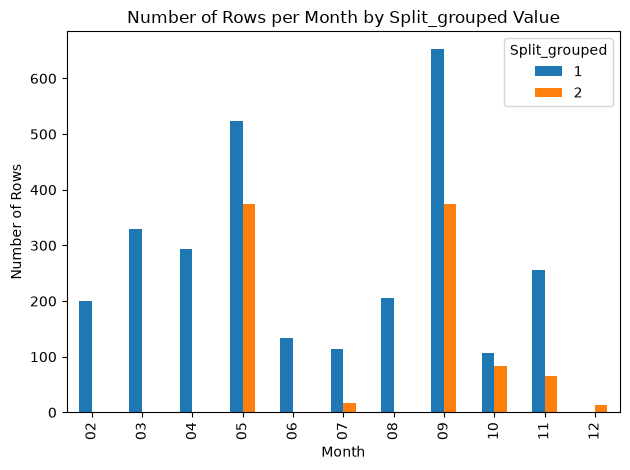

Training: 75.2%  |  Testing: 24.8%


In [6]:
# # Print unique month values grouped by Split value
# for split_val in sorted(training['Split'].unique()):
#     months = sorted(set(pd.to_datetime(training[training['Split'] == split_val]['Date']).dt.strftime('%m')))
#     print(f"Months included in Split {split_val}: {months}")

# # Extract month from 'Date' column
training['Month'] = pd.to_datetime(training['Date']).dt.strftime('%m')

# # Group by 'Month' and 'Split', then count rows
# month_split_counts = training.groupby(['Month', 'Split']).size().unstack(fill_value=0)

# # bar chart
# month_split_counts.plot(kind='bar', stacked=False)
# plt.xlabel('Month')
# plt.ylabel('Number of Rows')
# plt.title('Number of Rows per Month by Split Value')
# plt.legend(title='Split')
# plt.tight_layout()
# plt.show()

# create a new column to test a different test/train split

# Calculate the number of rows for each Date_Loc
date_loc_counts = training['Date_Loc'].value_counts()

# Shuffle the unique Date_Loc values for randomness
unique_date_locs = training['Date_Loc'].unique()
np.random.seed(87)
shuffled_date_locs = np.random.permutation(unique_date_locs)

# Calculate the cumulative sum of rows as we add each Date_Loc
cumulative_counts = date_loc_counts.loc[shuffled_date_locs].cumsum()
# print(f"Cumulative counts: {cumulative_counts}")
total_rows = date_loc_counts.sum()
split_idx = np.argmax(cumulative_counts >= total_rows * 0.7) + 1  # +1 to include the index where threshold is crossed

train_date_locs = set(shuffled_date_locs[:split_idx])
test_date_locs = set(shuffled_date_locs[split_idx:])

# Assign Split_grouped: 1 for train, 2 for test
training['Split_grouped'] = training['Date_Loc'].apply(lambda x: 1 if x in train_date_locs else 2)

# Check distribution across months
month_split_grouped_counts = training.groupby(['Month', 'Split_grouped']).size().unstack(fill_value=0)
month_split_grouped_counts.plot(kind='bar', stacked=False)
plt.xlabel('Month')
plt.ylabel('Number of Rows')
plt.title('Number of Rows per Month by Split_grouped Value')
plt.legend(title='Split_grouped')
plt.tight_layout()
plt.show()

# Print the percentage of points in each split
train_pct = (training['Split_grouped'] == 1).mean() * 100
test_pct = (training['Split_grouped'] == 2).mean() * 100
print(f"Training: {train_pct:.1f}%  |  Testing: {test_pct:.1f}%")

#### Create a version of the training data for import into olmo earth platform

In [7]:
# # display(training.head())
# training_olmo = training.copy()

# # rename columns to match olmo reqs
# training_olmo = training_olmo.rename(columns={'Latitude': 'latitude', 'Longitude': 'longitude',
#                                         'Date': 'start_time', 'Split_grouped': 'train_test_split'})

# # add an end_time column that is one month later than the start_time
# # just an estimate, we don't know when the land cover would have changed
# training_olmo['end_time'] = pd.to_datetime(training_olmo['start_time']) + pd.DateOffset(months=1)
# training_olmo['end_time'] = training_olmo['end_time'].dt.strftime('%Y-%m-%d')

# training_olmo = training_olmo.drop(columns=['Location', 'Region', 'Split', 'Date_Loc',
#                                             'Orig_FID', 'Month'])
# display(training_olmo.head())

# # export this version to csv
# training_olmo.to_csv('data/olmo_training_data_all.csv', index=False)

# # create a version where 'blackmulch' type is changed to 'mulch'

# print('Unique types before change:', training_olmo['Type'].unique())
# training_olmo['Type'] = training_olmo['Type'].replace('blackmulch', 'mulch')
# print('Unique types after change:', training_olmo['Type'].unique())

# # save to csv
# training_olmo.to_csv('data/olmo_training_data_mulchcombo.csv', index=False)


#### Supplemental figure showing training data spread

In [8]:
# # supp figure
# plt.rcParams["font.family"] = "Calibri"


# month_split_grouped_counts = training.groupby(['Month', 'Split_grouped']).size().unstack(fill_value=0)
# ax = month_split_grouped_counts.plot(
#     kind='bar',
#     stacked=False,
#     color=['purple', 'orange']
# )

# # Add hatch pattern to bars where Split_grouped == 2
# for bars in ax.containers:
#     # Only apply hatch to the second bar (testing split)
#     if bars.get_label() == '2':
#         for bar in bars:
#             bar.set_hatch('/')

# plt.xlabel('Month', fontsize=16)
# plt.ylabel('Count of Points', fontsize=16)
# plt.legend(['Training', 'Testing'], handlelength=1.1, fontsize=14)
# plt.xticks(fontsize=14)
# # label x ticks with month names
# # month_names = ['February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
# # plt.xticks(ticks=range(len(month_names)), labels=month_names, rotation=30, fontsize=14)
# plt.yticks(fontsize=14)
# plt.tight_layout()

# # plt.savefig('output/SuppFigure_TrainTestSplit_byMonth_v1_4.png', dpi=500)
# plt.show()


### Load EE data

In [4]:
# California boundary
ca = ee.FeatureCollection("TIGER/2018/States").filter(ee.Filter.equals('NAME', 'California'))
# Agricultural areas from CA DWR's crop maps, 2019 to 2022 inclusive (10m raster)
# crops = ee.Image('projects/ee-annalisertaylor/assets/TNC/agplastics/dwr_allyears')
# Agricultural areas from CA DWR's crop maps, 2019 to 2023 inclusive (10m raster)
crops = ee.Image('projects/ee-tnc-annietaylor/assets/agplastics/dwr_allyears_24')
# socal region for image clipping
socal = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/socal').first()

# County boundaries for spatial filtering 
county_bnd = ee.FeatureCollection("TIGER/2016/Counties").filterBounds(ca)
# make features of the counties you want for filtering/analysis
ventura = county_bnd.filter(ee.Filter.eq('NAME', 'Ventura'))
mendo = county_bnd.filter(ee.Filter.eq('NAME', 'Mendocino'))
cruz = county_bnd.filter(ee.Filter.eq('NAME', 'Santa Cruz'))
santabarbara = county_bnd.filter(ee.Filter.eq('NAME', 'Santa Barbara'))
kern = county_bnd.filter(ee.Filter.eq('NAME', 'Kern'))
humboldt = county_bnd.filter(ee.Filter.eq('NAME', 'Humboldt'))
sanbenito = county_bnd.filter(ee.Filter.eq('NAME', 'San Benito'))
sf = county_bnd.filter(ee.Filter.eq('NAME', 'San Francisco'))
monterey = county_bnd.filter(ee.Filter.eq('NAME', 'Monterey'))
sanmateo = county_bnd.filter(ee.Filter.eq('NAME', 'San Mateo'))
yolo = county_bnd.filter(ee.Filter.eq('NAME', 'Yolo'))
losangeles = county_bnd.filter(ee.Filter.eq('NAME', 'Los Angeles'))
slo = county_bnd.filter(ee.Filter.eq('NAME', 'San Luis Obispo'))

# # to read all the county options
# county_df = ee_to_df_edit(county_bnd)
# pd.set_option('display.max_rows', 75)
# display(county_df['NAME'])

# Encode labels - ee classifier requires numeric class labels
class_mapping = {'hoop': 0, 'mulch': 1, 'other': 2, 'blackmulch': 3}
# only watsonville has greenhouse points right now, santa maria has a separate (unimported) dataset
# but there are no greenhouse points in the cleaned up training dataset
# crops.projection()

In [10]:
# # calc area in km of santa cruz, monterey, ventura, and santa barbara counties from the ee features extracted in the code block above

# santa_cruz_area_km = cruz.geometry().area().divide(1e6).getInfo()
# monterey_area_km = monterey.geometry().area().divide(1e6).getInfo()
# ventura_area_km = ventura.geometry().area().divide(1e6).getInfo()
# santa_barbara_area_km = santabarbara.geometry().area().divide(1e6).getInfo()

# print("Santa Cruz County Area (km²):", santa_cruz_area_km)
# print("Monterey County Area (km²):", monterey_area_km)
# print("Ventura County Area (km²):", ventura_area_km)
# print("Santa Barbara County Area (km²):", santa_barbara_area_km)


In [11]:
# total_co_area = santa_cruz_area_km + monterey_area_km + ventura_area_km + santa_barbara_area_km
# print("Total County Area (km²):", total_co_area)

# frac = total_co_area / 300000

# print("Fraction of Total County Area to 300,000 km²:", frac)

# test = frac * 11
# test

# total = total_co_area * 11
# total

# # Dissolve the four county geometries into one combined geometry
# def remove_islands(fc):
#     """Keep only the largest polygon (by area) from a feature's geometry, removing islands."""
#     geom = fc.first().geometry()
#     polygons = ee.List(geom.geometries()) if geom.type().getInfo() == 'MultiPolygon' else None
#     if polygons is None:
#         return fc
#     # Sort polygons by area, descending, and take the largest
#     def add_area(p):
#         p = ee.Geometry(p)
#         return ee.Feature(p, {'area': p.area()})
#     polygon_features = ee.FeatureCollection(polygons.map(add_area))
#     largest = polygon_features.sort('area', False).first()
#     return ee.FeatureCollection([ee.Feature(largest.geometry())])

# santabarbara_clean = remove_islands(santabarbara)
# ventura_clean = remove_islands(ventura)

# # Dissolve the four county geometries into one combined geometry (using cleaned SB and Ventura)
# combined_geometry = ee.FeatureCollection([cruz, monterey, ventura_clean, santabarbara_clean]).flatten().union()
# aef_fc = ee.FeatureCollection([ee.Feature(combined_geometry.first().geometry())])

# # Set up export to asset task
# export_task = ee.batch.Export.table.toAsset(
#     collection=aef_fc,
#     description='Export_Combined_County_Geometry',
#     assetId='projects/ee-tnc-annietaylor/assets/agplastics/aef_combined_counties'
# )

# export_task.start()

# Map = geemap.Map()
# Map.addLayer(aef_fc, {}, "AEF Combined Counties")
# Map.centerObject(aef_fc)
# Map


## 1. Process Sentinel-2 Imagery

### Cloud filter the image collection

In [5]:
startDate = ee.Date.fromYMD(2010, 1, 1) # setting these to be inclusive for now, can change
endDate = ee.Date.fromYMD(2025, 10, 1)

s2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
    .filter(ee.Filter.date(startDate, endDate)) \
    .filter(ee.Filter.bounds(ca)) \
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 92))  

#### Cloud filtering with the s2_cloudless collection

In [6]:
# cloud mask using the cloudless image collection, pulling from EE documentation example
s2cloud = ee.ImageCollection('COPERNICUS/S2_CLOUD_PROBABILITY')
s2cloud = s2cloud.filterBounds(ca)
MAX_CLOUD_PROBABILITY = 15

def maskClouds(img):
    clouds = ee.Image(img.get('cloud_mask')).select('probability')
    isNotCloud = clouds.lt(MAX_CLOUD_PROBABILITY)
    return img.updateMask(isNotCloud)

# Masks for the 10m bands can include bad data at scene edge; apply masks from the 20m and 60m bands too
def maskEdges(s2_img):
    return s2_img.updateMask(s2_img.select('B8A').mask().updateMask(s2_img.select('B9').mask()))

# So I can investigate how this is performing above plastic cover
def addCloudless(img):
    cloud_prob = ee.Image(img.get('cloud_mask')).select('probability')
    return img.addBands(cloud_prob.rename('cloud_probability'))

# Filter s2cloud to same region, fix 10m pixels at edges
s2_mask = s2.map(maskEdges)

# Join S2 with cloud probability dataset to add cloud mask
# cloudless image is saved as a property called 'cloud_mask' in the original image
s2sr_cloudmask = ee.Join.saveFirst('cloud_mask').apply(primary=s2_mask, secondary=s2cloud, \
                            condition=ee.Filter.equals(leftField='system:index', rightField='system:index'))

# create the cloud masked image collection
s2_cldmsk = ee.ImageCollection(s2sr_cloudmask).map(maskClouds)

# create an image collection with the cloud probability band, not yet masked
# this is for testing to see what values certain pixels have
s2_cld_test = ee.ImageCollection(s2sr_cloudmask).map(addCloudless)

#### Cloud filtering with the QA band 
Checked this out after seeing problems with the s2_cloudless filter, but apparently this band doesn't contain any info from feb 2022 to feb 2024 so it's not usable

In [7]:
def mask_s2_clouds(image):
   qa = image.select('QA60')
   # Bits 10 and 11 are clouds and cirrus, respectively.
   cloud_bit_mask = 1 << 10
   cirrus_bit_mask = 1 << 11
   # Both flags should be set to zero, indicating clear conditions.
   mask = (qa.bitwiseAnd(cloud_bit_mask).eq(0).And(qa.bitwiseAnd(cirrus_bit_mask).eq(0)))
   return image.updateMask(mask)

s2_qa_cldmsk = s2.map(mask_s2_clouds)

#### Cloud filtering with MSK_CLDPRB band

In [8]:
cloud_threshold = 10

def mask_s2_clouds_cm(image):
   cm = image.select('MSK_CLDPRB')
   isNotCloud = cm.lt(MAX_CLOUD_PROBABILITY)
   return image.updateMask(isNotCloud)

s2_cm_cldmsk = s2.map(mask_s2_clouds_cm)

#### Cloud filtering with the SCL band -- this is what we're using

In [9]:
# 8 = Clouds Medium Probability
# 9 = Clouds High Probability
# 10 = Cirrus

def mask_s2_clouds_scl(image):
    scl = image.select('SCL')
    isNotCloud = scl.neq(8).And(scl.neq(9).And(scl.neq(10)))
    return image.updateMask(isNotCloud)

s2_scl_cldmsk = s2.map(mask_s2_clouds_scl)

#### Cloud filtering with google cloud score function
https://courses.spatialthoughts.com/end-to-end-gee.html#batch-exports

In [10]:
# Load the Cloud Score+ collection, now available 2015 onwards
csPlus = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')
csPlusBands = csPlus.first().bandNames() # ['cs', 'cs_cdf']

# join cloud score+ with s2 collection
filteredS2WithCs = s2.linkCollection(csPlus, csPlusBands)

# display('Filtered S2 with CS+ bands:', filteredS2WithCs.first())

# Function to mask pixels with low CS+ QA scores.
def mask_s2_clouds_gcs(image):
  qaBand = 'cs' # probability of clear sky
  clearThreshold = 0.5
  mask = image.select(qaBand).gte(clearThreshold)
  return image.updateMask(mask)

s2_gcs_cldmsk = filteredS2WithCs.map(mask_s2_clouds_gcs)

#### Combined SCL + Cloud Score filters

In [11]:
# Function to mask pixels with low CS+ QA scores and classified as clouds by SCL band
def mask_s2_clouds_combo(image):
  # GCS
  qaBand = 'cs' # probability of clear sky
  clearThreshold = 0.5
  mask = image.select(qaBand).gte(clearThreshold)
  image = image.updateMask(mask)
  # SCL
  scl = image.select('SCL')
  isNotCloud = scl.neq(8).And(scl.neq(9).And(scl.neq(10)))
  return image.updateMask(isNotCloud)

s2_combo_cldmsk = filteredS2WithCs.map(mask_s2_clouds_combo)

### Vis params

In [12]:
rgbVis = {'min': 400, 'max': 1500, 'bands': ['B4', 'B3', 'B2']}
RPGI_viz = {'min': -0.9, 'max': -0.4, 'palette': ['#4d004b', '#f7fcfd']}
NDTI_viz = {'min': 0.0, 'max': 0.2, 'palette': ['white', 'yellow', 'orange']}
# visualize the classified plastic
plastic_viz = {'palette': ['FF5733', 'F4F31D', '2596be', '#333333'], 'min': 0, 'max': 3}
et_viz = {
  'min': 0,
  'max': 100,
  'palette': [
    '9e6212', 'ac7d1d', 'ba9829', 'c8b434', 'd6cf40', 'bed44b', '9fcb51',
    '80c256', '61b95c', '42b062', '45b677', '49bc8d', '4dc2a2', '51c8b8',
    '55cece', '4db4ba', '459aa7', '3d8094', '356681', '2d4c6e',
  ]
}
band_viz = {'min':603, 'max': 2725}
crop_viz = {'palette': ['#FFA500']}
crop_viz2 = {'palette': ["#FFEE00","#FF7300"]}

### Add VIs

In [13]:
def addVIs(image):
    image = image.addBands(image.normalizedDifference(['B8', 'B4']).rename('NDVI'))
    # image = image.addBands(image.normalizedDifference(['B8', 'B12']).rename('NBR')) # one band at 20m
    image = image.addBands(image.normalizedDifference(['B8', 'B11']).rename('NDMI')) # one band at 20m
    image = image.addBands(image.normalizedDifference(['B3', 'B8']).rename('NDWI'))
    # image = image.addBands(image.expression("2.5 * ((b('B8') - b('B4')) / (b('B8') + 6 * b('B4') - 7.5 * b('B2') + 1))").rename('EVI'))
    image = image.addBands(image.normalizedDifference(['B11', 'B12']).rename('NDTI')) # swir1 and swir2, both 20m, tillage index
    image = image.addBands(image.expression("100 * (b('B2') * (b('B8') - b('B4')))/(1 - ((b('B2') + b('B3') + b('B8')) / 3))").rename('PGI')) # all 10m
    image = image.addBands(image.expression("b('B2')/(1 - ((b('B2') + b('B3') + b('B8')) / 3))").rename('RPGI'))
    image = image.addBands(image.normalizedDifference(['B11', 'B4']).rename('PMLI')) # one band at 20m
    image = image.addBands(image.normalizedDifference(['B11', 'B8']).rename('NDBI')) # one band at 20m   
    return image

def adjPGI(image):
    # TODO check if this threshold for NDBI is too high
    # set all bands in the image to 0 where NDVI is higher than 0.73 OR when NDBI is higher than 0.005
    PGI_adj = image.where(image.select('NDVI').gt(0.73), 0)
    PGI_adj = PGI_adj.where(PGI_adj.select('NDBI').gte(0.005), 0)
    # extract the 'PGI' band from that modified image, and add it to the original image with a new name
    image = image.addBands(PGI_adj.select('PGI').rename('PGI_adj'))   
    return image

# not using this right now, keeping it as a useful example for downsampling the NIR band
# will be more precise if we decide to publish any of these data
def addNBR_RS(image):
    # reduces the resolution of the NIR band (10m) to match the SWIR band (20m)
    #   using the mean of all pixels within the larger pixel
    swir = image.select('B12')
    swir_projection = swir.projection()
    nir = image.select('B8').reduceResolution(reducer=ee.Reducer.mean(), maxPixels=16).reproject(crs=swir_projection)
    js_math_exp = 'c = (a-b) / (a+b)'
    js_math_img = ee.Image().expression(
        expression=js_math_exp, opt_map={'a': nir, 'b': swir}
    ).rename('NBR_RS')
    image = image.addBands(js_math_img)
    return image


### Build the collection

In [14]:
# one for each method of cloud filtering, for comparison
# # s2_cloudless
# processedCollection_cld = s2_cldmsk.map(addVIs)
# processedCollection_cld = processedCollection_cld.map(adjPGI)
# # scl map
# processedCollection_scl = s2_scl_cldmsk.map(addVIs)
# processedCollection_scl = processedCollection_scl.map(adjPGI)
# # cloud score+ map
# processedCollection_gcs = s2_gcs_cldmsk.map(addVIs)
# processedCollection_gcs = processedCollection_gcs.map(adjPGI)
# combo cloud score + scl
processedCollection_combo = s2_combo_cldmsk.map(addVIs)
processedCollection_combo = processedCollection_combo.map(adjPGI)
# other cloud masks for testing
processedCollection_qa = s2_qa_cldmsk.map(addVIs)
processedCollection_cm = s2_cm_cldmsk.map(addVIs)

# Choose which cloud filtered collection to use for all analysis
processedCollection = processedCollection_combo

# display(processedCollection)
# print(processedCollection.size().getInfo())
# print(processedCollection.first().bandNames().getInfo())

#### Compare cloud filters

In [15]:
# co = ventura # ventura, mendo, cruz, santabarbara

# images_original = s2.filterBounds(co) #original images

# images_cld = processedCollection_cld.filterBounds(co) # s2 cloudless filter
# images_cloudless = s2_cld_test.filterBounds(co) # get the original image with s2_cloudless probability added - not masked yet
# images_scl = processedCollection_scl.filterBounds(co)
# images_gcs = processedCollection_gcs.filterBounds(co) # gcs cloud filtered
# images_combo = processedCollection_combo.filterBounds(co) # combo cloud filtered
# images_qa = processedCollection_qa.filterBounds(co) # no adjpgi
# images_cm = processedCollection_cm.filterBounds(co) # no adjpgi

# start = '2022-01-16' # sf cloudy image = 2022-01-01?, clouds in santa maria = 2020-09-26 
# end = '2022-01-17'

# original = images_original.filterDate(start, end)#.first()
# original_cloudless = images_cloudless.filterDate(start, end).first()
# cloudless = images_cld.filterDate(start, end).first()
# scl = images_scl.filterDate(start, end)#.first()
# gcs = images_gcs.filterDate(start, end)#.first()
# combo = images_combo.filterDate(start, end)#.first()
# qa = images_qa.filterDate(start, end).first()
# cm = images_cm.filterDate(start, end).first()

# m = geemap.Map()
# m.addLayer(original_cloudless, rgbVis, 'original image + cloudless', False)
# m.addLayer(cloudless, rgbVis, 's2 cloudless', False)
# m.addLayer(scl, rgbVis, 'cloud filtered SCL', False)
# m.addLayer(gcs, rgbVis, 'cloud filtered GCS', False)
# m.addLayer(combo, rgbVis, 'cloud filtered combo', False)
# m.addLayer(qa, rgbVis, 'cloud filtered QA60', False)
# m.addLayer(cm, rgbVis, 'cloud filtered CLDPRB', False)
# m.addLayer(original, rgbVis, 'original image')
# m.centerObject(co, 10)
# m

In [16]:
# Select bands to sample from the sentinel-2 images
bands = [
    'B4', 'B3', 'B2', 'B6', 'B8', 'B11', 'B12',
    'NDVI', 'NDTI', 'PGI', 'RPGI', 'PMLI', 'NDBI', 'PGI_adj', 'NDWI', 'NDMI'
]

#### Match training data dates to clear sentinel-2 images
Training data is saved and imported

In [24]:
# matching training data to sentinel images, first clear image on or after the point date
date_matching_wats = {
    'points_date': ['2020-09-26', '2021-09-27', '2022-09-11', '2023-04-12', '2019-11-17', '2023-07-09'],
    'image_date': ['2020-09-26', '2021-10-01', '2022-09-16', '2023-04-14', '2019-12-16', '2023-07-28'],
    'location': ['Watsonville']*6
}
date_matching_mendo = {
    'points_date': ['2021-06-02'],
    'image_date': ['2021-06-06'],
    'location': ['Mendocino']*1
}
date_matching_maria = {
    'points_date': ['2022-08-26', '2023-05-05', '2022-03-10', '2021-02-06'],
    'image_date': ['2022-08-29', '2023-05-11', '2022-03-12', '2021-02-10'],
    'location': ['Santa Maria']*4
}
date_matching_oxnard = {
    # as of 11.13.24, all oxnard dates are added
    # For 5-6-23, can use 5/11 (has clouds but not on those points specifically) or 4/21,
    # cloud free but 15 days prior
    # for 8-1-2023, clouds far from those specific points, take care if adding more points
    'points_date': ['2023-10-17', '2023-05-06', '2023-11-09', '2019-05-17', '2022-06-13',
                    '2021-07-13', '2022-10-01', '2022-11-01', '2019-10-14', '2020-02-15',
                    '2023-08-01', '2021-02-28', '2023-05-07', '2019-08-19', '2023-05-11',
                    '2019-04-01', '2022-09-21', '2018-11-19'],
    'image_date': ['2023-10-28', '2023-05-11', '2023-11-09', '2019-05-17', '2022-06-15',
                   '2021-07-15', '2022-10-03', '2022-11-02', '2019-10-24', '2020-02-16',
                   '2023-08-01', '2021-03-02', '2023-05-06', '2019-08-20', '2023-05-11',
                   '2019-04-02', '2022-09-23', '2018-12-15'],
    'location': ['Oxnard']*18
}

date_matching_other = {
    'points_date': ['2023-05-26', '2023-06-29', #morgan hill
                    '2023-04-27', '2022-03-10', #santa maria
                    '2023-11-09', #oxnard
                    '2023-07-13', '2023-07-08', #santa barbara
                    '2023-08-01', '2022-10-08', '2022-12-23'#maricopa
                    ],
    'image_date': ['2023-06-03', '2023-07-03',
                   '2023-05-11', '2022-03-12',
                   '2023-11-09',
                   '2023-07-15', '2023-07-10',
                   '2023-08-01', '2022-10-08', '2023-01-06'
                   ],

    'location': ['CA']*10
}

# Convert combined dictionary to dataframe
dates_wats = pd.DataFrame.from_dict(date_matching_wats)
dates_mendo = pd.DataFrame.from_dict(date_matching_mendo)
dates_maria = pd.DataFrame.from_dict(date_matching_maria)
dates_oxnard = pd.DataFrame.from_dict(date_matching_oxnard)
dates_other = pd.DataFrame.from_dict(date_matching_other)
# print(dates_wats, '\n', dates_mendo, '\n', dates_maria, '\n', dates_oxnard)

# combine dfs vertically
date_matching = pd.concat([dates_wats, dates_mendo, dates_maria, dates_oxnard, dates_other], axis=0, ignore_index=True)
# print(date_matching.sort_values(by='points_date'))

# This is to check points on the map to get good image matching
# co = cruz # ventura, mendo, cruz, santabarbara

# # option to import points from csv to show them on the map
# watsonville_points = "N:/OCEANS_Program/Plastics/Agricultural_Plastics/Validated Training Data/Watsonville_val_BM.csv"
# oxnard_points = "N:/OCEANS_Program/Plastics/Agricultural_Plastics/Validated Training Data/YYT_RElabeled_points_date_fixed.csv"
# oxnard_points = "N:/OCEANS_Program/Plastics/Agricultural_Plastics/Validated Training Data/oxnard_onedate.csv"

# date = '2018-05-30'
# nextday = ee.Date(date).advance(1, 'day').format('YYYY-MM-dd')
# oneday = processedCollection.filterDate(date, nextday).median()
# oneday_original = s2.filterDate(date, nextday).median()

# first_cruz = ee.Image(processedCollection.filterBounds(co).first())
# display(first_cruz)

# m = geemap.Map()
# # m.add_basemap('HYBRID')
# m.addLayer(oneday_original, rgbVis, 'original image')
# m.addLayer(oneday, rgbVis, 'cloud filtered')
# # m.add_points_from_xy(oxnard_points, x="Longitude", y="Latitude")
# m.centerObject(co, 10)
# # m

##### calculate date gaps for manuscript -- archive

In [25]:
# # Convert columns to datetime format
# date_matching['points_date'] = pd.to_datetime(date_matching['points_date'])
# date_matching['image_date'] = pd.to_datetime(date_matching['image_date'])

# # Calculate the difference in days
# date_matching['days_difference'] = (date_matching['image_date'] - date_matching['points_date']).dt.days

# print(date_matching)
# print(date_matching['days_difference'].describe())

### Evapotranspiration data

In [17]:
# new asset ID
# et = ee.ImageCollection('projects/openet/assets/ensemble/conus/gridmet/monthly/v2_0').filterBounds(ca).select('et_ensemble_mad')
et = ee.ImageCollection("projects/openet/assets/ensemble/conus/gridmet/monthly/v2_1").filterBounds(ca).select('et_ensemble_mad')
# https://developers.google.com/earth-engine/datasets/catalog/OpenET_ENSEMBLE_CONUS_GRIDMET_MONTHLY_v2_0#bands
# Using the ensemble value of ET = 'et_ensemble_mad'

# The ET data only goes through the end of 2024, which is okay with our current training data
# the function will error if we try to sample in 2025 (probably an 'image has no bands' error)

date = ee.Date('2022-07-17')
date = ee.Date(date.format('yyyy-MM-01'))

data = et.filterDate(date, date.advance(1, 'month'))
# display(data)

m = geemap.Map()
m.setCenter(-119.17, 34.19, 6)
m.addLayer(data, et_viz, 'Ensemble ET')
# m

### Satellite embeddings data

In [18]:
embed = ee.ImageCollection('GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL').filterBounds(ca)

## Resampling

#### Get the projections of sentinel-2 and ET
These are used later as well 

In [20]:
# ET data doesn't change projection since we don't composite it
# data.first().bandNames()
ET_projection = ee.Image(et.first()).projection() # only one band
# display(ET_projection)

# projection of S2 data is the same before and after processing
# display(processedCollection_combo.first().select('B4').projection().getInfo())
# display(s2.first().select('B4').projection().getInfo())

S2_projection = processedCollection.first().select('B4').projection()
# display(S2_projection)


#### Get S2 and ET data for the same date
This was code to test the workflow, needs to be incorporated below
This is copied from later in the workflow when I'm classifying every S2 image across the water year

In [21]:
wy = 2024
# create dates
stdate = f'{wy}-10-10'
endate = f'{wy}-10-30' # end date is exclusive

# Example coordinates (longitude, latitude)
lon, lat = -119.24912, 34.22826
point = ee.Geometry.Point([lon, lat])

# I want a image for ventura for testing purposes
s2_oneday = processedCollection.filterDate(stdate, endate).filterBounds(point).first().setDefaultProjection(S2_projection)
# display(s2_oneday.select('B12').projection().getInfo())

# then add corresponding ET data for each month
def add_ET(image):
    image_sts = image.get('system:time_start')
    date = image.date()
    et_date = ee.Date(ee.Date(date).format('yyyy-MM-01')) #convert to first of month for ET data
    et_img = et.filterDate(et_date, et_date.advance(1, 'month')).median().rename('ET').setDefaultProjection(ET_projection) # new
    return image.addBands(et_img).set('system:time_start', image_sts)

stacked = add_ET(s2_oneday)

# redundant code to get the et_img to add to map below
image_sts = s2_oneday.get('system:time_start')
date = s2_oneday.date()
et_date = ee.Date(ee.Date(date).format('yyyy-MM-01')) #convert to first of month for ET data
et_img = et.filterDate(et_date, et_date.advance(1, 'month')).median().rename('ET').setDefaultProjection(ET_projection) # new
# et_img


#### Crop mask, sample all to same grid
Using 0.75% coverage of old crop mask to new grid crop mask

In [22]:
# Choose the grid size and projection
gridScale = 30
# CA teale albers = applicable to all CA
gridProjection = ee.Projection('EPSG:3310').atScale(gridScale)
# UTM zone 11 = socal
# gridProjection = ee.Projection('EPSG:32611').atScale(gridScale)

# Set the resampling mode
# stacked = stacked.resample('bilinear')

# Aggregate pixels with 'mean' statistics
stackedResampled = stacked.reduceResolution(
  reducer = ee.Reducer.mean(),
  maxPixels = 1024
).reproject(
    crs = gridProjection
)

# unmask(0) replaces all masked (None) pixels with 0 so i can use min reducer
filled = crops.unmask(0)

# Convert all non-zero values to 1
binary_crop = filled.gt(0)  # gt(0) returns 1 if >0, else 0

cropsResampled = binary_crop.reduceResolution(ee.Reducer.mean()).reproject(crs = gridProjection)

# if you reduce by mean, values are the percentage of crop cover in the larger pixel
# testing a good threshold to filter out roads etc. 
cropsResampled = cropsResampled.gt(0.75)

m = geemap.Map()
m.add_basemap('SATELLITE')
m.centerObject(stackedResampled, 10)

m.addLayer(stackedResampled.select(['B4', 'B3', 'B2']), rgbVis, 'resamp S2', False)
m.addLayer(s2_oneday, rgbVis, 'old S2', False)
m.addLayer(stackedResampled.select(['B4', 'B3', 'B2']).mask(crops), rgbVis, 'old mask s2', False)
m.addLayer(stackedResampled.select(['B4', 'B3', 'B2']).mask(cropsResampled), rgbVis, 'new mask s2')
m.addLayer(cropsResampled.mask(cropsResampled), crop_viz, 'resamp crops', True)
m.addLayer(crops, crop_viz2, 'old crops', False)
# m.addLayer(stackedResampled.select('ET'), et_viz, 'resamp ET')
# m.addLayer(et_img, et_viz, 'old ET')
# m

In [31]:
# # export crop mask to tif on drive for use in rivers/buffer analysis
# task_file = ee.batch.Export.image.toDrive(
#     image=cropsResampled.toByte(),
#     description='CA_cropmask_30m',
#     folder='EarthEngine',
#     fileNamePrefix='CA_cropmask__24_30m',
#     region=ca.geometry(),
#     scale=30,
#     crs='EPSG:3310',
#     maxPixels=1e13
# )

# task_file.start()

# # export crop mask to asset
# task_asset = ee.batch.Export.image.toAsset(
#     image=cropsResampled.toByte(),
#     description='CA_cropmask_30m_asset',
#     assetId='projects/ee-tnc-annietaylor/assets/agplastics/CA_cropmask__24_30m',
#     region=ca.geometry(),
#     scale=30,
#     crs='EPSG:3310',
#     maxPixels=1e13
# )

# task_asset.start()

#### compare resolutions of the three bands

In [32]:
# date = '2022-03-12'
# nextday = ee.Date(date).advance(1, 'day').format('YYYY-MM-dd')
# oneday = processedCollection.filterDate(date, nextday).median()
# # oneday_original = s2.filterDate(date, nextday).median()

# m = geemap.Map()
# m.setCenter(-119.17, 34.19, 6)
# m.addLayer(data, et_viz, 'Ensemble ET')
# m.addLayer(oneday.select('B12'), band_viz, 'B12') # SWIR2, 20m
# m.addLayer(oneday.select('B8'), band_viz, 'B8') # NIR, 10m
# # m

# # print(processedCollection_scl.first().select('B8').projection().getInfo())
# # print(processedCollection_scl.first().select('B12').projection().nominalScale().getInfo())
# # data.first().projection()



## 2. Sample to new training dataset

Add matching sentinel image date to training dataset points

Commented out because the training data is saved as asset and imported

In [33]:
# # training is my df of points with lat/longs, type label, date of high res image, and location 
# # date_matching_loc matches the training points by date and location to the sentinel images

# # display(training.shape[0])

# # Ensure 'Date' in training is in YYYY-MM-DD format for matching
# training['Date'] = pd.to_datetime(training['Date']).dt.strftime('%Y-%m-%d')

# # Copy date_matching and convert 'points_date' to YMD format for matching
# date_matching_loc = date_matching.copy()
# date_matching_loc['points_date'] = pd.to_datetime(date_matching_loc['points_date']).dt.strftime('%Y-%m-%d')

# # Merge on both 'Date' (training) <-> 'points_date' and 'Location' <-> 'location'
# training_merged = training.merge(
#     date_matching_loc[['points_date', 'location', 'image_date']],
#     left_on=['Date', 'Location'],
#     right_on=['points_date', 'location'],
#     how='left'
# )

# # format image_date to YYYY-MM-DD
# training_merged['image_date'] = pd.to_datetime(training_merged['image_date']).dt.strftime('%Y-%m-%d')

# # Now training['image_date'] contains the matched image date for each point
# display(training_merged.head())

# # print unique date_loc values
# # print('Unique date/location pairs in training data:', training_merged['Date_Loc'].unique())

# # cut out region column
# training_merged = training_merged.drop(columns=['Region'])

# # check if training_merged has any NaN values
# # print('NaN values:', training_merged.isnull().sum())

# # # which date_loc pairs have nan values for image_date?
# # nan_image_dates = training_merged[training_merged['image_date'].isnull()][['Date', 'Location']]
# # print('Date/Location pairs with no matching image date:')
# # print(nan_image_dates)

# # filter training_merged to only include rows with non-null image_date
# # training_merged = training_merged[training_merged['image_date'].notnull()]
# # print the number of rows in training_merged
# print('Number of rows in training_merged after filtering:', training_merged.shape[0])
# print(training_merged.columns.tolist())


In [34]:
# def sample_dates(df):
#     # add a 'class' column to the df by mapping the 'Type' column to numeric values
#     df['class'] = df['Type'].map(class_mapping)

#     date_locations = df['Date_Loc'].unique()

#     all_area_data = []

#     # Iterate through all of the dates in the df
#     for dl in date_locations:
#         # Get df rows for that date/location pair
#         df_dateloc = df[df['Date_Loc'] == dl]
        
#         # print(f"DF: {len(df_dateloc)} rows for date/location: {dl}") # test

#         fc_date = geemap.df_to_ee(df_dateloc, latitude='Latitude', longitude='Longitude')
#         # fc_date = fc_date.select(['class', 'Latitude', 'Longitude', 'Split', 'Split_grouped'])


#         # print('FC:', fc_date.size().getInfo()) # test

#         # Get properties for this date/location pair
#         date = df_dateloc['Date'].iloc[0]
#         image_date = df_dateloc['image_date'].iloc[0]
#         location = df_dateloc['Location'].iloc[0]

#         # Filter images to only that one corresponding sampling date
#         image_nextdate = ee.Date(image_date).advance(1, 'day').format('YYYY-MM-dd')
#         s2_day = processedCollection.filterDate(image_date, image_nextdate)
#         sample_image = s2_day.median()
#         proj = s2_day.first().select('B4').projection()  # native 10 m UTM grid (before median composite)
#         # Sample that image to the fc
#         data = sample_image.select(bands).reduceRegions(
#             collection=fc_date,
#             reducer=ee.Reducer.first(),
#             scale=10,
#             crs=proj
#         )

#         # print('S2 sampled FC:', data.size().getInfo()) # test

#         # Also sample the monthly ET (30m scale, from landsat and other weather data)
#         et_date = ee.Date(ee.Date(image_date).format('yyyy-MM-01')) #convert to first of month for ET data
#         et_month = et.filterDate(et_date, et_date.advance(1, 'month'))
#         et_img = et_month.median().rename('ET')
#         et_proj = et_month.first().select('et_ensemble_mad').projection()  # native 30 m UTM grid
#         data = et_img.reduceRegions(
#             collection=data,
#             reducer=ee.Reducer.first().setOutputs(['ET']), #otherwise defaults to 'first'
#             scale=30,
#             crs=et_proj
#         )

#         # print('ET sampled FC:', data.size().getInfo()) # test

#         # # sample from the satellite embedding dataset from alphaearth
#         # # Get just the year of the image_date
#         # embed_year = ee.Date(ee.Date(image_date).format('yyyy-01-01'))
#         # embed_img = embed.filterDate(embed_year, embed_year.advance(1, 'year')).mosaic()
#         # data = embed_img.sampleRegions(
#         #     collection=data,
#         #     scale=10,
#         #     geometries=True
#         # )

#         # Add point date, sampled image date, and location as a property to each feature in the feature collection
#         data = data.map(lambda feature: feature.set({
#             'date': date,
#             'image_date': image_date,
#             'location': location
#             }))
        
#         # Append to list of fcs for each date/location pair
#         all_area_data.append(data)

#     # Flatten into one fc for the dataset
#     area_fc = ee.FeatureCollection(all_area_data).flatten()

#     # print('Total resulting features:', area_fc.size().getInfo()) # test

#     return area_fc

# ##### Testing
# # # Filter to two unique Date_Loc pairs for testing
# # two_pairs = training_merged['Date_Loc'].unique()[10:17]
# # training_merged_subset = training_merged[training_merged['Date_Loc'].isin(two_pairs)]

# # training_merged_subset_sampled = sample_dates(training_merged_subset)
# # training_merged_subset_sampled

# # # convert that to dataframe
# # training_merged_subset_sampled_df = ee_to_df_edit(training_merged_subset_sampled)
# # training_merged_subset_sampled_df.head()

# #### Full sampling
# # Sample the training data for all dates/locations
# training_merged_sampled = sample_dates(training_merged)
# # print(training_merged_sampled.size().getInfo())

# # sample = training_merged_sampled.limit(5)
# # sample


In [35]:
# # export training_merged_sampled to asset
# asset_id = 'projects/ee-tnc-annietaylor/assets/agplastics/training_v_1_4'
# task = ee.batch.Export.table.toAsset(
#     collection=training_merged_sampled,
#     description='Export_training_v_1_4',
#     assetId=asset_id
# )
# # task.start()

#### Compare results from sampleRegions vs ReduceRegions to check for sig differences

In [36]:
# asset_id = 'projects/ee-tnc-annietaylor/assets/agplastics/training_v_1_2_s87'
# SRdata = ee.FeatureCollection(asset_id)

# asset_id = 'projects/ee-tnc-annietaylor/assets/agplastics/training_v_1_4'
# RRdata = ee.FeatureCollection(asset_id)

# # compare
# print('SRdata size:', SRdata.size().getInfo())
# print('RRdata size:', RRdata.size().getInfo())

# # check if the sampled values are equal for 10 randomly selected points matched by lat long
# # SRdata_sample = SRdata.limit(10)
# # RRdata_sample = RRdata.limit(10)

# # display(SRdata_sample)
# # display(RRdata_sample)

# join_filter = ee.Filter.And(
#     ee.Filter.equals(leftField='Latitude', rightField='Latitude'),
#     ee.Filter.equals(leftField='Longitude', rightField='Longitude')
# )

# inner_join = ee.Join.inner('SR', 'RR').apply(SRdata, RRdata, join_filter)

# # each result is a Feature with two sub-features: 'SR' and 'RR'
# matched = inner_join.limit(10)
# display(matched)

# def compare_matched(feature):
#     sr = ee.Feature(feature.get('SR'))
#     rr = ee.Feature(feature.get('RR'))
#     diffs = {}
#     for b in bands:
#         diffs[f'{b}_SR'] = sr.get(b)
#         diffs[f'{b}_RR'] = rr.get(b)
#         diffs[f'{b}_diff'] = ee.Number(sr.get(b)).subtract(ee.Number(rr.get(b)))
#     diffs['Latitude'] = sr.get('Latitude')
#     diffs['Longitude'] = sr.get('Longitude')
#     return ee.Feature(None, diffs)

# compared = matched.map(compare_matched)
# compared_df = pd.DataFrame(
#     [f['properties'] for f in compared.getInfo()['features']]
# )
# pd.set_option('display.max_columns', None)
# pd.set_option('display.width', None)
# display(compared_df)


##### Testing why I'm losing 193 points using sampleRegions

In [37]:
# # import sampled training data
# asset_id = 'projects/ee-tnc-annietaylor/assets/agplastics/training_v_1_2_s87'
# data = ee.FeatureCollection(asset_id)

# # pull lat/long from the sampled asset
# sampled_lat = data.aggregate_array('Latitude').getInfo()
# sampled_lon = data.aggregate_array('Longitude').getInfo()

# # build rounded coordinate keys to avoid float precision issues
# sampled_keys = set(zip(np.round(sampled_lat, 6), np.round(sampled_lon, 6)))

# training_keys = list(zip(np.round(training_merged['Latitude'], 6),
#                          np.round(training_merged['Longitude'], 6)))

# missing_mask = [k not in sampled_keys for k in training_keys]
# missing = training_merged[missing_mask]

# print('Points in training_merged:', len(training_merged))
# print('Points in sampled asset:', len(sampled_keys))
# print('Missing points:', len(missing))

# # breakdown of what is missing
# display(missing['Date_Loc'].value_counts())
# display(missing['Type'].value_counts())
# # display(missing.head(20))

##### Visualize the s2 images for those missing days

In [38]:
# # 2023-04-12 Watsonville    102
# # 2020-09-26 Watsonville     63
# # 2021-02-06 Santa Maria     18
# # 2023-05-06 Oxnard           5
# # 2021-09-27 Watsonville      5

# # date_locations = missing['Date_Loc'].unique()[1]
# # print(date_locations)

# dl = '2020-09-26 Watsonville'

# df = missing

# Map = geemap.Map()

# # Get df rows for that date/location pair
# df_dateloc = df[df['Date_Loc'] == dl].reset_index(drop=True)
# # print(df_dateloc)
# # display(df_dateloc.isnull().sum())
# # display(df_dateloc.dtypes)



# image_date = df_dateloc['image_date'].iloc[0]
# # Filter s2images to only that one corresponding sampling date
# image_nextdate = ee.Date(image_date).advance(1, 'day').format('YYYY-MM-dd')
# sample_image = processedCollection.filterDate(image_date, image_nextdate).median()
# # mask = sample_image.mask().reduce(ee.Reducer.min())
# # sample_image = sample_image.updateMask(mask)

# # reduceregions from these points to this sample image
# points = ee.FeatureCollection(df_dateloc.apply(lambda row: ee.Feature(ee.Geometry.Point([row['Longitude'], row['Latitude']])), axis=1).tolist())
# reduced = sample_image.select(bands).reduceRegions(collection=points, reducer=ee.Reducer.first(), scale=10)
# # display(reduced)

# # None of the points have null values in any of the sampled bands
# # null_counts = {band: reduced.filter(ee.Filter.notNull([band]).Not()).size().getInfo() for band in bands}
# # print('Null counts per band:', null_counts)


# # testing sampleRegions for these points 
# sampled = sample_image.select(bands).sampleRegions(collection=points, scale=10)
# # display(sampled)

# # bands = [
# #     'B4', 'B3', 'B2', 'B6', 'B8', 'B11', 'B12',
# #     'NDVI', 'NDTI', 'PGI', 'RPGI', 'PMLI', 'NDBI', 'PGI_adj', 'NDWI', 'NDMI'
# # ]

# # at scale=10, roughly check for points sharing a pixel which would explain sampleregions dropping these points
# coords = df_dateloc[['Latitude', 'Longitude']].round(4)  # ~10m resolution near my latitudes
# print(coords.duplicated().sum())



# # add s2 image and df_dateloc to map
# Map.addLayer(sample_image, rgbVis, 'Sample Image')
# Map.add_points_from_xy(df_dateloc, x="Longitude", y="Latitude")
# # Map

#### calculate day gaps for manuscript
not archive, but not used right now

In [39]:
# # Convert columns to datetime format
# training_merged['points_date'] = pd.to_datetime(training_merged['points_date'])
# training_merged['image_date'] = pd.to_datetime(training_merged['image_date'])

# # Calculate the difference in days
# training_merged['days_difference'] = (training_merged['image_date'] - training_merged['points_date']).dt.days
# # print(training_merged)
# display(training_merged['days_difference'].describe())

# unique_date_pairs = training_merged[['points_date', 'image_date']].drop_duplicates().sort_values(by=['points_date'])
# # display(unique_date_pairs.reset_index(drop=True))

# # Calculate the difference in days
# unique_date_pairs['days_difference'] = (unique_date_pairs['image_date'] - unique_date_pairs['points_date']).dt.days
# display(unique_date_pairs.sort_values(by='days_difference'))

#### testing satellite embeddings sampling

In [40]:
# df = training_merged
# dl = training_merged['Date_Loc'].unique()[10]
# print('Sampling for date/location:', dl)

# df_dateloc = df[df['Date_Loc'] == dl]
# # df_dateloc.head()
# # Get properties for this date/location pair
# # date = df_dateloc['Date'].iloc[0]
# image_date = df_dateloc['image_date'].iloc[0]

# print(f"DF: {len(df_dateloc)} rows for date/location: {dl}") # test

# fc_date = geemap.df_to_ee(df_dateloc, latitude='Latitude', longitude='Longitude')

# print('FC:', fc_date.size().getInfo()) # test

# embed_year = ee.Date(ee.Date(image_date).format('yyyy-01-01'))
# embed_year

# embed_img = embed.filterDate(embed_year, embed_year.advance(1, 'year')).mosaic()

# data = embed_img.sampleRegions(
#     collection=fc_date,
#     scale=10,
#     geometries=True
# )

# # embed_img
# # Convert that to dataframe
# data_df = ee_to_df_edit(data)
# data_df.head()

#### Old method: sample each feature collection to build training dataset -- archive
This method uses image matching to ensure there are no cloudy pixels in the training data

this is for the old training dataset

Skip to 2b for faster running code if you haven't made changes to imagery / sampling methods

In [41]:
# def sample_dates(df):
#     # add a 'class' column to the df by mapping the 'Type' column to numeric values
#     df['class'] = df['Type'].map(class_mapping)
#     # Format dates to YYYY-MM-DD
#     df['Date'] = pd.to_datetime(df['Date']).dt.strftime('%Y-%m-%d')

#     # print('pre-filter', df['Date'].unique())
#     # print(df.shape[0])

#     # Drop greenhouse, drop points from before 2018-05-09
#     df = df[df["Type"]!="greenhouse"]
#     df = df[df['Date'] > '2018-05-09']
#     # print('post-filter', df['Date'].unique())
#     # print(df.shape[0])
    
#     # get the location of the df to be sampled
#     location = df['Location'].iloc[0]
#     # filter the date_matching df to this location
#     date_matching_loc = date_matching[date_matching['location'] == location]
#     # Filter for only dates that have a matched sampling image, should be all now
#     df = df.loc[df['Date'].isin(date_matching_loc['points_date'])]

#     dates = df['Date'].unique()
#     # print('post-filter', dates)

#     all_area_data = []

#     # Iterate through all of the dates in the df
#     for date in dates:
#         # Get df rows for that date
#         df_date = df[df["Date"]==date]
#         fc_date = geemap.df_to_ee(df_date, latitude='Latitude', longitude='Longitude')
#         # Get image date from the date_matching df
#         image_date = date_matching_loc.loc[date_matching_loc['points_date'] == date, 'image_date'].iloc[0]
#         # Filter images to only that one corresponding sampling date
#         image_nextdate = ee.Date(image_date).advance(1, 'day').format('YYYY-MM-dd')
#         sample_image = processedCollection.filterDate(image_date, image_nextdate).median()
#         # Sample that image to the fc, keeping ‘class’ property
#         data = sample_image.select(bands).sampleRegions(
#             collection=fc_date,
#             properties=['class', 'Latitude', 'Longitude'],
#             scale=10, #Reduces points within 10m of each other
#             geometries=True
#         )

#         # Also sample the monthly ET (30m scale, from landsat and other weather data)
#         et_date = ee.Date(ee.Date(image_date).format('yyyy-MM-01')) #convert to first of month for ET data
#         et_img = et.filterDate(et_date, et_date.advance(1, 'month')).median().rename('ET')
#         data = et_img.sampleRegions(
#             collection=data,
#             scale=30, #I believe 30m scale reduces points within 30m of each other
#             geometries=True
#         )
#         # Add point date, sampled image date, and location as a property to each feature in the feature collection
#         data = data.map(lambda feature: feature.set({
#             'date': date,
#             'image_date': image_date,
#             'location': location
#             }))

#         # Append to list of fcs for each date
#         all_area_data.append(data)

#     # Flatten into one fc for the dataset
#     area_fc = ee.FeatureCollection(all_area_data).flatten()
#     return area_fc

In [42]:
# test = sample_dates(othertrees)
# print(test.size().getInfo())
# test_df = ee_to_df_edit(test)
# test_df
# filtered = date_matching[date_matching['location'] == 'Oxnard']
# print(filtered)
# display('after sampling', test_df['class'].value_counts())
# display('before sampling', oxnard['Type'].value_counts())
# print(class_mapping)

# make a df with manually entered points
# but you would also have to add to date_matching for any new image dates
# data_points = [
#     ['Oxnard', '8/1/2023', 'mulch', -119.257339, 34.260933]
# ]
# other_points = pd.DataFrame(data_points, columns=['Location', 'Date', 'Type', 'Longitude', 'Latitude'])
# test

# santamaria printout says 298, excel file is 768. total rows matches. my filtering function is 768.
# mendo is right (none)
# watsonville printout says 65, excel file is 464. total rows matches. my filtering function is 464 (accounting for greenhouse points)
# oxnard printout says 578, excel files (2) are 0. total rows 1474 + 59 = 1533 matches. my filtering function is 1533.
# so all of the filtering is working as I expect

In [43]:
# # On 9.20.24, removed mendocino training data from the model 
# # mendo_training = sample_dates(mendocino)
# watsonville_training = sample_dates(watsonville)
# santamaria_training = sample_dates(santamaria)
# oxnard_training = sample_dates(oxnard)
# # On 1.30.25 added other trees dataset
# othertrees_training = sample_dates(othertrees)

# # Combine all data - list of feature collections
# all_data = []
# # all_data.append(mendo_training)
# all_data.append(watsonville_training)
# all_data.append(santamaria_training)
# all_data.append(oxnard_training)
# all_data.append(othertrees_training)

# # generate a random number column for training/test split
# data = ee.FeatureCollection(all_data).flatten().randomColumn(seed=0)

In [44]:
# # # save the fc as an asset to drastically speed up later anaylsis
# # # have to delete this asset first, can't overwrite it

# data = training_merged_sampled
# asset_id = 'projects/ee-tnc-annietaylor/assets/agplastics/training_v_1_2_s87'
# task = ee.batch.Export.table.toAsset(
#     collection=data,
#     description='Export training data to asset',
#     assetId=asset_id
# )
# # task.start()

## 2b Import training data as fc instead of building it

In [23]:
# import the fc with training data prepped for each version of the model
# asset_id = 'projects/ee-tnc-annietaylor/assets/agplastics/labeled_point_data_matched_ET_BM_o_nm_ox_all' #v0.9
# asset_id = 'projects/ee-tnc-annietaylor/assets/agplastics/labeled_point_data_matched_ET_BM_o_nm_ox_all_trees' #v1.0
# asset_id = 'projects/ee-tnc-annietaylor/assets/agplastics/labeled_point_data_matched_ET_BM_o_nm_ox_all_trees_pgi' #v1.1
# asset_id = 'projects/ee-tnc-annietaylor/assets/agplastics/training_v_1_2_s87' #v1.2
# asset_id = 'projects/ee-tnc-annietaylor/assets/agplastics/training_v_1_2_embed' #v1.2 + satellite embeddings dataset
asset_id = 'projects/ee-tnc-annietaylor/assets/agplastics/training_v_1_4' #v1.4 using reduceRegions all points included

data = ee.FeatureCollection(asset_id)

### 2c violin plots

In [46]:
data_df = ee_to_df_edit(data)
class_mapping_reversed = {v: k for k, v in class_mapping.items()}
data_df['Type'] = data_df['class'].map(class_mapping_reversed)
data_df

,B11,B12,B2,B3,B4,B6,B8,Date,Date_Loc,ET,...,PMLI,RPGI,Split,Split_grouped,Type,class,date,image_date,location,points_date
0,2213.0,1343.0,338.0,590.0,468.0,2909.0,3892.0,2023-05-26,2023-05-26 CA,152,...,0.650877,-0.210504,1,2,other,2,2023-05-26,2023-06-03,CA,2023-05-26
1,2226.0,1366.0,300.0,568.0,420.0,2834.0,3944.0,2023-05-26,2023-05-26 CA,153,...,0.682540,-0.187149,1,2,other,2,2023-05-26,2023-06-03,CA,2023-05-26
2,2557.0,1693.0,429.0,642.0,675.0,2674.0,3632.0,2023-05-26,2023-05-26 CA,148,...,0.582302,-0.273830,1,2,other,2,2023-05-26,2023-06-03,CA,2023-05-26
3,2999.0,2560.0,759.0,1028.0,1282.0,1967.0,2366.0,2023-05-26,2023-05-26 CA,59,...,0.401075,-0.548675,1,2,other,2,2023-05-26,2023-06-03,CA,2023-05-26
4,2283.0,1373.0,342.0,584.0,468.0,2732.0,3720.0,2023-05-26,2023-05-26 CA,135,...,0.659760,-0.220978,1,2,other,2,2023-05-26,2023-06-03,CA,2023-05-26
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3734,1949.0,1299.0,3524.0,3432.0,3124.0,3493.0,3436.0,2021-02-06,2021-02-06 Santa Maria,24,...,-0.231618,-1.017615,2,1,mulch,1,2021-02-06,2021-02-10,Santa Maria,2021-02-06
3735,1880.0,1114.0,3078.0,3020.0,2724.0,3388.0,3360.0,2021-02-06,2021-02-06 Santa Maria,27,...,-0.183319,-0.976626,2,1,mulch,1,2021-02-06,2021-02-10,Santa Maria,2021-02-06
3736,2128.0,1300.0,3428.0,3268.0,2952.0,3457.0,3448.0,2021-02-06,2021-02-06 Santa Maria,21,...,-0.162205,-1.014101,2,1,mulch,1,2021-02-06,2021-02-10,Santa Maria,2021-02-06
3737,1859.0,1085.0,3060.0,3024.0,2712.0,3452.0,3428.0,2021-02-06,2021-02-06 Santa Maria,28,...,-0.186611,-0.965401,2,1,mulch,1,2021-02-06,2021-02-10,Santa Maria,2021-02-06


In [47]:
# # select the band of interest for plotting
# boi = "NDTI"
# # NDTI, ET, RPGI, B12, NDVI, NDMI, B11, PGI, B6, NDBI, B2, NDWI

In [48]:
# chart = alt.Chart(data_df).mark_boxplot().encode(
#     alt.X("Type:N", sort=['other', 'hoop', 'mulch', 'blackmulch']),
#     alt.Y(boi).scale(zero=False),
#     alt.Color("Type:N"),
#     alt.Tooltip("image_date:T")
# ).properties(width=300)

# countlabel = alt.Chart(data_df).mark_text(align='center', dy=-130, fontWeight=100, fontSize=10).encode(
#     x='Type:N',
#     text='label:N'
# ).transform_joinaggregate(
#     n_count = 'count(Type)',
#     groupby=['Type']
# ).transform_calculate(
#     label = "'n = ' + datum.n_count"
# )

# # chart + countlabel

In [49]:
# chart2 = alt.Chart(data_df, width=100).transform_density(
#     boi,
#     as_=[boi, 'density'],
#     groupby=['Type']
# ).mark_area(orient='horizontal').encode(
#     alt.X('density:Q')
#         .stack('center')
#         .impute(None)
#         .title(None)
#         .axis(labels=False, values=[0], grid=False, ticks=True),
#     alt.Y(boi),
#     alt.Color('Type:N'),
#     alt.Column('Type:N', sort=['other', 'hoop', 'mulch', 'blackmulch'])
#         .spacing(0)
#         .header(titleOrient='bottom', labelOrient='bottom', labelPadding=0)
# ).configure_view(
#     stroke=None
# )

# # chart2
# display(chart + countlabel, chart2)

## 3. Split training and test data

Remove null values first -- missing s2 data could be from clouds

In [50]:
# Remove null values
# number of null values in b4
# null_b4_count = data.filter(ee.Filter.notNull(['B4']).Not()).size().getInfo()
# print(f"Number of points with null B4 value: {null_b4_count}")

# same across all bands
# df = ee_to_df_edit(data)
# print(df.isna().sum())

# Remove features with null values in any predictor band)
data = data.filter(ee.Filter.notNull(bands))
print(f"Number of test/training points after removing nulls: {data.size().getInfo()}")

Number of test/training points after removing nulls: 3635


#### merge blackmulch class into mulch class
Slightly higher overall accuracy and higher recall (aka fewer mulch points missed)

In [51]:
# combine black mulch and mulch classes as this slightly improved model performance
# data.first().get('class').getInfo()
data = data.map(lambda feature: feature.set('class', ee.Algorithms.If(ee.Number(feature.get('class')).eq(3), 1, feature.get('class'))))

In [52]:
#  Training/test split is set based on the 'Split_grouped' field
#  all are diff location/date pairs, to ensure separation in space and time
training = data.filter(ee.Filter.eq('Split_grouped', 1))
test = data.filter(ee.Filter.eq('Split_grouped', 2))

print(f"Number of training points: {training.size().getInfo()}, percent of total {training.size().getInfo() / data.size().getInfo() * 100:.2f}%")
print(f"Number of test points: {test.size().getInfo()}, percent of total {test.size().getInfo() / data.size().getInfo() * 100:.2f}%")

# how many points of each class in the full dataset
# for class_name, class_id in class_mapping.items():
#    filtered_df = data.filter(ee.Filter.eq('class', class_id))
#    print(f"Number of points labeled {class_name}: {filtered_df.size().getInfo()}")


Number of training points: 2709, percent of total 74.53%
Number of test points: 926, percent of total 25.47%


#### Training data stats

In [53]:
# convert to dfs for easier stats
training_df = ee_to_df_edit(training)
# test_df = ee_to_df_edit(test)

# print(f"Number of training points: {training_df.shape[0]}")
# print(f"Number of test points: {test_df.shape[0]}")

# Check number of data in each location
# print("Number of training points:", training_df['location'].value_counts())
# print("Number of test points:", test_df['location'].value_counts())

training_df

,B11,B12,B2,B3,B4,B6,B8,Date,Date_Loc,ET,...,PMLI,RPGI,Split,Split_grouped,Type,class,date,image_date,location,points_date
0,2085.0,1100.0,429.0,587.0,578.0,2033.0,2702.0,2023-06-29,2023-06-29 CA,133,...,0.565903,-0.346433,2,1,other,2,2023-06-29,2023-07-03,CA,2023-06-29
1,1999.0,1088.0,450.0,628.0,692.0,1965.0,2626.0,2023-06-29,2023-06-29 CA,152,...,0.485693,-0.364766,2,1,other,2,2023-06-29,2023-07-03,CA,2023-06-29
2,1872.0,981.0,290.0,512.0,434.0,2242.0,3060.0,2023-06-29,2023-06-29 CA,140,...,0.623591,-0.225447,2,1,other,2,2023-06-29,2023-07-03,CA,2023-06-29
3,2004.0,1060.0,416.0,543.0,571.0,1987.0,2708.0,2023-06-29,2023-06-29 CA,149,...,0.556505,-0.340611,2,1,other,2,2023-06-29,2023-07-03,CA,2023-06-29
4,1849.0,901.5,277.5,479.0,425.0,2210.5,3021.0,2023-06-29,2023-06-29 CA,130,...,0.626526,-0.220314,2,1,other,2,2023-06-29,2023-07-03,CA,2023-06-29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2704,1949.0,1299.0,3524.0,3432.0,3124.0,3493.0,3436.0,2021-02-06,2021-02-06 Santa Maria,24,...,-0.231618,-1.017615,2,1,mulch,1,2021-02-06,2021-02-10,Santa Maria,2021-02-06
2705,1880.0,1114.0,3078.0,3020.0,2724.0,3388.0,3360.0,2021-02-06,2021-02-06 Santa Maria,27,...,-0.183319,-0.976626,2,1,mulch,1,2021-02-06,2021-02-10,Santa Maria,2021-02-06
2706,2128.0,1300.0,3428.0,3268.0,2952.0,3457.0,3448.0,2021-02-06,2021-02-06 Santa Maria,21,...,-0.162205,-1.014101,2,1,mulch,1,2021-02-06,2021-02-10,Santa Maria,2021-02-06
2707,1859.0,1085.0,3060.0,3024.0,2712.0,3452.0,3428.0,2021-02-06,2021-02-06 Santa Maria,28,...,-0.186611,-0.965401,2,1,mulch,1,2021-02-06,2021-02-10,Santa Maria,2021-02-06


In [54]:
# # convert to dfs for easier stats again
# training_df = ee_to_df_edit(data)
# # Check number of training data in each region again
# display("Number of reference points:", training_df['location'].value_counts())
# display('number of points test/training:', training_df['Split_grouped'].value_counts())
# # training_df.head(5)
# # training

In [55]:
# print("Number of training points of each class:", training_df['class'].value_counts())
for class_name, class_id in class_mapping.items():
   filtered_df = training_df[training_df['class'] == class_id]
   print(f"Number of points labeled {class_name}: {filtered_df.shape[0]}")

Number of points labeled hoop: 532
Number of points labeled mulch: 653
Number of points labeled other: 1524
Number of points labeled blackmulch: 0


## 4. Train and Evaluate Models

### Random Forest
Specify bands to train the model on

In [56]:
# if using satellite embeddings
# bands_tr = [
#     'B4', 'B3', 'B2', 'B6', 'B8', 'B11', 'B12',
#     'NDVI', 'NDTI', 'PGI', 'RPGI', 'PMLI', 'NDBI', 'PGI_adj', 'NDWI', 'NDMI', 'ET',
#     'A00', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10',
#     'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19', 'A20', 'A21',
#     'A22', 'A23', 'A24', 'A25', 'A26', 'A27', 'A28', 'A29', 'A30', 'A31', 'A32',
#     'A33', 'A34', 'A35', 'A36', 'A37', 'A38', 'A39', 'A40', 'A41', 'A42', 'A43',
#     'A44', 'A45', 'A46', 'A47', 'A48', 'A49', 'A50', 'A51', 'A52', 'A53', 'A54',
#     'A55', 'A56', 'A57', 'A58', 'A59', 'A60', 'A61', 'A62', 'A63'
# ]

# bands not using satellite embeddings
bands_tr = [
    'B4', 'B3', 'B2', 'B6', 'B8', 'B11', 'B12',
    'NDVI', 'NDTI', 'PGI', 'RPGI', 'PMLI', 'NDBI', 'PGI_adj', 'NDWI', 'NDMI', 'ET'
]

#### Hyperparameter optimization

RF is robust to hyperparameter choice, generally accuracy plateaus

These two params matter the most 
- numberOfTrees - 50–500 (often plateaus by ~200–300)
- variablesPerSplit - feature subsampling per split (mtry)

Optionally then look at minLeafPopulation/bagFraction

Report the grid ranges tested, the CV scheme, the selected values, and a sentence noting accuracy stability across the grid

When using the RF probability output, better to use more trees to ensure adequately resolved probability estimates

i.e. probability output is # of trees that 'voted' for that class

In [57]:
# # training_fc - fc w predictor bands + 'class' property
# # bands_tr - list of predictor band names
# CLASS_PROP = 'class'

# # 1) Add a random fold column for k-fold CV
# K = 5
# training_fc = training.randomColumn('rand', seed=42)  # copy for CV folds

# def assign_fold(f):
#     return f.set('fold', ee.Number(f.get('rand')).multiply(K).floor())

# training_fc = training_fc.map(assign_fold)

# # 2) Define parameter grid
# n_features = len(bands_tr)
# numTreesList = ee.List([100, 200, 300, 400, 500])
# varSplitList = ee.List([
#     int(n_features**0.5 - 2),
#     int(n_features**0.5),
#     int(n_features**0.5 + 2)
# ]).distinct()
# minLeafList = ee.List([1, 5, 10])
# bagFractionList = ee.List([0.5, 0.8])

# # 3) Cross-validated accuracy for one parameter combo
# def cv_accuracy(numTrees, varSplit, minLeaf, bagFrac):
#     folds = ee.List.sequence(0, K - 1)

#     def one_fold(k):
#         k = ee.Number(k)
#         train_fold = training_fc.filter(ee.Filter.neq('fold', k))
#         val_fold = training_fc.filter(ee.Filter.eq('fold', k))

#         clf = ee.Classifier.smileRandomForest(
#             numberOfTrees=numTrees,
#             variablesPerSplit=varSplit,
#             minLeafPopulation=minLeaf,
#             bagFraction=bagFrac,
#             seed=0
#         ).train(
#             features=train_fold,
#             classProperty=CLASS_PROP,
#             inputProperties=bands_tr
#         )

#         cm = val_fold.classify(clf).errorMatrix(CLASS_PROP, 'classification')
#         return cm.accuracy()

#     return ee.Number(folds.map(one_fold).reduce(ee.Reducer.mean()))

# # 4) Grid search
# def over_trees(numTrees):
#     def over_vars(varSplit):
#         def over_leaf(minLeaf):
#             def over_bag(bagFrac):
#                 acc = cv_accuracy(
#                     ee.Number(numTrees),
#                     ee.Number(varSplit),
#                     ee.Number(minLeaf),
#                     ee.Number(bagFrac)
#                 )
#                 return ee.Feature(None, {
#                     'numberOfTrees': numTrees,
#                     'variablesPerSplit': varSplit,
#                     'minLeafPopulation': minLeaf,
#                     'bagFraction': bagFrac,
#                     'cv_accuracy': acc
#                 })
#             return bagFractionList.map(over_bag)
#         return minLeafList.map(over_leaf).flatten()
#     return varSplitList.map(over_vars).flatten()

# results = ee.FeatureCollection(numTreesList.map(over_trees).flatten())

# # 5) Export full grid
# task = ee.batch.Export.table.toDrive(
#     collection=results,
#     folder='EarthEngine',
#     description='RF_gridsearch_CV',
#     fileFormat='CSV',
#     selectors=[
#         'numberOfTrees',
#         'variablesPerSplit',
#         'minLeafPopulation',
#         'bagFraction',
#         'cv_accuracy'
#     ]
# )
# # task.start()


In [58]:
# # check out best parameters from the grid search results
# df = pd.read_csv('output/RF_gridsearch_CV_all.csv')
# # sort by cv_accuracy descending
# df_sorted = df.sort_values(by='cv_accuracy', ascending=False)
# # total num of parameter combinations
# total_combinations = df_sorted.shape[0]
# print(f"Total number of parameter combinations: {total_combinations}")

# # pd.set_option('display.max_rows', None)
# display(df_sorted)

# # decided on numberOfTrees=200, variablesPerSplit=2, minLeafPopulation=1, bagFraction=0.8, which is second from top (functionally no diff)
# # could even use 100 trees based on this, but want to try 200 given the probability accuracy 
# # numTrees = 500 would be great but we're running this classifier on every pixel in every image in each water year, so we need to keep it reasonable
# #  to avoid computational time-outs / GEE quota issues. 200 trees is a great compromise between accuracy and speed.

#### Train and test RF model

In [59]:
trained_RF = ee.Classifier.smileRandomForest(numberOfTrees=100, bagFraction=0.8).train(training, 'class', bands_tr)

trainAccuracy_RF = trained_RF.confusionMatrix()

classifications_RF = test.classify(trained_RF)
testAccuracy_RF = classifications_RF.errorMatrix('class', 'classification')

# print out accuracy information
# ensure training/test features have all required bands present before training/classifying
training = training.filter(ee.Filter.notNull(bands_tr))
test = test.filter(ee.Filter.notNull(bands_tr))

# trained_RF = ee.Classifier.smileRandomForest(200, 2, 1, 0.8).train(training, 'class', bands_tr)
trained_RF = ee.Classifier.smileRandomForest(numberOfTrees=100, bagFraction=0.8).train(training, 'class', bands_tr)

trainAccuracy_RF = trained_RF.confusionMatrix()

classifications_RF = test.classify(trained_RF)
testAccuracy_RF = classifications_RF.errorMatrix('class', 'classification')

# print out accuracy information
print(f"Training accuracy: {trainAccuracy_RF.accuracy().getInfo()*100:.2f}%")
print(f"Test accuracy: {testAccuracy_RF.accuracy().getInfo()*100:.2f}%")
# trained_RF.explain()
# takes about 2 min to run if you have recreated instead of importing the training data, otherwise super fast
# classifications_RF

Training accuracy: 100.00%
Test accuracy: 89.31%


In [60]:
# # Get OOB error
# explanation = trained_RF.explain()
# oobError = explanation.get('outOfBagErrorEstimate')
# # Get OOB error
# numTreesList = [20, 40, 60, 80, 100, 120, 140, 160, 180, 200, 220]
# oob_results = []

# for n in numTreesList:
#     clf = ee.Classifier.smileRandomForest(numberOfTrees=n, bagFraction=0.8).train(training, 'class', bands_tr)
#     explanation = clf.explain()
#     oob = explanation.get('outOfBagErrorEstimate').getInfo()
#     oob_results.append({'numberOfTrees': n, 'oobError': oob})

# oob_df = pd.DataFrame(oob_results)
# oob_df['oobError'] = oob_df['oobError'] * 100
# display(oob_df)

# # export to csv
# oob_df.to_csv('output/RF_OOB_error_by_numTrees_v1_4.csv', index=False)

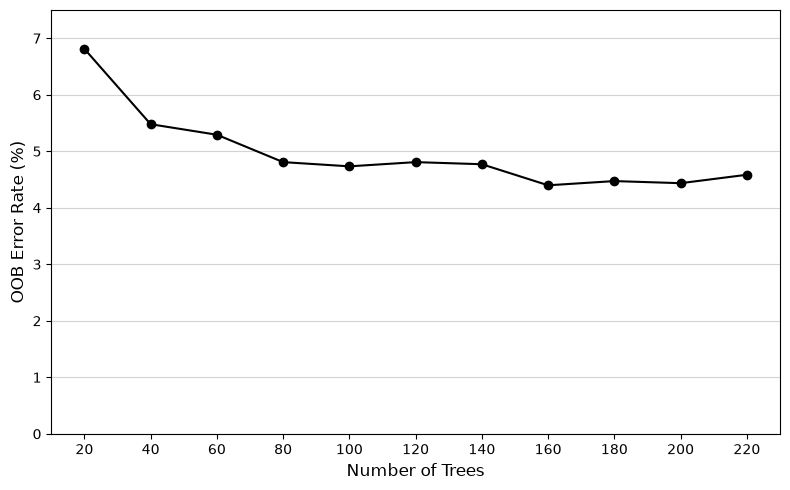

In [61]:
oob_df = pd.read_csv('output/RF_OOB_error_by_numTrees.csv')
# plt.rcParams["font.family"] = "Calibri"
plt.figure(figsize=(8, 5))
plt.plot(oob_df['numberOfTrees'], oob_df['oobError'], marker='o')
plt.xlabel('Number of Trees', fontsize=12)
plt.ylabel('OOB Error Rate (%)', fontsize=12)
plt.xticks(oob_df['numberOfTrees'])
plt.grid(True, axis='y', color='lightgrey')
plt.ylim(bottom=0, top=7.5)
plt.tight_layout()
plt.gca().lines[0].set_color('black')

# save as file for manuscript
plt.savefig('output/RF_OOB_error_by_numTrees.png', dpi=400)

plt.show()

In [62]:
# this gives f score for each class (hoop, mulch, other) (blackmulch combined now)
classacc = testAccuracy_RF.fscore().getInfo()
print('F1 score for each class:')
print(f'hoop: {classacc[0]*100:.2f}%')
print(f'mulch: {classacc[1]*100:.2f}%')
print(f'other: {classacc[2]*100:.2f}%')

F1 score for each class:
hoop: 91.02%
mulch: 88.93%
other: 88.48%


#### Confusion matrix

User's accuracy for each class:
hoop: 97.85%
mulch: 87.29%
other: 85.79%
Producer's accuracy for each class:
hoop: 85.07%
mulch: 90.62%
other: 91.35%


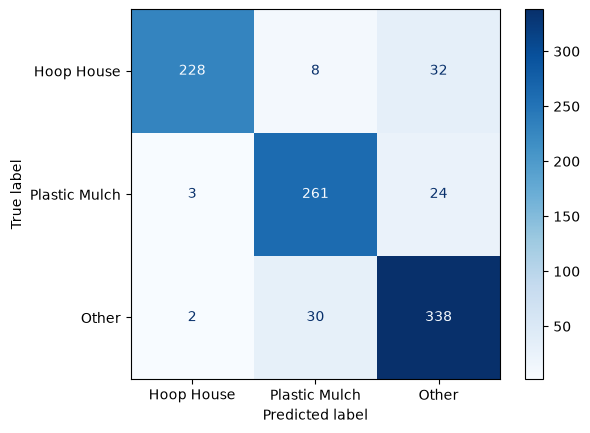

In [63]:
# Plot confusion matrix - commented out for speed 
# display_labels = ['hoop', 'mulch', 'other', 'blackmulch']
display_labels = ['Hoop House', 'Plastic Mulch', 'Other']

cm_RF = np.array(testAccuracy_RF.getInfo())
disp = ConfusionMatrixDisplay(confusion_matrix=cm_RF, display_labels=display_labels)
disp.plot(cmap=plt.cm.Blues)
# disp.ax_.set_title(f"RF Confusion Matrix ({testAccuracy_RF.accuracy().getInfo():.2%} Accuracy)")
# save as png
# plt.savefig('output/rf_confusion_matrix.png', dpi=400)

# users accuracy -- how often is a point classified as hoop actually hoop
usersacc = np.diag(cm_RF) / np.sum(cm_RF, axis=0)
print('User\'s accuracy for each class:')
print(f'hoop: {usersacc[0]*100:.2f}%')
print(f'mulch: {usersacc[1]*100:.2f}%')
print(f'other: {usersacc[2]*100:.2f}%')

# producers accuracy -- how often is an actual hoop point classified as hoop
producersacc = np.diag(cm_RF) / np.sum(cm_RF, axis=1)
print('Producer\'s accuracy for each class:')
print(f'hoop: {producersacc[0]*100:.2f}%')
print(f'mulch: {producersacc[1]*100:.2f}%')
print(f'other: {producersacc[2]*100:.2f}%')

#### Variable Importances

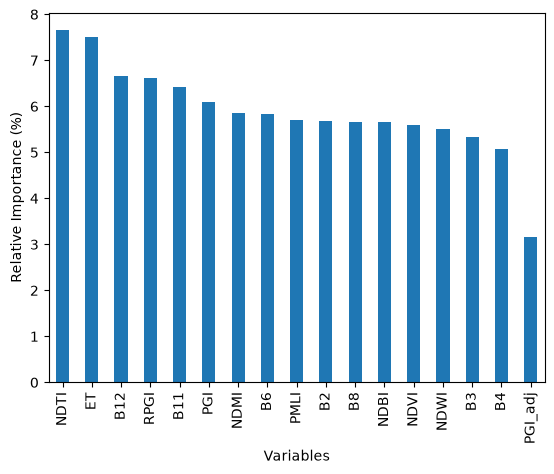

In [64]:
importance = ee.Dictionary(trained_RF.explain().get('importance'))

totalImportance = importance.values().reduce(ee.Reducer.sum())

# helper fn to map over importance values
def percentConvert(key, val):
    return ee.Number(val).divide(totalImportance).multiply(100)
relImportance = importance.map(percentConvert)

importanceFC = ee.FeatureCollection([ee.Feature(None, relImportance)])
# convert to pandas df
varImportance = ee_to_df_edit(importanceFC)
varImportance = varImportance.drop(columns=['geo'], errors='ignore')
varImportance = varImportance.transpose().rename(columns={0: 'Importance'})
varImportance = varImportance.sort_values(by='Importance', ascending=False)
varImportance

varImportance.plot(kind='bar', width=0.45)
plt.ylabel('Relative Importance (%)')
plt.xlabel('Variables')
plt.legend().set_visible(False)
plt.show()

## 5. Export the model

per [ee docs](https://developers.google.com/earth-engine/apidocs/export-classifier-toasset#colab-python), allows you to build larger models (i.e. more trees, more training samples)

but doesn't apply for the multiprobability output that we need for the main analysis

In [65]:
rf_asset_id = 'projects/ee-tnc-annietaylor/assets/agplastics/RF_classifier_v_1_4'
task = ee.batch.Export.classifier.toAsset(
    classifier=trained_RF,
    description='classifier_export',
    assetId=rf_asset_id
)
# task.start()

#### New crop mask
this is already resampled to the 30m grid to match s2 and ET data, using 75% pixel coverage of the 10m crop mask
this just converts it to a mask

In [66]:
crops = cropsResampled.where(cropsResampled, 1)
# this is the old crop mask
# crops = crops.where(crops, 1)

## 6. Apply standard classification model to imagery

In [67]:
# # bring in the saved classifiers
# rf_asset_id_v1_1 = 'projects/ee-tnc-annietaylor/assets/agplastics/RF_classifier_matched_ET_BM_o_nm_ox_all_trees_pgi'
# rf_asset_id = 'projects/ee-tnc-annietaylor/assets/agplastics/RF_classifier_v_1_2_s87'
# rf_asset_id_e = 'projects/ee-tnc-annietaylor/assets/agplastics/RF_classifier_v_1_2_embed'
# savedClassifier_v1_1 = ee.Classifier.load(rf_asset_id_v1_1)
savedClassifier = ee.Classifier.load(rf_asset_id)
# savedClassifier_e = ee.Classifier.load(rf_asset_id_e)

#### Get all images from one date, stitch them together, and center the map on that

In [68]:
# for a given date, get images from that date, stitch them together, and center the map on that
# great image to check: '2024-10-02', earth image date 9/30/2024 in Oxnard area: 
# https://earth.google.com/web/@34.22849791,-119.2434538,6.54306045a,5617.78356609d,35y,0h,0t,0r/data=ChYqEAgBEgoyMDI0LTA5LTMwGAFCAggBMikKJwolCiExMzlZMjlnZG9FSGVSeGRrT2FuLXZqaDdRdUZpcDVPdHQgAToDCgEwQgIIAEoICJej1LcCEAE

# for watsonville ground-truthing, use date = '2021-10-01' and Earth image date 9/30/2021
# https://earth.google.com/web/@36.90600071,-121.7366486,5.73571404a,18340.9275927d,35y,0h,0t,0r/data=ChIqEAgBEgoyMDIxLTA5LTMwGAE6AwoBMA
# for oxnard ground-truthing, use date = '2022-07-05' and Earth image date 6-30-2022
# https://earth.google.com/web/@34.18104511,-119.12299165,16.77976172a,20704.65705214d,35y,0h,0t,0r/data=ChIqEAgBEgoyMDIyLTA2LTMwGAE6AwoBMA
# for santa maria, use date = '2021-03-02' and Earth image date 2-28-2021
# https://earth.google.com/web/@34.92298797,-120.36568793,104.77571464a,20361.02485151d,35y,0h,0t,0r/data=ChIqEAgBEgoyMDIxLTAyLTI4GAE6AwoBMA
# for mendocino, use date = '2021-07-01' and Earth image date 6-30-2021 (have to also take off crop mask)
# https://earth.google.com/web/@39.49685652,-123.43778648,742.16477863a,4440.61517426d,35y,0h,0t,0r/data=ChIqEAgBEgoyMDIxLTA2LTMwGAE6AwoBMA

date = '2024-10-02'
nextday = ee.Date(date).advance(1, 'day').format('YYYY-MM-dd')
oneday = processedCollection.filterDate(date, nextday).median().setDefaultProjection(S2_projection)
oneday_original = s2.filterDate(date, nextday).median()

# # get ET data for the month of that date
# et_date = ee.Date(ee.Date(date).format('yyyy-MM-01')) #convert to first of month for ET data
# et_img = et.filterDate(et_date, et_date.advance(1, 'month')).median().rename('ET').setDefaultProjection(ET_projection)

# # get satellite embeddings for the year of that date
# embed_year = ee.Date(ee.Date(date).format('yyyy-01-01'))
# embed_img = embed.filterDate(embed_year, embed_year.advance(1, 'year')).mosaic()

# # # old workflow: add ET band to sentinel-2 image
# # oneday = oneday.addBands(et_img).addBands(embed_img)

# # new workflow: get them projected onto the same grid
# stacked = oneday.addBands(et_img) #.addBands(embed_img) if you need to test the satellite embeddings dataset
# # scale = 30, projection = ca teale albers (these are set above)
# stackedResampled = stacked.reduceResolution(
#   reducer = ee.Reducer.mean(),
#   maxPixels = 1024
# ).reproject(
#     crs = gridProjection
# )

# m = geemap.Map()
# m.addLayer(stackedResampled, {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 3000}, 'stacked resampled')
# m.centerObject(ventura, 10)
# # m


### Classify the image and add to map

In [69]:
# # classify the image
# classified = stackedResampled.classify(savedClassifier).updateMask(crops)
# # classified_v1_1 = stackedResampled.classify(savedClassifier_v1_1).updateMask(crops)
# # classified_e = stackedResampled.classify(savedClassifier_e).updateMask(crops)

# # Remap values for exporting and visualizing in arc pro
# remapped = classified.remap(
#   [0, 1, 2], # from values (hoop, mulch, other)
#   [1, 2, 3] # to values
# )
# # export the true color sentinel image oneday and the classified plastic image for figures
# # export_s2 = ee.batch.Export.image.toDrive(
# #     image=oneday.select('B4', 'B3', 'B2'),
# #     description='S2_10022024',
# #     fileNamePrefix='S2_10022024',
# #     folder='EarthEngine',
# #     scale=10,
# #     region=socal.geometry(),
# #     maxPixels=1e13
# # )
# # export_s2.start()

# # export_plastic = ee.batch.Export.image.toDrive(
# #     image=remapped,
# #     description='plastic',
# #     fileNamePrefix='classified_plastic_v1_2_10022024_remap',
# #     folder='EarthEngine',
# #     scale=10,
# #     region=socal.geometry(),
# #     maxPixels=1e13
# # )
# # export_plastic.start()

# # add the classified plastic and composite image to map
# m = geemap.Map()
# m.add_basemap('HYBRID')
# # m.addLayer(oneday_original, rgbVis, 'Full Sentinel: ' + date)
# # m.addLayer(oneday.select('RPGI'), RPGI_viz, 'RPGI', False)
# # m.addLayer(oneday.select('NDTI'), NDTI_viz, 'NDTI', False)
# m.addLayer(oneday, rgbVis, 'Cloudless Sentinel: ' + date)
# m.addLayer(classified, plastic_viz, 'Classified Plastic v1.2')
# # m.addLayer(classified_v1_1, plastic_viz, 'Classified Plastic v1.1', False) # old classification for comparison
# # m.addLayer(classified_e, plastic_viz, 'Classified Plastic Embedded', False) # embedded classifier for comparison
# m.addLayer(stackedResampled, rgbVis, 'Resampled Cloudless Sentinel + ET', False)
# m.centerObject(ca, 6)
# # m

In [70]:
# # print out the map legend
# # colors = ['#FF5733', '#F4F31D', '#2596be', '#333333']
# # labels = ['hoop', 'mulch', 'other', 'blackmulch']
# colors = ['#FF5733', '#F4F31D', '#2596be']
# labels = ['hoop house', 'plastic mulch', 'other']

# # Create a legend with the colors and labels
# patches = [plt.Rectangle((0, 0), 1, 1, color=color) for color in colors]
# plt.legend(patches, labels)

# plt.show()

### Multi-probability classifier

In [71]:
trained_prob_RF = ee.Classifier.smileRandomForest(numberOfTrees=100, bagFraction=0.8).setOutputMode('MULTIPROBABILITY').train(training, 'class', bands_tr)

classified_multi = stackedResampled.classify(trained_prob_RF).updateMask(crops)

# Extract the probabilities for each cover type
probabilities = classified_multi.arrayFlatten([['hoop', 'mulch', 'other']])

m = geemap.Map()
# m.add_basemap('HYBRID')
m.addLayer(oneday_original, rgbVis, 'Full Sentinel: ' + date)
m.addLayer(oneday, rgbVis, 'Cloudless Sentinel: ' + date, False)
m.addLayer(stackedResampled, rgbVis, 'Resampled Cloudless Sentinel + ET', False)
m.addLayer(classified_multi, {}, 'Raw output', False)
m.addLayer(probabilities, {}, 'Classified Probabilities')
m.centerObject(ca, 6)
# m

## 7. Time series of plastic probability 
commented out for speed, don't need this for model runs

#### Set date range

In [72]:
# # write a start date and the number of images you'd like to sample
# # images are captured every 5 days in a given place
# # if you start at beginning of WY 2022 (10.1.21), you'll be in the Watsonville area
# # if you start at beginning of WY 2022 (10.3.21), you'll get Santa Maria and Oxnard areas
# first_date = '2023-10-03'
# first_date = datetime.strptime(first_date, '%Y-%m-%d')
# days_bt = 5 # multiples of 5 ensure the images will land in the same place in CA
# num_dates = 73 # 365/5

# dates = []
# for i in range(num_dates):
#     new_date = first_date + timedelta(days=i*days_bt)
#     dates.append(new_date.strftime('%Y-%m-%d'))

# if '2022-08-19' in dates: dates.remove('2022-08-19') #causes an error with lt 92% cloud cover
# if '2021-12-22' in dates: dates.remove('2021-12-22') #causes an error with lt 30% cloud cover
# if '2023-01-04' in dates: dates.remove('2023-01-04')
# dates

# # six days spread out through the year, I think they will all cover the watsonville area
# # best to have these separated by 5 days if you'd like to stay in one area
# # dates = ['2021-01-04', '2021-03-15', '2021-05-24', '2021-08-02', '2021-10-11', '2021-12-20']

#### Create time series for those dates with sentinel and ET

In [73]:
# timeseries = ee.ImageCollection([])
# # didn't add the reprojecting here because it causes a memory error

# for date in dates:
#     nextday = ee.Date(date).advance(1, 'day').format('YYYY-MM-dd')
#     oneday = processedCollection.filterDate(date, nextday).median()#.setDefaultProjection(S2_projection)
#     oneday_original = s2.filterDate(date, nextday).median()

#     # get ET data for the month of that date
#     et_date = ee.Date(ee.Date(date).format('yyyy-MM-01')) #convert to first of month for ET data
#     et_img = et.filterDate(et_date, et_date.advance(1, 'month')).median().rename('ET')#.setDefaultProjection(ET_projection)

#     # add ET band to sentinel-2 image
#     oneday = oneday.addBands(et_img).set('date', date)

#     # add each image to the collection
#     timeseries = timeseries.merge(ee.ImageCollection([oneday]))

# # if you get an error while running the classifier on the whole TS, print the collection and check 
# #   for images that don't have S2 bands. Then remove them from the dates list above
# # display(timeseries)


#### Classify probability for each class across each image

In [74]:
# # classify each image in the timeseries collection
# def classify_image(image):
#     date = image.get('date')
#     classified_multi = image.classify(trained_prob_RF).updateMask(crops)
#     probabilities = classified_multi.arrayFlatten([['hoop', 'mulch', 'other']])
#     return probabilities.set('date', date)

# classified_timeseries = timeseries.map(classify_image)

# # display(classified_timeseries)


#### Display the result and draw a geometry for the time series analysis

In [75]:
# # point used for data in figure 2
# point = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/sample_mulch_point_2_wy23')
# # get the dwr fields for wy 2023
# fields_wy23 = ee.FeatureCollection(f'projects/ee-tnc-annietaylor/assets/agplastics/DWR_2023_filtered_wgs')
# fields_wy24 = ee.FeatureCollection(f'projects/ee-tnc-annietaylor/assets/agplastics/DWR_2024_all_wgs')


# Map = geemap.Map()
# Map.add_basemap('HYBRID')
# # Map.addLayer(oneday, rgbVis, 'Cloudless Sentinel: ' + date) #adds last image from the for loop
# # hoop = red, mulch = green, blue = other
# Map.addLayer(classified_timeseries.median(), {'min': 0, 'max': 1.0}, 'Classified Probabilities')
# Map.addLayer(point, {'color': 'purple'}, 'Sample Point', False)
# vis_params = {
#     'color': 'white',
#     'fillColor': '00000000',
# }
# # Map.addLayer(fields_wy23.style(**vis_params), {}, "DWR Fields WY23", False)
# Map.addLayer(fields_wy24.style(**vis_params), {}, "DWR Fields WY24", False)
# # pixels = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/sample_mulch_7points_wy23')
# # Map.addLayer(pixels, {'color': 'yellow'}, 'Sample Points WY23')
# Map.centerObject(ca, 10)
# Map

In [76]:
# # # If you need, export the region to your assets
# region = ee.Feature(Map.draw_last_feature)
# task = ee.batch.Export.table.toAsset(
#     collection=ee.FeatureCollection(region),
#     description='region_export',
#     assetId='projects/ee-tnc-annietaylor/assets/agplastics/santamaria_mulch_wy24'
# )
# task.start()

# # # export all drawn points to one feature collection asset
# # # user_rois = fc containing all drawn features
# # fc_pts = Map.user_rois

# # display(fc_pts)
# # # Map.addLayer(fc_pts, {"color": "red"}, "drawn points")
# # # Map

# # task = ee.batch.Export.table.toAsset(
# #     collection=fc_pts,
# #     description='Export drawn points to asset',
# #     assetId='projects/ee-tnc-annietaylor/assets/agplastics/sample_mulch_7points_wy23'
# # )
# # task.start()

In [77]:
# # to get prob of all three classes of the 10-21-2021 image at each of the test points 
# pixels = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/sample_mulch_7points_wy23')
# first_img = classified_timeseries.filter(ee.Filter.eq('date', '2022-10-21')).first()

# # sample the 10-21-2021 image at each point
# first_img_values = first_img.sampleRegions(
#     collection=pixels,
#     scale=10
# )
# df = ee_to_df_edit(first_img_values)
# display('first image values at points', df.round(2))


# # also sample the 95th percentile value of each class for wy22 
# per_image = ee.Image('projects/ee-tnc-annietaylor/assets/agplastics/PlasticClassP95_SantaCruzCo_WY2023_v1_3')

# per_image_values = per_image.sampleRegions(
#     collection=pixels,
#     scale=10
# )
# df_per = ee_to_df_edit(per_image_values)
# display('95th percentile values at points', df_per.round(2))

#### Create df with each class probability across an image collection for a region
this runs slowly so I'm commenting it + next block out for now

In [78]:
# # # convert the last drawn feature from map above to an ee.Feature
# # region = ee.Feature(Map.draw_last_feature)

# # can also import a good example feature from assets
# # this one only works when you're using a date seq that intersects santa maria region
# # region = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/SM_test_field').first()
# # region = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/sample_mulch_point_2_wy23').first()
# # region = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/sample_mulch_point_wy24').first()
# region = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/santamaria_mulch_wy24').first()


# def RR_all_features(image):
#     # this is a dictionary
#     means_dict = image.reduceRegion(ee.Reducer.mean(), region.geometry(), 30)
#     # add the image date to the ee.Dictionary
#     means_dict = means_dict.set('date', image.get('date'))
#     feat = ee.Feature(None, means_dict)
#     return feat

# result = ee.FeatureCollection(classified_timeseries.map(RR_all_features))

# df = ee_to_df_edit(result)
# df
# # print out number of null values in each column
# # df.isnull().sum() # 15 nulls for cloudiness lte 30%. 7 nulls for cloudiness lt 92%. 

#### Intra-annual charts
I want three charts showing typical temporal patterns:
- mulch: mulch is applied and then crops grow over it through spring
- hoop house: high prob of hoop house the whole WY
- other: mostly other, but a few noisy observations of mulch/hoop that get filtered out by our algo
- OR double application of mulch? Need to check for fields that do this

#### Charts for figures
Exported as svg and imported into illustrator 

In [79]:
# # Convert the date column to datetime values
# df['dateT'] = pd.to_datetime(df['date'])

# # get 95th percentile value for each class 
# hoop_95 = df['hoop'].quantile(0.95)
# mulch_95 = df['mulch'].quantile(0.95)
# other_95 = df['other'].quantile(0.95)

# # add horizontal lines for 95th percentiles
# plt.axhline(y=hoop_95, color='#D55E00', linestyle='--', linewidth=1, label='Hoop 95th Percentile')
# plt.axhline(y=mulch_95, color='#F0E442', linestyle='--', linewidth=1, label='Mulch 95th Percentile')
# # plt.axhline(y=other_95, color='#94D9FF', linestyle='--', linewidth=1, label='Other 95th Percentile')

# # line chart layered with points for clarity
# plt.plot(df['dateT'], df['hoop'], 'o', color='#D55E00', label='Hoop')
# plt.plot(df['dateT'], df['mulch'], 'o', color='#F0E442', label='Mulch')
# plt.plot(df['dateT'], df['other'], 'o', color='#94D9FF', label='Other')
# # plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
# # plt.legend(loc='best')

# # Set x-axis to show only month-year labels
# plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
# plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b-%Y'))

# # set y axis to go to 1.0
# plt.ylim(0, 1.0)

# # labels & font sizes
# plt.xticks(rotation=40, ha='right', fontsize=12)
# plt.yticks(fontsize=12)
# plt.xlabel('Date', fontsize=15)
# plt.ylabel('Probability', fontsize=15)

# # grid lines
# # plt.grid(axis='y', color='lightgray', linestyle='-', linewidth=0.5)
# # plt.grid(axis='x', color='lightgray', linestyle='-', linewidth=0.5)

# plt.rcParams['font.family'] = 'Calibri'

# # save as svg
# # plt.savefig('output/class_probabilities_singlemulch24_pt.svg', format='svg', bbox_inches='tight', dpi=500)

# plt.show()

# # get the first row of the df where hoop is non-null
# first = df[df['hoop'].notnull()].head(1)

# # print out the hoop, mulch, other values for that date
# print(f"Hoop first value: {first['hoop'].values[0]:.2f}")
# print(f"Mulch first value: {first['mulch'].values[0]:.2f}")
# print(f"Other first value: {first['other'].values[0]:.2f}")

# # print the three 95th percentile values
# print(f"Hoop 95th Percentile: {hoop_95:.2f}")
# print(f"Mulch 95th Percentile: {mulch_95:.2f}")
# print(f"Other 95th Percentile: {other_95:.2f}")

#### Chart the time series

In [80]:
# # Convert the date column to datetime values
# df['dateT'] = pd.to_datetime(df['date'])

# # line chart layered with points for clarity
# wy_title = first_date.year + 1
# # plt.title(f"Plastic Probability over WY {wy_title}, starting on {first_date.date()}")
# plt.title(f"Class Probabilities over WY {wy_title}")
# plt.plot(df['dateT'], df['hoop'], '-o', color='#D55E00', label='Hoop')
# plt.plot(df['dateT'], df['mulch'], '-o', color='#F0E442', label='Mulch')
# plt.plot(df['dateT'], df['other'], '-o', color='#94D9FF', label='Other')
# # plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
# # Custom legend with dark background and light text
# legend = plt.legend(loc='best', frameon=True, facecolor='#333333', edgecolor='white')
# for text in legend.get_texts():
#     text.set_color('white')
# plt.grid(axis='x', color='darkgray', linestyle='-', linewidth=0.5)
# # plt.axhline(y=0.5, color='yellow', linestyle='--', linewidth=1) # lines to show the threshold for plastic
# # plt.axhline(y=0.6, color='red', linestyle='--', linewidth=1)

# # Set x-axis to show only month-year labels
# plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
# plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b-%Y'))

# plt.xticks(rotation=40, ha='right', fontsize=8)
# plt.gcf().set_facecolor("#424242")
# plt.gca().set_facecolor('#424242')
# plt.grid(axis='y', color='darkgray', linestyle='-', linewidth=0.5)
# plt.tick_params(colors='white')
# plt.xlabel('Date', color='white')
# plt.ylabel('Probability', color='white')
# plt.title(f"Class Probabilities, WY {wy_title}", color='white')
# plt.rcParams['font.family'] = 'Calibri'
# plt.show()

# # save as svg
# # plt.savefig('output/class_probabilities.svg', format='svg', bbox_inches='tight', facecolor=plt.gcf().get_facecolor())

## 8. Classify all images in a year across a county

In [81]:
# grab all sentinel images in a time period (cloud filtered)
# set the water year and county of interest
wy = 2025
county = cruz # ventura, mendo, cruz, santabarbara, sanbenito, humboldt
# get text name of county
county_name = county.first().get('NAME').getInfo().replace(" ", "")

# # for exporting across the county line in watsonville
# wats_region = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/watsonville_region').first()
# county = wats_region.geometry() 
# county_name = 'Watsonville'  

# create dates
stdate = f'{wy-1}-10-01'
endate = f'{wy}-10-01' # end date is exclusive

# ~24 images per day across CA, ~169 images to cover CA over 5 days
# ~256 images per year in santa cruz county
sentinel_ts = processedCollection.filterDate(stdate, endate).filterBounds(county) #if statewide, comment out filterBounds
print(f'Plastic classification for {county_name} County in water year {wy}')
# if statewide, use this line instead
# print(f'Plastic classification for the state of California in water year {wy}')
print('Number of images: ', sentinel_ts.size().getInfo())

# then add corresponding ET data for each month (map over collection)
def add_ET(image):
    image_sts = image.get('system:time_start')
    date = image.date()
    et_date = ee.Date(ee.Date(date).format('yyyy-MM-01')) #convert to first of month for ET data
    et_img = et.filterDate(et_date, et_date.advance(1, 'month')).median().rename('ET').setDefaultProjection(ET_projection)
    image.setDefaultProjection(S2_projection) #have to define the other band's projections too when stacking
    return image.addBands(et_img).set('system:time_start', image_sts)

sentinel_ts_ET = sentinel_ts.map(add_ET)

# RESAMPLE/REPROJECT 
# Choose the grid size and projection
gridScale = 30
# CA teale albers = applicable to all CA
gridProjection = ee.Projection('EPSG:3310').atScale(gridScale)
# UTM zone 11 = socal
# gridProjection = ee.Projection('EPSG:32611').atScale(gridScale)

# then classify each image (map over collection)
# this function also reprojects the image to the grid
def classify_image_2(image):
    image_sts = image.get('system:time_start') # enables filterDate functionality
    date = image.get('date')
    # not included here, could set resampling method to bilinear
    image.reduceResolution(reducer = ee.Reducer.mean()).reproject(crs = gridProjection)
    classified_multi = image.classify(trained_prob_RF).updateMask(crops)
    probabilities = classified_multi.arrayFlatten([['hoop', 'mulch', 'other']])
    return probabilities.set('date', date).set('system:time_start', image_sts)

classified_timeseries = sentinel_ts_ET.map(classify_image_2)

Plastic classification for SantaCruz County in water year 2025
Number of images:  312


#### Get top percentile value

In [82]:
# create a mosaic for one day and add to map for testing

# either by testing a date
# date = '2022-01-20'
# nextday = ee.Date(date).advance(1, 'day').format('YYYY-MM-dd')
# classified = classified_timeseries.filterDate(date, nextday).median()

# or taking the entire collection
count = sentinel_ts.count()
classified = classified_timeseries.reduce(ee.Reducer.percentile([95])).select(['hoop_p95', 'mulch_p95'])
# classifiedmask = classified.gt(0.75)
sentinel_image = sentinel_ts.median()

# Get the max and min pixel value of the count image, to get a sense of the range of how many images cover each pixel
count_min = count.select('B1').reduceRegion(ee.Reducer.min(), county.geometry(), 800).getInfo()
count_max = count.select('B1').reduceRegion(ee.Reducer.max(), county.geometry(), 800).getInfo()
# print('Min number of images at a pixel:', count_min)
# print('Max number of images at a pixel:', count_max)

# # add to map
# ca_outline = ee.FeatureCollection(ca).style(fillColor='00000000')
# m = geemap.Map()
# m.add_basemap('HYBRID')
# m.addLayer(sentinel_image, rgbVis, 'Cloudless Sentinel', False)
# m.addLayer(classified, {}, 'Classified Probabilities', False)
# m.addLayer(count.select('B1'), {'min': 0, 'max': 400}, 'Number of Images')
# m.addLayer(ca_outline, {}, 'California')
# m.centerObject(ca, 6)
# m

#### Comparing the two bands to get integrated raster
i.e. if a pixel is classified as mulch and hoop, use difference from threshold to determine which class it is

In [83]:
def integrate_classes(image):
    # Define my thresholds for each band
    bh_th = 0.5
    bm_th = 0.5

    # Define the two bands you want to compare
    # input image is classified, has a hoop_p95 and mulch_p95 band
    bh = image.select('hoop_p95')
    bm = image.select('mulch_p95')

    # difference from threshold for each
    bh_diff = bh.subtract(bh_th).rename('bh_diff')
    bm_diff = bm.subtract(bm_th).rename('bm_diff')

    class_band = image.expression(
        # "bh_gt >= 0 ? 1 : (bm_gt >= 0 ? 2 : 0)", # super simple version
        # if bh if gte threshold, class = 1 (hoop)
        # if bm if gte threshold, class = 2 (mulch)
        # if bh and bm are both under threshold, class = 0 (other)
        # this is the more complex version that takes into account the difference from the threshold
        # if bh_diff = bm_diff, classify it as hoop (1)
        "(bh_diff >= 0 && (bm_diff < 0 || bh_diff >= bm_diff)) ? 1 : ((bm_diff >= 0 && (bh_diff < 0 || bm_diff > bh_diff)) ? 2 : 0)",
        {
            # 'bh_gt': bh_gt, # these are 0 or 1
            # 'bm_gt': bm_gt, # 0 or 1
            'bh_diff': bh_diff,
            'bm_diff': bm_diff
        }
    ).rename('class')
    return image.addBands(class_band)

classified_integrated = integrate_classes(classified)
# if statewide, comment out clip below
classes = classified_integrated.select('class').updateMask(crops).clip(county)

# # Add the results to the map
# m = geemap.Map()
# m.add_basemap = 'SATELLITE'
# m.addLayer(classified, {}, 'Classified Probabilities', False)
# m.addLayer(classes, {'min': 0, 'max': 2, 'palette': ['blue', 'red', 'yellow']}, 'Final Classes')
# m.centerObject(sanmateo, 6)
# m

#### Export the masked, unmasked probability image OR integrated image

I'm not using this, mostly using 8.1

In [84]:
# export probability raster to asset (mostly for testing)
export_task = ee.batch.Export.image.toAsset(
    image=classified, # this is all exported probabilities
    description=f'classes_image_{county_name}_{wy}',
    assetId=f'projects/ee-tnc-annietaylor/assets/agplastics/PlasticClassP95_{county_name}Co_WY{wy}_v1_4',
    region=county.geometry(),
    scale=30,
    maxPixels=1e13
)
# export_task.start()

# export integrated raster to drive 
export_task = ee.batch.Export.image.toDrive(
    # image=classified, # this is all exported probabilities
    image=classes, # this is the integrated class
    description=f'classes_image_{county_name}_{wy}',
    fileNamePrefix=f'PlasticClass_{county_name}Co_WY{wy}_v1_4',
    folder='EarthEngine',
    region=county.geometry(),
    scale=30,
    maxPixels=1e13,
    crs = 'EPSG:3310' # CA teale albers
)
# export_task.start()

#### 8.1 Export all waters years for one county 

In [85]:
# county of interest
county = ventura # cruz, monterey, slo, santabarbara, ventura
# get text name of county
county_name = county.first().get('NAME').getInfo().replace(" ", "")

wys = [2019, 2020, 2021, 2022, 2023, 2024, 2025]
# wys = [2025]

for wy in wys:
    stdate = f'{wy-1}-10-01'
    endate = f'{wy}-10-01' # end date is exclusive
    sentinel_ts = processedCollection.filterDate(stdate, endate).filterBounds(county)
    print(f'Plastic classification for {county_name} County in water year {wy}. Images = ', sentinel_ts.size().getInfo())
    # add corresponding ET data for each month (map over collection)
    sentinel_ts_ET = sentinel_ts.map(add_ET)
    # then classify each image (map over collection)
    classified_timeseries = sentinel_ts_ET.map(classify_image_2) #incorporates reprojection to grid
    # get the 95 percentile values of that time series
    classified = classified_timeseries.reduce(ee.Reducer.percentile([95])).select(['hoop_p95', 'mulch_p95'])
    # combine hoop and mulch classes based on distance above respective thresholds
    classified_integrated = integrate_classes(classified)
    # mask to crops and clip to county
    classes = classified_integrated.select('class').updateMask(crops).clip(county)
    # export integrated raster to drive or asset
    export_tif = ee.batch.Export.image.toDrive(
        image=classes,
        description=f'classes_image_{county_name}_{wy}',
        fileNamePrefix=f'PlasticClass_{county_name}Co_WY{wy}_v1_4',
        folder='EarthEngine',
        region=county.geometry(),
        scale=30,
        maxPixels=1e13,
        crs = 'EPSG:3310' # CA teale albers
    )
    export_asset = ee.batch.Export.image.toAsset(
        image=classes,
        description=f'AssetExport_PlasticClass_{county_name}_{wy}',
        assetId=f'projects/ee-tnc-annietaylor/assets/agplastics/PlasticClass_{county_name}Co_WY{wy}_v1_4',
        region=county.geometry(),
        scale=30,
        maxPixels=1e13,
        crs = 'EPSG:3310' # CA teale albers
    )
    # export_tif.start()
    # export_asset.start()
print('Exporting images to assets')

Plastic classification for Ventura County in water year 2019. Images =  642
Plastic classification for Ventura County in water year 2020. Images =  652
Plastic classification for Ventura County in water year 2021. Images =  656
Plastic classification for Ventura County in water year 2022. Images =  663
Plastic classification for Ventura County in water year 2023. Images =  610
Plastic classification for Ventura County in water year 2024. Images =  626
Plastic classification for Ventura County in water year 2025. Images =  720
Exporting images to assets


#### 8.2 Export month combinations to make validation data
commented out, not using

In [86]:
# # how many days centered around each training data point to include?
# period = 366 # total days before + after the training data point to include in classification

# # any period under 55 days will work on the fly
# # or you can import assets for these periods: 60, 120, 240, 366

# # Create a set of (location, date) pairs for training data I'm using
# location_date_pairs = {
#     ("Watsonville", "2023-04-12"),
#     ("Oxnard", "2023-05-06"),
#     ("Santa Maria", "2023-05-05"),
#     ("Oxnard", "2022-10-01"),
#     ("Oxnard", "2022-11-01"),
#     ("Watsonville", "2022-09-11"),
# }

# # Function to filter the df based on location and date
# def filter_by_location_date(location, date):
#     df = all_data_test
#     year_month = date[0:7]
#     return df[(df['Location'] == location) & (df['Date'].str.startswith(year_month))]

# def classify_plastic_at_location_date(location, date, period):
#     # get the training points for that location and date
#     filtered_data = filter_by_location_date(location, date)
#     # print(f"{filtered_data.shape[0]} total training points in {location} on {date}")
#     # get the county for that location
#     if location == "Watsonville":
#         county, county_name = cruz, 'Santa Cruz'
#     elif location == "Oxnard":
#         county, county_name = ventura, 'Ventura'
#     elif location == "Santa Maria":
#         county, county_name = santabarbara, 'Santa Barbara'
#     else:
#         print(f"Location {location} not recognized, need a county to filter by.")
    
#     # get the start and end dates for the imagery 
#     start_date = pd.to_datetime(date) - pd.Timedelta(days=period // 2)
#     end_date = pd.to_datetime(date) + pd.Timedelta(days=(period // 2) +1) # adding 1 bc end date is exclusive

#     # filter the timeseries collection for that location and date
#     sentinel_ts = processedCollection.filterDate(start_date, end_date).filterBounds(county)
#     # print(f'Classifying plastic in {county_name} County from {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')}, period of {period} days')
#     # print(f'Number of images = ', sentinel_ts.size().getInfo())
#     # add corresponding ET data for each month
#     sentinel_ts_ET = sentinel_ts.map(add_ET)
#     # then classify each image (map over collection)
#     classified_timeseries = sentinel_ts_ET.map(classify_image_2)
#     # get the 95 percentile values of that time series
#     classified = classified_timeseries.reduce(ee.Reducer.percentile([95])).select(['hoop_p95', 'mulch_p95'])
#     # combine hoop and mulch classes based on distance above respective thresholds
#     classified_integrated = integrate_classes(classified)
#     # mask to crops and clip to county
#     classes = classified_integrated.select('class').updateMask(crops).clip(county)
#     # convert filtered_data DataFrame to an ee.FeatureCollection
#     features = [
#         ee.Feature(
#             ee.Geometry.Point(row['Longitude'], row['Latitude']),
#             {
#                 'Type': row['Type'],
#                 'Date': row['Date'],
#                 'Location': row['Location']
#             }
#         )
#         for _, row in filtered_data.iterrows()
#     ]
#     points_fc = ee.FeatureCollection(features)
#     # sample the classified image at those points
#     sampled_points = classes.sampleRegions(
#         collection=points_fc,
#         scale=10
#     )
#     # return sampled_points
#     # convert results to pandas df
#     sampled_df = ee_to_df_edit(sampled_points)
#     # print(f"{sampled_df.shape[0]} training points sampled in {location} on {date} \n")
#     # Map class values: 0 = other, 1 = hoop, 2 = mulch
#     class_map = {0: 'other', 1: 'hoop', 2: 'mulch'}
#     sampled_df['class'] = sampled_df['class'].map(class_map)
#     return sampled_df
#     # export the sampled points for each location/date to separate csv files
#     # file_name = f"output/{location}_{date.replace('-', '')}_{period}day_period.csv"
#     # sampled_df.to_csv(sampled_df, file_name, index=False)
#     # print(f"Exported sampled points to {file_name}")

# def extract_plastic_at_location_date(location, date, period):
#     # useful for periods longer than 55 days, the function above times out
#     # get the training points for that location and date
#     filtered_data = filter_by_location_date(location, date)
#     # print(f"{filtered_data.shape[0]} total training points in {location} on {date}")
#     # get the county for that location
#     if location == "Watsonville":
#         county, county_name = cruz, 'SantaCruz'
#     elif location == "Oxnard":
#         county, county_name = ventura, 'Ventura'
#     elif location == "Santa Maria":
#         county, county_name = santabarbara, 'SantaBarbara'
#     else:
#         print(f"Location {location} not recognized, need a county to filter by.")
#     # import relevant asset 
#     classes = ee.Image(f'projects/ee-tnc-annietaylor/assets/agplastics/PlasticClass_{county_name}Co_{date.replace("-", "")}_{period}day_period_v1_1')
#     # convert filtered_data DataFrame to an ee.FeatureCollection
#     features = [
#         ee.Feature(
#             ee.Geometry.Point(row['Longitude'], row['Latitude']),
#             {
#                 'Type': row['Type'],
#                 'Date': row['Date'],
#                 'Location': row['Location']
#             }
#         )
#         for _, row in filtered_data.iterrows()
#     ]
#     points_fc = ee.FeatureCollection(features)
#     # sample the classified image at those points
#     sampled_points = classes.sampleRegions(
#         collection=points_fc,
#         scale=10
#     )
#     # return sampled_points
#     # convert results to pandas df
#     sampled_df = ee_to_df_edit(sampled_points)
#     # print(f"{sampled_df.shape[0]} training points sampled in {location} on {date} \n")
#     # Map class values: 0 = other, 1 = hoop, 2 = mulch
#     class_map = {0: 'other', 1: 'hoop', 2: 'mulch'}
#     sampled_df['class'] = sampled_df['class'].map(class_map)
#     return sampled_df

# def combine_sampled_data(location_date_pairs, period):
#     # Combine sampled data for multiple location-date pairs into a single df
#     all_dfs = [] 
#     for location, date in location_date_pairs:
#         # df = classify_plastic_at_location_date(location, date, period) # on the fly for shorter periods
#         df = extract_plastic_at_location_date(location, date, period) # pulls from asset for longer periods
#         all_dfs.append(df)
#     return pd.concat(all_dfs, ignore_index=True)


# # def combined_sampled_fc(location_date_pairs, period):
# #     # Combine sampled data for multiple location-date pairs into a single FeatureCollection
# #     all_features = ee.FeatureCollection()
# #     for location, date in location_date_pairs:
# #         sampled_points = classify_plastic_at_location_date(location, date, period)
# #         all_features.merge(sampled_points)
# #     return ee.FeatureCollection(all_features)
    
# # all_sampled_data = combined_sampled_fc(location_date_pairs, period)


# # this part actually runs something, not just fn set up
# # all_sampled_data = combine_sampled_data(location_date_pairs, period)

# # # export the combined sampled data to a csv file
# # output_file = f"output/test_data_{period}day_period.csv"
# # all_sampled_data.to_csv(output_file, index=False)
# # print(f"Exported all sampled data to {output_file}")

##### Run this workflow on a list of period values, and compare total and class accuracy values

In [87]:
# # all_sampled_data = combine_sampled_data(location_date_pairs, period)
# period = 60
# all_sampled_data = pd.read_csv(f'output/validation_data_{period}day_period.csv')
# all_sampled_data

# def accuracy_assessment(all_sampled_data):
#     # Calculate the accuracy of the classification
#     cm = confusion_matrix(all_sampled_data['Type'], all_sampled_data['class'], labels=['hoop', 'mulch', 'other'])
#     accuracy = np.trace(cm) / np.sum(cm)
#     # Save overall accuracy and class accuracies to a new df
#     class_accuracies = [cm[i, i] / np.sum(cm[i, :]) for i in range(len(['hoop', 'mulch', 'other']))]
#     acc_df = pd.DataFrame({
#         'class': ['overall', 'hoop', 'mulch', 'other'],
#         'accuracy': [accuracy] + class_accuracies
#     })
#     return acc_df

# def accuracy_assessment_szn(all_sampled_data):
#     # Calculate the accuracy of the classification for each season
#     seasons = {
#         'Spring': ['03', '04', '05'],
#         'Summer': ['06', '07', '08'],
#         'Fall': ['09', '10', '11'],
#         'Winter': ['12', '01', '02']
#     }
#     results = []
#     for season, months in seasons.items():
#         # Compare months to the [5:7] index of the date string to get the season
#         season_data = all_sampled_data[all_sampled_data['Date'].str[5:7].isin(months)]
#         if not season_data.empty:
#             cm = confusion_matrix(season_data['Type'], season_data['class'], labels=['hoop', 'mulch', 'other'])
#             accuracy = np.trace(cm) / np.sum(cm)
#             class_accuracies = [cm[i, i] / np.sum(cm[i, :]) for i in range(len(['hoop', 'mulch', 'other']))]
#             results.append({
#                 'season': season,
#                 'overall_accuracy': accuracy,
#                 'hoop_accuracy': class_accuracies[0],
#                 'mulch_accuracy': class_accuracies[1],
#                 'other_accuracy': class_accuracies[2]
#             })
#     return pd.DataFrame(results)

# print(accuracy_assessment_szn(all_sampled_data))

# # # confusion matrix compare actual (type) to predicted (class_april23)
# # cm = confusion_matrix(all_sampled_data['Type'], all_sampled_data['class'], labels=['hoop', 'mulch', 'other'])
# # # Plot the confusion matrix using seaborn heatmap
# # plt.figure(figsize=(8, 6))
# # sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['hoop', 'mulch', 'other'], yticklabels=['hoop', 'mulch', 'other'])
# # plt.title('Confusion Matrix')
# # plt.xlabel('Predicted')
# # plt.ylabel('Actual')
# # plt.show()
# # accuracy = np.trace(cm) / np.sum(cm)

# # print(f'{all_sampled_data.shape[0]} training points')
# # print(f'Overall accuracy: {accuracy:.2f}')
# # # print the accuracy for each class
# # for i, label in enumerate(['hoop', 'mulch', 'other']):
# #     class_accuracy = cm[i, i] / np.sum(cm[i, :])
# #     print(f'{label} accuracy: {class_accuracy:.2f}')

#### Plot accuracy vs period by season

In [88]:
# all_dfs = []

# for x in [16, 30, 50, 60, 120, 240, 366]: #have to add to this as I export more data
#     file = f"output/validation_data_{x}day_period.csv"
#     df = pd.read_csv(file)
#     acc_df = accuracy_assessment_szn(df)
#     acc_df['period'] = x
#     all_dfs.append(acc_df)

# df = pd.concat(all_dfs, ignore_index=True)

# display(df)

# metrics = ['overall_accuracy', 'hoop_accuracy', 'mulch_accuracy', 'other_accuracy']
# seasons = df['season'].unique()

# fig, axs = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
# axs = axs.flatten()

# for idx, metric in enumerate(metrics):
#     ax = axs[idx]
#     for season in seasons:
#         season_df = df[df['season'] == season]
#         ax.plot(season_df['period'], season_df[metric], marker='o', label=season)
#     ax.set_title(metric.replace('_', ' ').capitalize())
#     ax.set_xlabel('Period (days)')
#     ax.set_ylabel('Accuracy')
#     ax.set_ylim(0, 1)
#     ax.legend()
#     ax.grid(True)

# plt.tight_layout()
# plt.show()

##### Plot accuracy vs period
Using existing exported csvs, see code block right under 8.2

In [89]:
# all_dfs = []

# for x in [16, 30, 50, 60, 120, 240, 366]: #have to add to this as I export more data
#     file = f"output/validation_data_{x}day_period.csv"
#     df = pd.read_csv(file)
#     acc_df = accuracy_assessment(df)
#     # transpose the df
#     acc_df = acc_df.set_index('class').T
#     acc_df['period'] = x
#     all_dfs.append(acc_df)

# df = pd.concat(all_dfs, ignore_index=True)
# display(df)

# plt.figure(figsize=(8, 5))
# fields = ['overall', 'hoop', 'mulch', 'other']
# for field in fields:
#     plt.plot(df['period'], df[field], marker='o', label=field)
# plt.xlabel('Period (days)')
# plt.ylabel('Accuracy')
# plt.title('Accuracy by Period for Each Class')
# plt.ylim(0, 1)
# plt.legend()
# plt.grid(True, linestyle='--', alpha=0.5)
# plt.show()

##### Export images to asset for validation data
This is needed for the periods greater than ~55 days. Once exported, you can run code above to get csvs exported, then imported into the chart. 

In [90]:
# period = 366

# location_date_pairs = {
#     ("Watsonville", "2023-04-12"),
#     ("Oxnard", "2023-05-06"),
#     ("Santa Maria", "2023-05-05"),
#     ("Oxnard", "2022-10-01"),
#     ("Oxnard", "2022-11-01"),
#     ("Watsonville", "2022-09-11"),
# }

# def export_plastic_at_location_date(location, date, period):
#     # get the county for that location
#     if location == "Watsonville":
#         county, county_name = cruz, 'Santa Cruz'
#     elif location == "Oxnard":
#         county, county_name = ventura, 'Ventura'
#     elif location == "Santa Maria":
#         county, county_name = santabarbara, 'Santa Barbara'
#     else:
#         print(f"Location {location} not recognized, need a county to filter by.")
    
#     # get the start and end dates for the imagery 
#     start_date = pd.to_datetime(date) - pd.Timedelta(days=period // 2)
#     end_date = pd.to_datetime(date) + pd.Timedelta(days=(period // 2) +1) # adding 1 bc end date is exclusive

#     # filter the timeseries collection for that location and date
#     sentinel_ts = processedCollection.filterDate(start_date, end_date).filterBounds(county)
#     # print(f'Classifying plastic in {county_name} County from {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')}, period of {period} days')
#     # print(f'Number of images = ', sentinel_ts.size().getInfo())
#     # add corresponding ET data for each month
#     sentinel_ts_ET = sentinel_ts.map(add_ET)
#     # then classify each image (map over collection)
#     classified_timeseries = sentinel_ts_ET.map(classify_image_2)
#     # get the 95 percentile values of that time series
#     classified = classified_timeseries.reduce(ee.Reducer.percentile([95])).select(['hoop_p95', 'mulch_p95'])
#     # combine hoop and mulch classes based on distance above respective thresholds
#     classified_integrated = integrate_classes(classified)
#     # mask to crops and clip to county
#     classes = classified_integrated.select('class').updateMask(crops).clip(county)
#     county_name = county_name.replace(" ", "")
#     filename = f'PlasticClass_{county_name}Co_{date.replace("-", "")}_{period}day_period_v1_1'
#     # export to asset
#     export_task = ee.batch.Export.image.toAsset(
#         image=classes,
#         description=filename,
#         assetId=f'projects/ee-tnc-annietaylor/assets/agplastics/{filename}',
#         region=county.geometry(),
#         scale=10,
#         maxPixels=1e13
#     )
#     # export_task.start()
#     # print(f'Exporting {filename} to asset')

# # Exports five assets per period selected
# # for location, date in location_date_pairs:
# #     export_plastic_at_location_date(location, date, period)

### 8.3 Thresholding - extract WY values to validation points


#### split into EE water years

In [91]:
# # set which water years you need
# wys = [2019, 2020, 2021, 2022, 2023]

# # initialize an empty image
# wys_all = ee.Image()

# for wy in wys:
#     stdate = f'{wy-1}-10-01'
#     endate = f'{wy}-09-30'
#     mulch_label = f'mulch_wy{wy}'
#     hoop_label = f'hoop_wy{wy}'
#     wy_images = classified_timeseries.filterDate(stdate, endate).select(['hoop', 'mulch', 'other'])
#     wy_bands = wy_images.reduce(ee.Reducer.percentile([95])).select(['hoop_p95', 'mulch_p95']).rename([hoop_label, mulch_label])
#     wys_all = wys_all.addBands(wy_bands)
# wys_all

In [92]:
# # gonna try exporting it to an asset
# export_task = ee.batch.Export.image.toAsset(
#     image=wys_all,
#     description='wats_wys',
#     assetId='projects/ee-tnc-annietaylor/assets/agplastics/SantaCruzCo_WYs_95p',
#     region=cruz.geometry(), #CHANGE THIS
#     scale=10,
#     maxPixels=1e13
# )
# export_task.start()

#### Export band values to training points using EE fn

In [93]:
# # sample hoop/mulch probability for each WY to all validation points
# wats_fcpts = geemap.df_to_ee(watsonville, latitude='Latitude', longitude='Longitude')
# wys_all = ee.Image('projects/ee-tnc-annietaylor/assets/agplastics/SantaCruzCo_WYs_95p')

# sampled_points = wys_all.sampleRegions(
#     collection=wats_fcpts,
#     scale=200 # ideally 10m
# )

# # Convert the sampled points to df
# sampled_points_df = ee_to_df_edit(sampled_points)

# # Display the DataFrame
# print(sampled_points_df)


#### Export band values to training points in geopandas

In [94]:
# # Loop through all rasters and sample to the points for that region
# # watsonville:
# # df = watsonville
# # wys = [2020, 2021, 2022, 2023]
# # rasters = [
# #     'Plastic_SantaCruzCo_95p_WY2020.tif',
# #     'Plastic_SantaCruzCo_95p_WY2021.tif',
# #     'PlasticClass_SantaCruzCo_95p_WY2022.tif',
# #     'Plastic_SantaCruzCo_95p_WY2023.tif'
# # ]

# # df = oxnard
# # wys = [2019, 2020, 2021, 2022, 2023]
# # rasters = [
# #     'Plastic_VenturaCo_95p_WY2019.tif',
# #     'Plastic_VenturaCo_95p_WY2020.tif',
# #     'Plastic_VenturaCo_95p_WY2021.tif',
# #     'PlasticClass_venturaCo_95p_WY2022.tif',
# #     'Plastic_VenturaCo_95p_WY2023.tif'
# # ]

# df = santamaria
# wys = [2021, 2022, 2023]
# rasters = [
#     'Plastic_SBCo_95p_WY2021.tif',
#     'PlasticClass_santabarbaraCo_95p_WY2022.tif',
#     'Plastic_SBCo_95p_WY2023.tif'
# ]

# for wy, raster in zip(wys, rasters):
#     # src = rasterio.open(f'N:\OCEANS_Program\Plastics\Agricultural_Plastics\AgPlastics_Pro\EE_uploads_exports\Watsonville\\{raster}')
#     # src = rasterio.open(f'N:\OCEANS_Program\Plastics\Agricultural_Plastics\AgPlastics_Pro\EE_uploads_exports\Oxnard\\{raster}')
#     src = rasterio.open(f'N:\OCEANS_Program\Plastics\Agricultural_Plastics\AgPlastics_Pro\EE_uploads_exports\SantaMaria\\{raster}')
#     coord_list = [(x, y) for x, y in zip(df["Longitude"], df["Latitude"])]
#     df[[f'hoop_wy{wy}', f'mulch_wy{wy}']] = [a for a in src.sample(coord_list)]

# df.head()

#### Assign hoop & mulch fields to WY value based on training data date

In [95]:
# # First add a col with water year to the df
# # make a new col that is in datetime format
# df['pDate'] = pd.to_datetime(df['Date'])

# def add_WY(row):
#     if row['pDate'].month >= 10:
#         return row['pDate'].year + 1
#     else:
#         return row['pDate'].year

# df['WY'] = df.apply(add_WY, axis=1)

# # print(df['WY'].unique())

# # exclude 2018 since we don't have images for it
# # this will be different for each region
# # df = df[df['WY'] > 2018] # need for watsonville
# # df = df[df['WY'] < 2024] # need for oxnard
# df = df[df['WY'] > 2020] # need for santamaria

# # set the hoop field to be the corresponding hoop_wy{wy} value based on the WY field
# df['hoop'] = df.apply(lambda x: x[f'hoop_wy{x["WY"]}'], axis=1)
# df['mulch'] = df.apply(lambda x: x[f'mulch_wy{x["WY"]}'], axis=1)

# df.head()
# # df[df['WY'] == 2021].head(100)

#### Save to csv for easy import into threshold_determination script

In [96]:
# csv_name = train_path + 'Watsonville_val_BM_P95.csv'
# csv_name = train_path + 'Oxnard_all_P95.csv'
# csv_name = train_path + 'SantaMaria_val_o_P95.csv'
# df.to_csv(csv_name)
# when importing, drop 0 and null values

## 9. Summarize by Fields

### Reduce regions for one county/wy at a time

In [97]:
# import DWR field polygons for all of CA for one year
fields = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/DWR_2023_all_wgs')

# import DWR field polygons from 2023 filtered to our three working counties
# fields = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/DWR_2023_filtered_wgs')

# filter this to county I'm working in and a few columns to save memory
fields_county = fields.filter(ee.Filter.eq('COUNTY', 'Santa Cruz')).select(['COUNTY', 'MAIN_CROP', 'SYMB_CLASS', 'ACRES'])

# pull up an asset from santa cruz
wy23cruz = ee.Image('projects/ee-tnc-annietaylor/assets/agplastics/PlasticClass_SantaCruzCo_WY2023_v1_4')

fields_county_majority = wy23cruz.reduceRegions(
    collection=fields_county,
    reducer=ee.Reducer.mode(),
    scale=30,
    crs='EPSG:3310' # CA Albers
)

map = geemap.Map()
map.centerObject(fields_county_majority, 8)
map.addLayer(wy23cruz, {'min': 0, 'max': 2, 'palette': ['blue', 'red', 'yellow']}, 'WY2023 Santa Cruz Plastic Classes')

# Paint both the fill and the edges.
empty = ee.Image().byte()
fields_fill = empty.paint(fields_county_majority, 'mode')#.paint(fields_county_majority, 0, 2)
map.add_layer(
    fields_fill,
    {'palette': ['blue', 'red', 'yellow'], 'min': 0, 'max': 2},
    'Fields Majority',
)

# map

#### Comparing year over year differences in dwr data

In [98]:
# # compare total acreage of dwr 2023 and dwr 2024
# # to assess how different acreage is year over year, assess is 2024 fields for 2025 raster is ok proxy while we wait 
# fields_2023 = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/DWR_2023_all_wgs')
# fields_2024 = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/DWR_2024_all_wgs')
# # set the county to compare
# comp_county = 'Ventura'
# fields_2023_comp = fields_2023.filter(ee.Filter.eq('COUNTY', comp_county))
# fields_2024_comp = fields_2024.filter(ee.Filter.eq('COUNTY', comp_county))

# # calculate spatial overlap (intersection) between 2023 and 2024 fields
# intersection = fields_2023_comp.geometry().intersection(fields_2024_comp.geometry(), ee.ErrorMargin(1))
# overlap_acres = ee.Number(intersection.area()).divide(4046.8564224).getInfo()  # convert m^2 to acres

# union = fields_2023_comp.geometry().union(fields_2024_comp.geometry(), ee.ErrorMargin(1))
# union_acres = ee.Number(union.area()).divide(4046.8564224).getInfo()

# iou = overlap_acres / union_acres  # intersection over union

# print(f"Overlap acreage between 2023 and 2024 fields in {comp_county} County: {overlap_acres:,.2f} acres")
# print(f"Union acreage: {union_acres:,.2f} acres")
# print(f"IoU (spatial agreement): {iou:.2%}")

# # calculate total acreage for 2023 and 2024 fields in the comparison county
# acres_2023 = fields_2023_comp.aggregate_sum('ACRES').getInfo()
# acres_2024 = fields_2024_comp.aggregate_sum('ACRES').getInfo()

# print(f"Total DWR 2023 acreage in {comp_county} County: {acres_2023:,.2f} acres")
# print(f"Total DWR 2024 acreage in {comp_county} County: {acres_2024:,.2f} acres")
# print(f"Difference: {acres_2024 - acres_2023:,.2f} acres ({(acres_2024 - acres_2023) / acres_2023 * 100:.2f}%)")

### Reduce regions for all wys in a county, or all counties in a wy, or all counties in all wys

In [99]:
# Select water years and county of interest
wys = [2019, 2020, 2021, 2022, 2023, 2024, 2025]
# wys = [2025]
county = ventura # cruz, monterey, slo, santabarbara, ventura

# extract text name of county
county_name = county.first().get('NAME').getInfo() # 'Santa Cruz'
county_name_strp = county_name.replace(" ", "") # 'SantaCruz'

for wy in wys:
    # get the plastic classification asset for that county and year
    plastic_class = ee.Image(f'projects/ee-tnc-annietaylor/assets/agplastics/PlasticClass_{county_name_strp}Co_WY{wy}_v1_4')
    # get the fields dataset from that year
    crop_wy = 2024 if wy == 2025 else wy # update once we have a 2025 dataset
    fields_wy = ee.FeatureCollection(f'projects/ee-tnc-annietaylor/assets/agplastics/DWR_{crop_wy}_all_wgs')
    # filter this to county I'm working in and a few columns to save memory
    fields_wy_county = fields_wy.filter(ee.Filter.eq('COUNTY', county_name)).select(['COUNTY', 'MAIN_CROP', 'SYMB_CLASS', 'ACRES', 'UniqueID'])

    fields_county_majority = plastic_class.reduceRegions(
        collection=fields_wy_county,
        reducer=ee.Reducer.mode(),
        scale=30,
        crs='EPSG:3310' # CA Albers
    )
    # export the results to new feature collection asset
    export_fields = ee.batch.Export.table.toAsset(
        collection=fields_county_majority,
        description=f'FieldMajority_{county_name_strp}_WY{wy}_v1_4',
        assetId = f'projects/ee-tnc-annietaylor/assets/agplastics/FieldMajority_{county_name_strp}_WY{wy}_v1_4',
    )
    # export_fields.start()

    # export fields to csv on drive, have to join with fields data locally using UniqueID
    # this is for mapping (assets are easier for calculations/charts) 
    export_fields_csv = ee.batch.Export.table.toDrive(
        collection=fields_county_majority,
        description=f'FieldMajority_{county_name_strp}_WY{wy}_v1_4_csv',
        folder='EarthEngine',
        fileNamePrefix=f'FieldMajority_{county_name_strp}_WY{wy}_v1_4',
        fileFormat='CSV'
    )
    # export_fields_csv.start()

# loop through all WY and county combos
# need to have the classification assets exported
# counties = [ventura, cruz, santabarbara]
# for county in counties: 
#     county_name = county.first().get('NAME').getInfo() # 'Santa Cruz'
#     county_name_strp = county_name.replace(" ", "") # 'SantaCruz'
#     for wy in wys:
#         # get the fields dataset from that year
#         fields_wy = ee.FeatureCollection(f'projects/ee-tnc-annietaylor/assets/agplastics/DWR_{wy}_all_wgs')
#         # filter this to county I'm working in and a few columns to save memory
#         fields_wy_county = fields_wy.filter(ee.Filter.eq('COUNTY', county_name)).select(['COUNTY', 'MAIN_CROP', 'SYMB_CLASS', 'ACRES', 'UniqueID'])
#         # get the plastic classification asset for that county and year
#         plastic_class = ee.Image(f'projects/ee-tnc-annietaylor/assets/agplastics/PlasticClass_{county_name_strp}Co_WY{wy}_v1_4')
#         fields_county_majority = plastic_class.reduceRegions(
#             collection=fields_wy_county,
#             reducer=ee.Reducer.mode(),
#             scale=30,
#             crs='EPSG:3310' # CA Albers
#         )
#         # export the results to a csv
#         export_fields = ee.batch.Export.table.toDrive(
#             collection=fields_county_majority,
#             description=f'FieldMajority_{county_name_strp}_WY{wy}_v1_4',
#             folder='EarthEngine',
#             fileNamePrefix=f'FieldMajority_{county_name_strp}_WY{wy}_v1_4',
#             fileFormat='CSV'
#         )
#         export_fields.start()

In [100]:
# # Spot checking model v1.4

# fields = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/FieldMajority_SantaCruz_WY2025_v1_4')

# field_image = fields.reduceToImage(
#     properties=['mode'],
#     reducer=ee.Reducer.first()
# )

# # add a sentinel 2 image from december 2024, beginning of wy2025
# date = '2024-12-01'
# nextdate = ee.Date(date).advance(1, 'month').format('YYYY-MM-dd')
# s2_image = processedCollection.filterDate(date, nextdate).median()


# date = '2025-03-01'
# nextdate = ee.Date(date).advance(1, 'month').format('YYYY-MM-dd')
# s2_image_march = processedCollection.filterDate(date, nextdate).median()

# date = '2025-09-01'
# nextdate = ee.Date(date).advance(1, 'month').format('YYYY-MM-dd')
# s2_image_september = processedCollection.filterDate(date, nextdate).median()

# m = geemap.Map()
# m.add_basemap('HYBRID')
# m.addLayer(s2_image, rgbVis, 'Sentinel-2 December 2024')
# m.addLayer(s2_image_march, rgbVis, 'Sentinel-2 March 2025')
# m.addLayer(s2_image_september, rgbVis, 'Sentinel-2 September 2025')
# m.addLayer(field_image, {'min': 0, 'max': 2, 'palette': ['blue', 'red', 'yellow']}, 'Santa Cruz WY2025')
# m.centerObject(fields, 10)
# m

### 9.1 Compare final WY classifications to test data
Prep test data, add WY col to match to final classifications

In [101]:
# convert test data to df for quick analysis
# class field has the real type, 'hoop': 0, 'mulch': 1, 'other': 2
display(test)
test_data = ee_to_df_edit(test)
# assign water year from date column
def assign_wy(date_str):
    date = pd.to_datetime(date_str)
    if date.month >= 10:
        return date.year + 1
    else:
        return date.year
test_data['WY'] = test_data['date'].apply(assign_wy)

# have to map to my final classified raster values
# training -> raster
# Other = 2 -> 0
# Hoop = 0 -> 1
# Mulch = 1 -> 2
test_data['assign_class'] = test_data['class'].map({2: 0, 0: 1, 1: 2})

display(test_data)

# how many points are location = CA
ca_test_data = test_data[test_data['location'] == 'CA']
print(f'Total CA test points: {ca_test_data.shape[0]}')
# I might ignore these for now

,B11,B12,B2,B3,B4,B6,B8,Date,Date_Loc,ET,...,Split,Split_grouped,Type,class,date,image_date,location,points_date,WY,assign_class
0,2213.0,1343.0,338.0,590.0,468.0,2909.0,3892.0,2023-05-26,2023-05-26 CA,152,...,1,2,other,2,2023-05-26,2023-06-03,CA,2023-05-26,2023,0
1,2226.0,1366.0,300.0,568.0,420.0,2834.0,3944.0,2023-05-26,2023-05-26 CA,153,...,1,2,other,2,2023-05-26,2023-06-03,CA,2023-05-26,2023,0
2,2557.0,1693.0,429.0,642.0,675.0,2674.0,3632.0,2023-05-26,2023-05-26 CA,148,...,1,2,other,2,2023-05-26,2023-06-03,CA,2023-05-26,2023,0
3,2999.0,2560.0,759.0,1028.0,1282.0,1967.0,2366.0,2023-05-26,2023-05-26 CA,59,...,1,2,other,2,2023-05-26,2023-06-03,CA,2023-05-26,2023,0
4,2283.0,1373.0,342.0,584.0,468.0,2732.0,3720.0,2023-05-26,2023-05-26 CA,135,...,1,2,other,2,2023-05-26,2023-06-03,CA,2023-05-26,2023,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
921,2908.0,2781.0,1882.0,2180.0,2338.0,2501.0,2414.0,2023-05-05,2023-05-05 Santa Maria,51,...,1,2,other,2,2023-05-05,2023-05-11,Santa Maria,2023-05-05,2023,0
922,3655.0,3578.0,2980.0,3108.0,3180.0,3484.0,3684.0,2023-05-05,2023-05-05 Santa Maria,46,...,1,2,other,2,2023-05-05,2023-05-11,Santa Maria,2023-05-05,2023,0
923,4345.0,3096.0,3328.0,3568.0,4004.0,5546.0,4276.0,2023-05-05,2023-05-05 Santa Maria,29,...,1,2,other,2,2023-05-05,2023-05-11,Santa Maria,2023-05-05,2023,0
924,4177.0,4274.0,5200.0,5712.0,5776.0,3918.0,6000.0,2023-05-05,2023-05-05 Santa Maria,41,...,1,2,other,2,2023-05-05,2023-05-11,Santa Maria,2023-05-05,2023,0


Total CA test points: 41


#### Sample final field majority classifications to test points

In [102]:
# get unique county and year combinations in the test data
location_years = test_data[['location', 'WY']].drop_duplicates().values.tolist()
# print(location_years)
# filter out the location_years that are 'CA' for now
location_years = [ly for ly in location_years if ly[0] != 'CA']
print(location_years)
# # print out how many rows belong to these location year combos
# # the total after sampling is 579 (240ish fewer), likely test points fall outside ag areas/fields
# total = 0
# for location, wy in location_years:
#     count = test_data[(test_data['location'] == location) & (test_data['WY'] == wy)].shape[0]
#     total += count
#     print(f"{location}, WY{wy}: {count} rows")
# print('total rows', total)

# location_years = location_years[0:1] # for testing

all_sampled_dfs = []

# pull up the related final raster for that county and year
for location_name, wy in location_years:
    if location_name == "Watsonville":
        county = 'SantaCruz'
    elif location_name == "Oxnard":
        county = 'Ventura'
    elif location_name == "Santa Maria":
        county = 'SantaBarbara'
    WY_field_class = ee.FeatureCollection(f'projects/ee-tnc-annietaylor/assets/agplastics/FieldMajority_{county}_WY{wy}_v1_4')
    # convert field majority fc to image so I can sample values 
    WY_field_image = WY_field_class.reduceToImage(
        properties=['mode'],
        reducer=ee.Reducer.first()
    )
    # filter test data to that county and year
    subset = test_data[(test_data['location'] == location_name) & (test_data['WY'] == wy)]
    # convert subset to fc
    features = [
        ee.Feature(
            ee.Geometry.Point(row['Longitude'], row['Latitude']),
            {
                'real_class': row['assign_class'],
                'date': row['date'],
                'location': row['location']
            }
        )
        for _, row in subset.iterrows()
    ]
    points_fc = ee.FeatureCollection(features)
    # sample the classified image at those points
    sampled_points = WY_field_image.sampleRegions(
        collection=points_fc,
        scale=20
    )
    # convert results to pandas df
    sampled_df = ee_to_df_edit(sampled_points)
    # append to overall df
    all_sampled_dfs.append(sampled_df)
all_sampled_test_data = pd.concat(all_sampled_dfs, ignore_index=True)
display(all_sampled_test_data)

[['Oxnard', 2020], ['Oxnard', 2023], ['Watsonville', 2020], ['Santa Maria', 2023]]


,date,first,location,real_class
0,2019-10-14,1,Oxnard,1
1,2019-10-14,1,Oxnard,1
2,2019-10-14,1,Oxnard,1
3,2019-10-14,1,Oxnard,1
4,2019-10-14,1,Oxnard,1
...,...,...,...,...
617,2023-05-05,1,Santa Maria,0
618,2023-05-05,1,Santa Maria,0
619,2023-05-05,1,Santa Maria,0
620,2023-05-05,1,Santa Maria,0


#### Assess test accuracy of final field majority classifications

Overall accuracy: 0.8601
Total sampled test points: 622
Total sampled test points for plastic classes only: 452
Accuracy for plastic classes only: 94.69%
Hoop producer's accuracy: 99.15%
Mulch producer's accuracy: 89.81%
Hoop user's accuracy: 91.41%
Mulch user's accuracy: 98.98%
Hoop F1 score: 95.12%
Mulch F1 score: 94.17%


<Axes: >

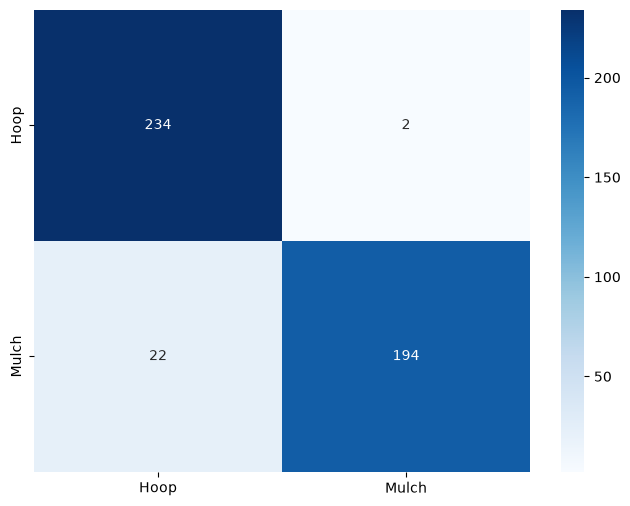

In [103]:
from sklearn.metrics import precision_score, recall_score, f1_score


# # print confusion matrix, overall accuracy, class accuracies
cm = confusion_matrix(all_sampled_test_data['real_class'], all_sampled_test_data['first'], labels=[0, 1, 2])
accuracy = np.trace(cm) / np.sum(cm)
print(f'Overall accuracy: {accuracy:.4f}')
print(f'Total sampled test points: {all_sampled_test_data.shape[0]}')

# Calculate accuracy for just classes 1 and 2 (exclude class 0 given temporal mismatch)
mask = (all_sampled_test_data['real_class'].isin([1, 2])) & (all_sampled_test_data['first'].isin([1, 2]))
filtered = all_sampled_test_data[mask]
# display(filtered)
print(f'Total sampled test points for plastic classes only: {filtered.shape[0]}')

cm_12 = confusion_matrix(filtered['real_class'], filtered['first'], labels=[1, 2])
accuracy_12 = np.trace(cm_12) / np.sum(cm_12)
print(f'Accuracy for plastic classes only: {accuracy_12*100:.2f}%')

# print the accuracy for each class
# Print per-class accuracy (producer's accuracy)
for i, label in enumerate(['Hoop', 'Mulch']):
    class_accuracy = cm_12[i, i] / np.sum(cm_12[i, :])
    print(f'{label} producer\'s accuracy: {class_accuracy*100:.2f}%')

# User's accuracy (precision)
users_acc = precision_score(filtered['real_class'], filtered['first'], labels=[1, 2], average=None)
for i, ua in enumerate(users_acc):
    print(f'{["Hoop", "Mulch"][i]} user\'s accuracy: {ua*100:.2f}%')

# F1 score per class
f1 = f1_score(filtered['real_class'], filtered['first'], labels=[1, 2], average=None)
for i, f in enumerate(f1):
    print(f'{["Hoop", "Mulch"][i]} F1 score: {f*100:.2f}%')


plt.figure(figsize=(8, 6))
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['other', 'hoop', 'mulch'], yticklabels=['other', 'hoop', 'mulch'])
sns.heatmap(cm_12, annot=True, fmt='d', cmap='Blues', xticklabels=['Hoop', 'Mulch'], yticklabels=['Hoop', 'Mulch'])

In [104]:
# users accuracy -- how often is a point classified as hoop actually hoop
# but using these terms really implies that we're comparing to other class, which we're not here
# don't think we should include this breakdown (or if we do, very clear explanation)
usersacc = np.diag(cm_12) / np.sum(cm_12, axis=0)
print('User\'s accuracy for each class:')
print(f'hoop: {usersacc[0]*100:.2f}%')
print(f'mulch: {usersacc[1]*100:.2f}%')

# producers accuracy -- how often is an actual hoop point classified as hoop
producersacc = np.diag(cm_12) / np.sum(cm_12, axis=1)
print('Producer\'s accuracy for each class:')
print(f'hoop: {producersacc[0]*100:.2f}%')
print(f'mulch: {producersacc[1]*100:.2f}%')

User's accuracy for each class:
hoop: 91.41%
mulch: 98.98%
Producer's accuracy for each class:
hoop: 99.15%
mulch: 89.81%


In [105]:
# ca_test_data = test_data[test_data['location'] == 'CA']

# display(ca_test_data)

# m = geemap.Map()
# m.add_points_from_xy(ca_test_data, x="Longitude", y="Latitude")
# m.centerObject(ee.Geometry.Point(ca_test_data["Longitude"].mean(), ca_test_data["Latitude"].mean()), 7)
# m

### 9.2 Check field majority classifications on the map

In [106]:
# # add san mateo county field classification asset to a map 
# sanmateo_fields = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/FieldMajority_SanMateo_WY2024_v1_4')
# sanmateo_raster = ee.Image('projects/ee-tnc-annietaylor/assets/agplastics/PlasticClass_SanMateoCo_WY2024_v1_4')
# yolo_fields = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/FieldMajority_Yolo_WY2024_v1_4')
# la_fields = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/FieldMajority_LosAngeles_WY2024_v1_4')
# sb_fields = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/FieldMajority_SantaBarbara_WY2024_v1_4')
# slo_fields = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/FieldMajority_SanLuisObispo_WY2024_v1_4')
# monterey_fields = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/FieldMajority_Monterey_WY2024_v1_4')

# sanmateo_field_image = sanmateo_fields.reduceToImage(
#     properties=['mode'],
#     reducer=ee.Reducer.first()
# )
# yolo_field_image = yolo_fields.reduceToImage(
#     properties=['mode'],
#     reducer=ee.Reducer.first()
# )
# la_field_image = la_fields.reduceToImage(
#     properties=['mode'],
#     reducer=ee.Reducer.first()
# )
# sb_field_image = sb_fields.reduceToImage(
#     properties=['mode'],
#     reducer=ee.Reducer.first()
# )
# slo_field_image = slo_fields.reduceToImage(
#     properties=['mode'],
#     reducer=ee.Reducer.first()
# )
# monterey_field_image = monterey_fields.reduceToImage(
#     properties=['mode'],
#     reducer=ee.Reducer.first()
# )


# m = geemap.Map()
# m.add_basemap('HYBRID')
# m.addLayer(sanmateo_raster, {'min': 0, 'max': 2, 'palette': ['blue', 'red', 'yellow']}, 'San Mateo WY2024 Classification', False)
# m.addLayer(sanmateo_field_image, {'min': 0, 'max': 2, 'palette': ['blue', 'red', 'yellow']}, 'San Mateo WY2024', False)
# m.addLayer(yolo_field_image, {'min': 0, 'max': 2, 'palette': ['blue', 'red', 'yellow']}, 'Yolo WY2024', False)
# m.addLayer(la_field_image, {'min': 0, 'max': 2, 'palette': ['blue', 'red', 'yellow']}, 'Los Angeles WY2024', False)
# m.addLayer(sb_field_image, {'min': 0, 'max': 2, 'palette': ['blue', 'red', 'yellow']}, 'Santa Barbara WY2024', False)
# m.addLayer(slo_field_image, {'min': 0, 'max': 2, 'palette': ['blue', 'red', 'yellow']}, 'San Luis Obispo WY2024')
# m.addLayer(monterey_field_image, {'min': 0, 'max': 2, 'palette': ['blue', 'red', 'yellow']}, 'Monterey WY2024', )
# m.centerObject(slo_fields, 10)
# m

In [107]:
m = geemap.Map()
m.addLayer(crops, {}, 'Crop Mask')
ca_outline = ca.style(**{'color': 'black', 'fillColor': '00000000', 'width': 2})
m.addLayer(ca_outline, {}, 'CA Outline')
m.centerObject(ca, 6)
# m

## 10. Area Calculations

### 10.1 Get area of mulch and hoop from feature collections

landID data already has a ACRES field, calculated in CA teale albers m or similar

that's likely to be more accurate than calculating from geometry area in wgs84/EE

In [108]:
# Select water years and county of interest
wys = [2019, 2020, 2021, 2022, 2023, 2024, 2025]
counties = [ventura, cruz, santabarbara, monterey, slo]

# initialize empty list to hold dataframes
all_dfs = []


for county in counties:
    # extract text name of county
    county_name = county.first().get('NAME').getInfo() # 'Santa Cruz'
    county_name_strp = county_name.replace(" ", "") # 'SantaCruz'

    for wy in wys:
        # import fields data from asset
        assetId = f'projects/ee-tnc-annietaylor/assets/agplastics/FieldMajority_{county_name_strp}_WY{wy}_v1_4'
        fields_county_majority = ee.FeatureCollection(assetId)

        # Filter out features where 'mode' (plastic class) is None, then sum ACRES by class
        filtered_fields = fields_county_majority.filter(ee.Filter.notNull(['mode']))
        sums = filtered_fields.reduceColumns(
            selectors=['ACRES', 'mode'],
            reducer=ee.Reducer.sum().group(groupField=1, groupName='mode'),
        )

        # get total acres of all fields within the county
        total_acres = filtered_fields.aggregate_sum('ACRES').getInfo()

        # make a row of a df with county, wy, total acres, hoop acres, mulch acres, other acres, hoop %, mulch %, other %
        sums_list = sums.get('groups').getInfo()
        acres_dict = {item['mode']: item['sum'] for item in sums_list}
        hoop_acres = acres_dict.get(1, 0)
        mulch_acres = acres_dict.get(2, 0)
        other_acres = acres_dict.get(0, 0)

        hoop_pct = (hoop_acres / total_acres) * 100 if total_acres > 0 else 0
        mulch_pct = (mulch_acres / total_acres) * 100 if total_acres > 0 else 0
        other_pct = (other_acres / total_acres) * 100 if total_acres > 0 else 0

        summary_df = pd.DataFrame([{
            'County': county_name,
            'Water Year': wy,
            'Total Acres': total_acres,
            'Hoop Acres': hoop_acres,
            'Mulch Acres': mulch_acres,
            'Other Acres': other_acres,
            'Hoop %': hoop_pct,
            'Mulch %': mulch_pct,
            'Other %': other_pct,
            'Total km2': total_acres * 0.00404686,
            'Hoop km2': hoop_acres * 0.00404686,
            'Mulch km2': mulch_acres * 0.00404686
        }])
        all_dfs.append(summary_df)

# concatenate all dataframes into one
final_df = pd.concat(all_dfs, ignore_index=True)
display(final_df)
# save to csv, remove the acres fields before saving
final_df = final_df.drop(columns=['Total Acres', 'Hoop Acres', 'Mulch Acres', 'Other Acres'])
# final_df.to_csv('output/SuppTable_FieldMajority_Area_FourCounties_allWYs_v1_4.csv', index=False)
# runs four counties in 15s

,County,Water Year,Total Acres,Hoop Acres,Mulch Acres,Other Acres,Hoop %,Mulch %,Other %,Total km2,Hoop km2,Mulch km2
0,Ventura,2019,92929.385292,6187.352926,12388.585420,74353.446945,6.658123,13.331182,80.010695,376.072212,25.039351,50.134871
1,Ventura,2020,93407.743240,6560.605685,11772.832245,75074.305310,7.023621,12.603701,80.372679,378.008060,26.549853,47.643004
2,Ventura,2021,93184.204484,7174.319123,11427.598982,74582.286379,7.699072,12.263451,80.037477,377.103430,29.033465,46.245893
3,Ventura,2022,93692.709610,5950.249466,13404.573986,74337.886158,6.350814,14.306955,79.342231,379.161279,24.079827,54.246434
4,Ventura,2023,93911.763412,6161.746251,14830.070538,72919.946622,6.561208,15.791494,77.647298,380.047759,24.935724,60.015219
5,Ventura,2024,93921.758359,5841.899737,14759.562396,73320.296226,6.219964,15.714742,78.065293,380.088207,23.641350,59.729883
6,Ventura,2025,93921.758359,5906.999813,15543.809733,72470.948814,6.289277,16.549743,77.160980,380.088207,23.904801,62.903622
7,Santa Cruz,2019,17927.126941,3185.994928,3847.140282,10893.991731,17.771922,21.459882,60.768197,72.548573,12.893275,15.568838
8,Santa Cruz,2020,17940.475761,3074.621750,3844.545025,11021.308987,17.137905,21.429449,61.432646,72.602594,12.442564,15.558335
9,Santa Cruz,2021,18014.938474,2958.198737,3437.821394,11618.918342,16.420810,19.083170,64.496020,72.903934,11.971416,13.912382


In [109]:
# WY 2025 totals across the five counties
wy_2025 = final_df[final_df['Water Year'] == 2025].copy()

# Use km2 columns (equivalent to using acres for percentages)
total_ag_km2 = wy_2025['Total km2'].sum()
total_hoop_km2 = wy_2025['Hoop km2'].sum()
total_mulch_km2 = wy_2025['Mulch km2'].sum()

hoop_pct_total_ag = (total_hoop_km2 / total_ag_km2) * 100
mulch_pct_total_ag = (total_mulch_km2 / total_ag_km2) * 100

print(f"WY 2025 total ag area (5 counties): {total_ag_km2:.2f} km²")
print(f"Hoop area: {total_hoop_km2:.2f} km² ({hoop_pct_total_ag:.2f}% of total ag area)")
print(f"Mulch area: {total_mulch_km2:.2f} km² ({mulch_pct_total_ag:.2f}% of total ag area)")
# combined hoop and mulch area
total_plastic_km2 = total_hoop_km2 + total_mulch_km2
plastic_pct_total_ag = (total_plastic_km2 / total_ag_km2) * 100 
print(f"Total plastic area (hoop + mulch): {total_plastic_km2:.2f} km² ({plastic_pct_total_ag:.2f}% of total ag area)")

WY 2025 total ag area (5 counties): 2550.39 km²
Hoop area: 68.16 km² (2.67% of total ag area)
Mulch area: 279.97 km² (10.98% of total ag area)
Total plastic area (hoop + mulch): 348.13 km² (13.65% of total ag area)


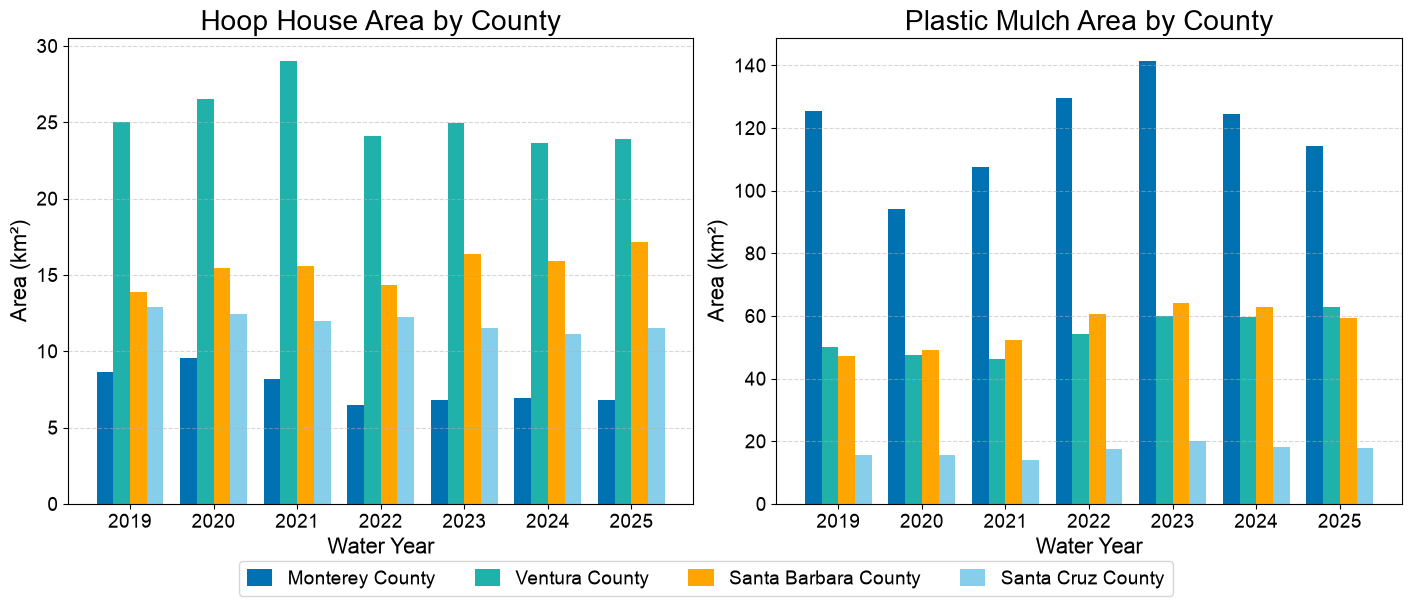

In [114]:
# Grouped bar chart for Hoop House and Mulch Plastic Area over time (counties are groups)
counties = ['Monterey', 'Ventura', 'Santa Barbara', 'Santa Cruz']
water_years = sorted(final_df['Water Year'].unique())

# drkblue 0072B2, pink CC79A7
county_colors = ['#0072B2', 'lightseagreen', 'orange', 'skyblue']

plt.rcParams['font.family'] = ["Arial", "DejaVu Sans"]

# constrained layout reserves room for the figure-level legend; tight_layout does not
fig, axs = plt.subplots(1, 2, figsize=(14, 6), sharey=False, layout='constrained')

title_fontsize = 20
label_fontsize = 16
tick_fontsize = 14
legend_fontsize = 14

n_counties = len(counties)
n_years = len(water_years)
x = np.arange(n_years)
bar_width = 0.8 / n_counties

for ax, class_col, title in zip(axs,
    ['Hoop km2', 'Mulch km2'],
    ['Hoop House Area by County', 'Plastic Mulch Area by County']
    ):
    for i, (county, color) in enumerate(zip(counties, county_colors)):
        county_data = final_df[final_df['County'] == county].set_index('Water Year').reindex(water_years)
        offsets = x + (i - n_counties / 2 + 0.5) * bar_width
        ax.bar(offsets, county_data[class_col].values, width=bar_width, label=f'{county} County', color=color)
    ax.set_title(title, fontsize=title_fontsize)
    ax.set_xlabel('Water Year', fontsize=label_fontsize)
    ax.set_ylabel('Area (km²)', fontsize=label_fontsize)
    ax.set_xticks(x)
    ax.set_xticklabels(water_years)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda val, p: f'{int(val):,}'))
    ax.tick_params(axis='both', labelsize=tick_fontsize)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=legend_fontsize, handlelength=1.3, handleheight=1.0, loc='outside lower center', ncol=4)

# plt.savefig('output/Figure4_AreabyCounty_grouped_bar_v1_4.png', dpi=500, bbox_inches='tight')
plt.show()


#### Stacked area percent cover by county

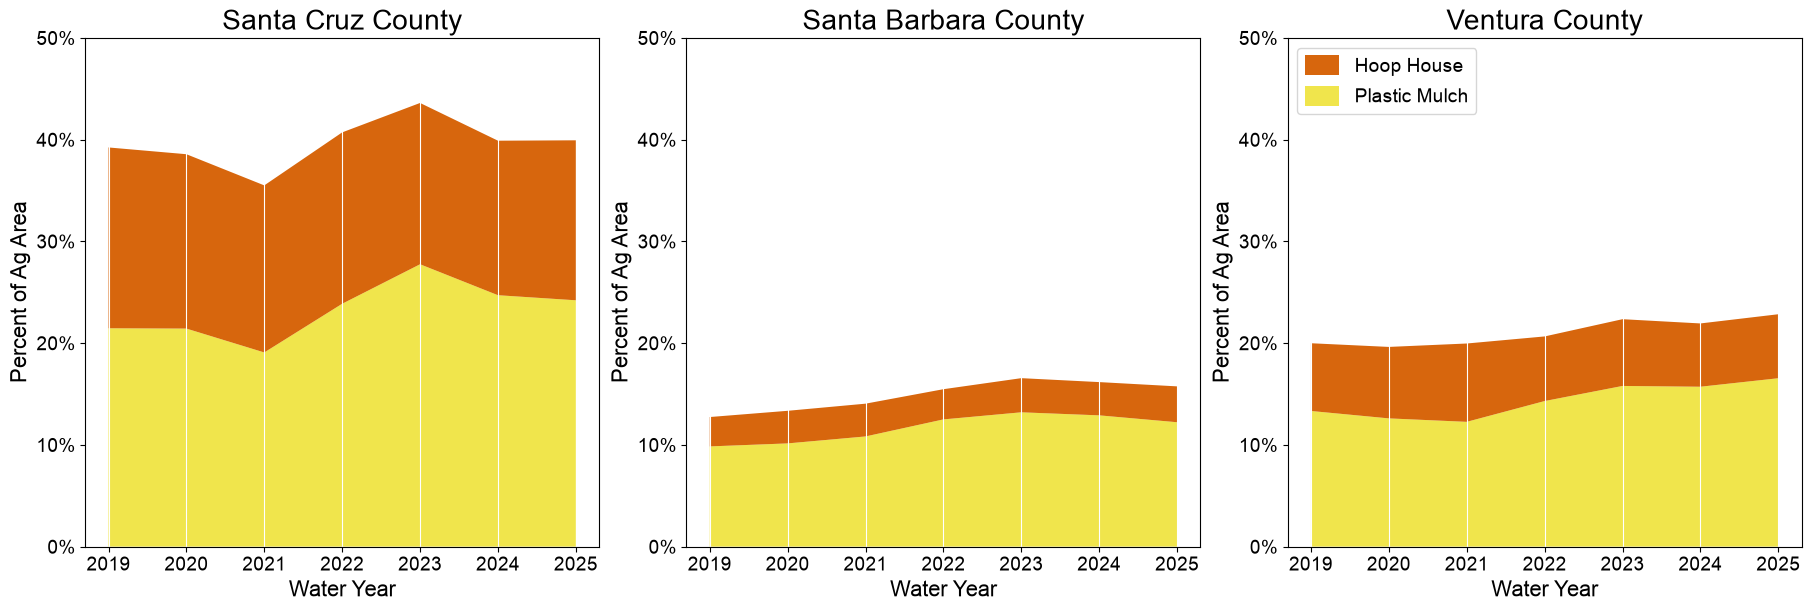

In [115]:
plt.rcParams['font.family'] = ["Arial", "DejaVu Sans"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True, layout='constrained')

# counties = final_df['County'].unique() not N to S
counties = ['Santa Cruz', 'Santa Barbara', 'Ventura']

title_fontsize = 20
label_fontsize = 16
tick_fontsize = 14
legend_fontsize = 14

for ax, county in zip(axes, counties):
    df_county = final_df[final_df['County'] == county]
    ax.stackplot(
        df_county['Water Year'],
        df_county['Mulch %'],
        df_county['Hoop %'],
        labels=['Plastic Mulch', 'Hoop House'],
        colors=['#F0E442','#D55E00'],
        alpha=0.95
    )
    ax.set_title(f'{county} County', fontsize=title_fontsize)
    ax.set_xlabel('Water Year', fontsize=label_fontsize)
    ax.set_xticks(df_county['Water Year'])
    ax.grid(axis='x', linestyle='-', color='white')
    ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter())
    ax.set_ylabel('Percent of Ag Area', fontsize=label_fontsize)
    ax.set_ylim(0, 50)
    ax.tick_params(axis='both', labelsize=tick_fontsize)
    # sharey=True hides y tick labels on all but the first column; force them back on
    ax.tick_params(axis='y', labelleft=True)


# change the order of the legend items 
handles, labels = axes[2].get_legend_handles_labels()
order = [1,0]

axes[2].legend([handles[idx] for idx in order],[labels[idx] for idx in order],
        loc='upper left',
        handleheight=1.2,
        handlelength=1.75,
        fontsize=legend_fontsize
)

# plt.savefig('output/Figure5_ProportionPlasticbyCounty_v1_4.png', dpi=500, bbox_inches='tight')
plt.show()

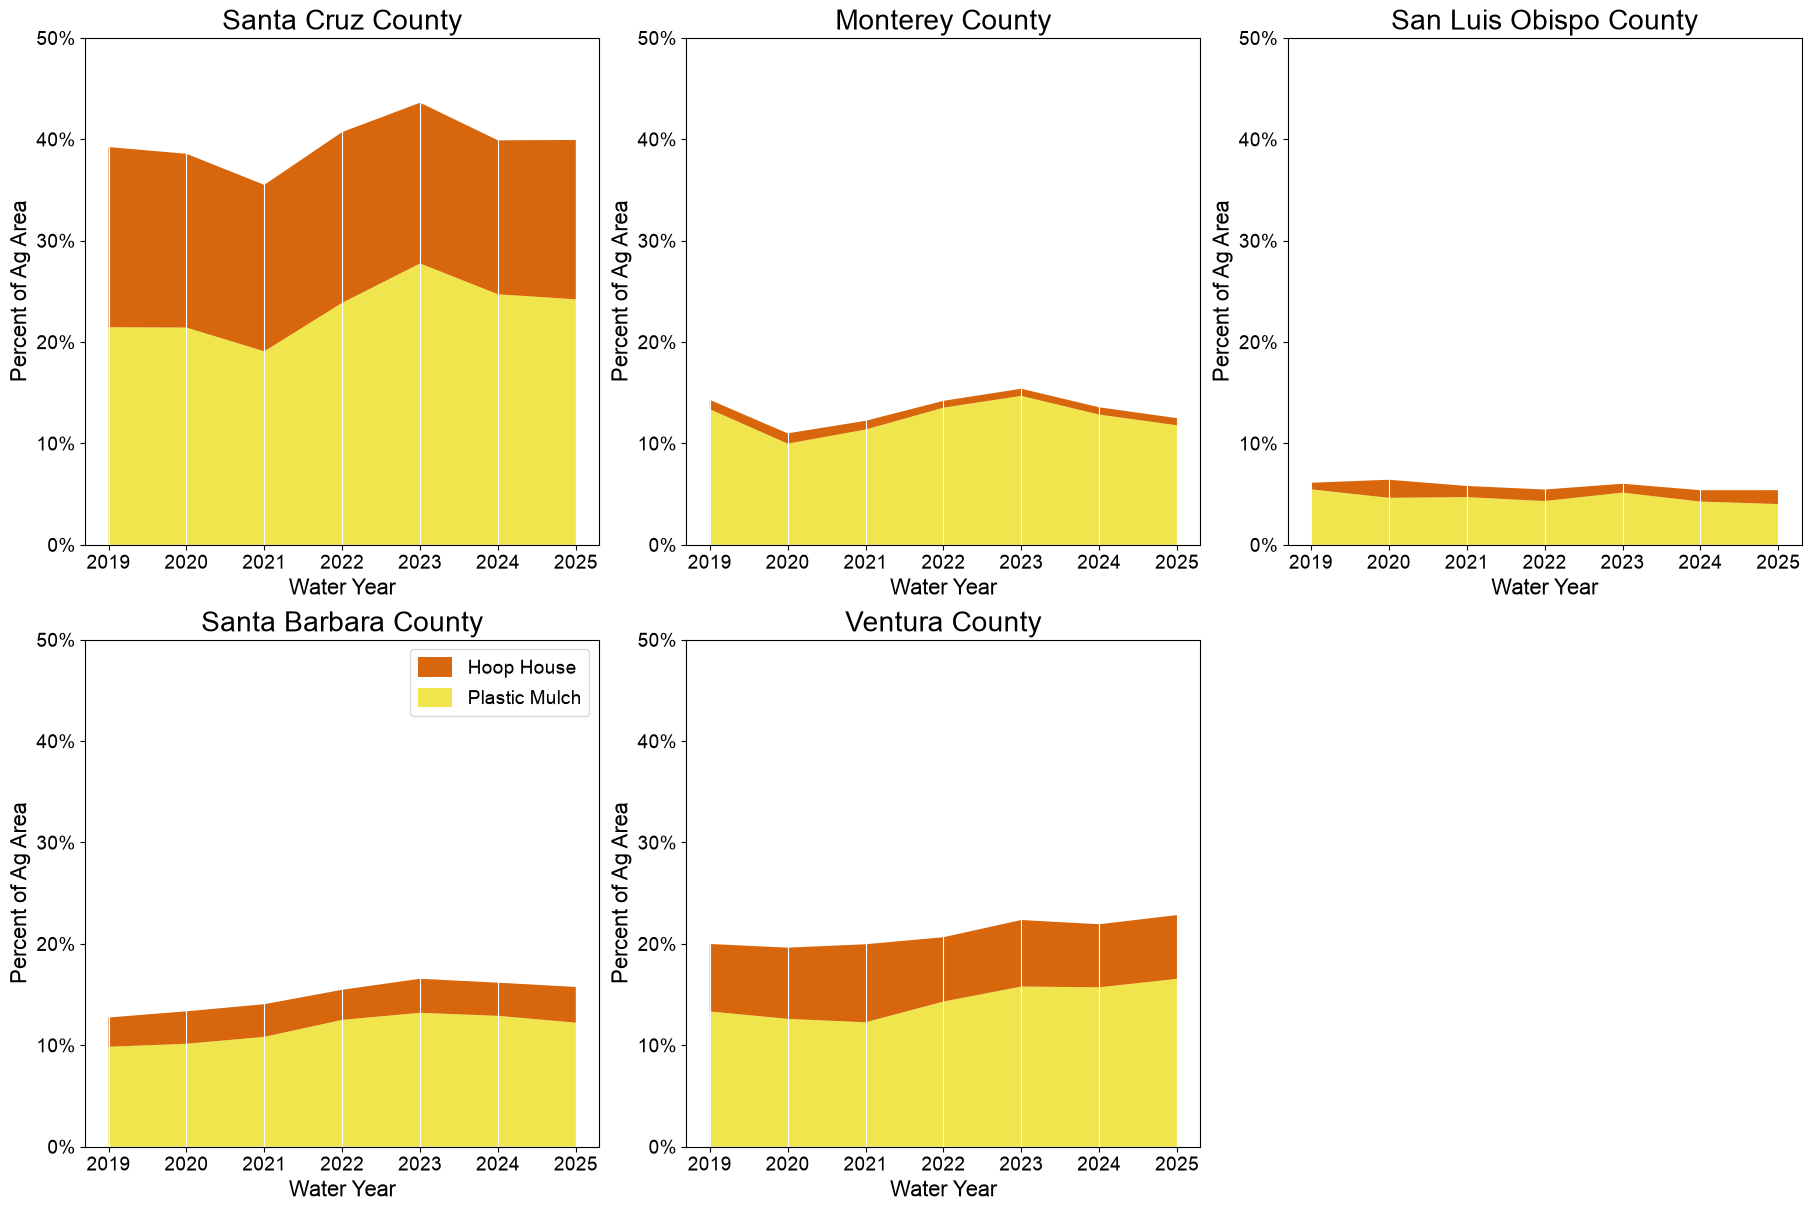

In [116]:
# set the font before creating the figure so it applies to all artists
plt.rcParams['font.family'] = ["Arial", "DejaVu Sans"]

fig, axes = plt.subplots(2, 3, figsize=(18, 12), sharey=True, layout='constrained')
axes = axes.flatten()

counties = ['Santa Cruz', 'Monterey', 'San Luis Obispo', 'Santa Barbara', 'Ventura']

# hide the unused 6th subplot
fig.delaxes(axes[5])

title_fontsize = 20
label_fontsize = 16
tick_fontsize = 14
legend_fontsize = 14

for ax, county in zip(axes, counties):
    df_county = final_df[final_df['County'] == county]
    ax.stackplot(
        df_county['Water Year'],
        df_county['Mulch %'],
        df_county['Hoop %'],
        labels=['Plastic Mulch', 'Hoop House'],
        colors=['#F0E442','#D55E00'],
        alpha=0.95
    )
    ax.set_title(f'{county} County', fontsize=title_fontsize)
    ax.set_xlabel('Water Year', fontsize=label_fontsize)
    ax.set_xticks(df_county['Water Year'])
    ax.grid(axis='x', linestyle='-', color='white')
    ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter())
    ax.set_ylabel('Percent of Ag Area', fontsize=label_fontsize)
    ax.set_ylim(0, 50)
    ax.tick_params(axis='both', labelsize=tick_fontsize)
    # sharey=True hides y tick labels on all but the first column; force them back on
    ax.tick_params(axis='y', labelleft=True)


# change the order of the legend items 
handles, labels = axes[2].get_legend_handles_labels()
order = [1,0]

axes[3].legend([handles[idx] for idx in order],[labels[idx] for idx in order],
        loc='upper right',
        handleheight=1.2,
        handlelength=1.75,
        fontsize=legend_fontsize
)

# plt.savefig('output/Figure5_ProportionPlasticbyCounty_v1_4.png', dpi=500, bbox_inches='tight')
plt.show()

## 11. Frequency of plastic application

In [113]:
county = monterey
wys = [2019, 2020, 2021, 2022, 2023, 2024, 2025]

county_name = county.first().get('NAME').getInfo() # 'Santa Cruz'
county_name_strp = county_name.replace(" ", "") # 'SantaCruz'

# initialize an empty image
all_plastic = ee.Image()
all_hoop = ee.Image()
all_mulch = ee.Image()

for wy in wys:
    # import fields data from asset (features)
    assetId = f'projects/ee-tnc-annietaylor/assets/agplastics/FieldMajority_{county_name_strp}_WY{wy}_v1_4'
    fields_county_majority = ee.FeatureCollection(assetId)

    # Filter out features where 'mode' (plastic class) is None (null), then convert to raster
    fields_img = fields_county_majority.filter(ee.Filter.notNull(['mode'])).reduceToImage(
        properties=['mode'], reducer=ee.Reducer.first()
    ) # resolution seems very high

    # create a new image that is 1 whenever the fields image is 1 or 2 (i.e. hoop house or plastic mulch, not other cover)
    plastic = fields_img.gt(0).rename(f'plastic_{wy}')
    all_plastic = all_plastic.addBands(plastic) # adds a band equal to 1 for each WY

    # make an image from only hoop pixels and set to 1
    hoop = fields_img.eq(1).rename(f'hoop_{wy}')
    all_hoop = all_hoop.addBands(hoop)

    # make an image from only mulch pixels and set to 1
    mulch = fields_img.eq(2).rename(f'mulch_{wy}')
    all_mulch = all_mulch.addBands(mulch)

# Select only bands that start with 'plastic' to remove 'constant' band
# don't need to do this, the constant band is set to None 
# plastic_bands = [band for band in all_plastic.bandNames().getInfo() if band.startswith('plastic')]
# all_plastic = all_plastic.select(plastic_bands)

# sum all bands together
all_plastic = all_plastic.reduce(ee.Reducer.sum()).rename('plastic_sum')
all_hoop = all_hoop.reduce(ee.Reducer.sum()).rename('hoop_sum')
all_mulch = all_mulch.reduce(ee.Reducer.sum()).rename('mulch_sum')

# combine these images into one with three bands for exporting
plastic_sum = all_plastic.addBands(all_hoop).addBands(all_mulch).toInt8()
# display(plastic_sum)

map = geemap.Map()
map.centerObject(county, 8)
map.add_basemap('SATELLITE')
map.addLayer(all_plastic, {'min': 0, 'max': 6, 'palette': ['white', 'purple']}, 'Num Plastic Years')
map.addLayer(all_hoop, {'min': 0, 'max': 6, 'palette': ['white', 'red']}, 'Num Hoop Years')
map.addLayer(all_mulch, {'min': 0, 'max': 6, 'palette': ['white', 'orange']}, 'Num Mulch Years')
# display(map)

# export to tif
export_task = ee.batch.Export.image.toDrive(
    image=plastic_sum,
    description=f'plastic_freq_{county_name_strp}',
    fileNamePrefix=f'PlasticFrequency_{county_name_strp}Co_v1_4',
    folder='EarthEngine',
    region=county.geometry(),
    scale=10,
    maxPixels=1e13,
    crs = 'EPSG:3310' # CA teale albers
)
# export_task.start()

Map(center=[36.23945321490026, -121.30664722439829], controls=(WidgetControl(options=['position', 'transparent…

## 12 River area analysis

Analyze the mulch frequency area within each county and within 1km of the major rivers adjacent to ag in our five county study area

In [24]:
# # This is just for one county to get crop area as a tif, no longer needed in our workflow
# # export a tif with any field classified as other also included
# county = monterey
# wys = [2019, 2020, 2021, 2022, 2023, 2024, 2025]

# county_name = county.first().get('NAME').getInfo() # 'Santa Cruz'
# county_name_strp = county_name.replace(" ", "") # 'SantaCruz'

# # initialize an empty image
# other = ee.Image()

# for wy in wys:
#     # import fields data from asset (features)
#     assetId = f'projects/ee-tnc-annietaylor/assets/agplastics/FieldMajority_{county_name_strp}_WY{wy}_v1_4'
#     fields_county_majority = ee.FeatureCollection(assetId)

#     # Filter out features where 'mode' (plastic class) is None, then convert to raster
#     fields_img = fields_county_majority.filter(ee.Filter.notNull(['mode'])).reduceToImage(
#         properties=['mode'], reducer=ee.Reducer.first()
#     ) # high res

#     # set all values of 'mode' to 1 -- i.e. this is a crop field
#     crop = fields_img.gte(0).rename(f'crop_{wy}')
#     other = other.addBands(crop)

# # sum all bands together
# other = other.reduce(ee.Reducer.max()).rename('crop') #if a pixel was ever a crop field, assign to 1 (max)

# map = geemap.Map()
# map.centerObject(county, 8)
# map.add_basemap('SATELLITE')
# map.addLayer(other, {'min': 0, 'max': 1, 'palette': ['white', 'purple']}, 'Crop Fields')
# # display(map)

# # export to tif
# export_task = ee.batch.Export.image.toDrive(
#     image=other,
#     description=f'crop_{county_name_strp}',
#     fileNamePrefix=f'Crops_{county_name_strp}Co_v1_4',
#     folder='EarthEngine',
#     region=county.geometry(),
#     scale=10,
#     maxPixels=1e13,
#     crs = 'EPSG:3310' # CA teale albers
# )
# # export_task.start()

Use that raster in Pro to calculate these counts, export as csv to run the calculations below

### 12.1 River and county frequency stats in EE (replaces the Pro step)
1. Export one multi-band frequency asset for all five counties (bands: `mulch_sum`, `hoop_sum`, `plastic_sum`, `crop_ever`)
2. Buffer the uploaded river lines by 1 km in EE
3. Count pixels in each frequency class per river buffer / county and save the csvs used below

In [25]:
freq_counties = [cruz, monterey, slo, santabarbara, ventura]
wys = [2019, 2020, 2021, 2022, 2023, 2024, 2025]
freq_asset_id = 'projects/ee-tnc-annietaylor/assets/agplastics/PlasticFrequency_5Counties_v1_4'

# Builds one image per county: bands count how many WYs each pixel was mulch/hoop/plastic, plus a crop-ever flag
def build_freq_image(county_name_strp, wys):
    # one image per WY from the field majority assets; fields with no class are dropped
    yearly = ee.ImageCollection([
        ee.FeatureCollection(f'projects/ee-tnc-annietaylor/assets/agplastics/FieldMajority_{county_name_strp}_WY{wy}_v1_4')
        .filter(ee.Filter.notNull(['mode']))
        .reduceToImage(properties=['mode'], reducer=ee.Reducer.first())
        for wy in wys
    ])
    # sum() keeps the union of yearly masks, so never-plastic crop pixels get 0
    mulch_sum = yearly.map(lambda img: img.eq(2)).sum().rename('mulch_sum')
    hoop_sum = yearly.map(lambda img: img.eq(1)).sum().rename('hoop_sum')
    plastic_sum = yearly.map(lambda img: img.gt(0)).sum().rename('plastic_sum')
    crop_ever = yearly.map(lambda img: img.gte(0)).max().rename('crop_ever')
    return ee.Image.cat([mulch_sum, hoop_sum, plastic_sum, crop_ever]).toInt8()

freq_images = []
for county in freq_counties:
    county_name_strp = county.first().get('NAME').getInfo().replace(" ", "")
    freq_images.append(build_freq_image(county_name_strp, wys))

# counties don't overlap, so mosaic just merges them into one image
freq_img_all = ee.ImageCollection(freq_images).mosaic()

# bounding box only; pixels outside the counties are masked
freq_region = ee.FeatureCollection(freq_counties).flatten().geometry().bounds()

# run this export and wait for it to finish before the next cell, which reads the asset
export_freq = ee.batch.Export.image.toAsset(
    image=freq_img_all,
    description='AssetExport_PlasticFrequency_5Counties_v1_4',
    assetId=freq_asset_id,
    region=freq_region,
    scale=10,
    crs='EPSG:3310',
    maxPixels=1e13,
)

# export_freq.start()

Import major rivers for analysis from assets

In [43]:
# asset with major rivers in five counties, from Major_Rivers_Diss.shp in ee exports folder
rivers = ee.FeatureCollection('projects/ee-tnc-annietaylor/assets/agplastics/major_rivers_fivecounties')
river_field = 'Name'
buffer_m = 1000

# buffer each river by 1000m, with 10m maxError tolerance
river_buffers = rivers.map(lambda f: f.buffer(buffer_m, 10))

# load the exported frequency asset
freq_img = ee.Image(freq_asset_id)

m = geemap.Map()
m.add_basemap('SATELLITE')
m.addLayer(freq_img.select('mulch_sum'), {'min': 0, 'max': len(wys), 'palette': ['white', 'orange', 'red']}, 'Num Mulch Years')
m.addLayer(river_buffers.style(color='blue', fillColor='0000ff22'), {}, 'River buffers')
m.centerObject(river_buffers, 8)
m


Map(center=[35.3483571744011, -120.44178267492364], controls=(WidgetControl(options=['position', 'transparent_…

Iterate through all of the river buffer areas and county boundaries, summarizing area of mulch frequency classes, and save results to csv

In [27]:
def freq_histogram(regions, name_prop, band='mulch_sum', n_years=len(wys)):
    # restrict to crop pixels so non-crop area isn't processed; zero-mulch crop pixels are kept
    img = freq_img.select(band).updateMask(freq_img.select('crop_ever'))
    n = regions.size().getInfo()
    region_list = regions.select([name_prop]).toList(n)
    rows = []
    # one small request per region instead of one huge reduceRegions over all of them (memory error)
    for i in range(n):
        f = ee.Feature(region_list.get(i))
        # unweighted to match Pro's whole-pixel counts
        hist = img.reduceRegion(
            reducer=ee.Reducer.frequencyHistogram().unweighted(),
            geometry=f.geometry(),
            scale=30,
            crs='EPSG:3310',
            maxPixels=1e13,
            tileScale=16
        ).get(band)
        res = ee.Dictionary({'name': f.get(name_prop), 'hist': hist}).getInfo()
        # histogram can contain a 'null' key for masked pixels; drop it
        h = {int(float(k)): v for k, v in (res['hist'] or {}).items() if k != 'null'}
        row = {name_prop: res['name']}
        row.update({f'count_{i}': h.get(i, 0) for i in range(n_years + 1)})
        row['count_crop'] = sum(h.values())
        rows.append(row)
        print(f"done {res['name']}")
    return pd.DataFrame(rows)

# commenting out as this is computationally intensive
# river_counts = freq_histogram(river_buffers, river_field)
# display(river_counts)
# river_counts.to_csv('output/Crop_and_Mulch_counts_All_Rivers_v1_4.csv', index=False)

# county_names = [c.first().get('NAME').getInfo() for c in freq_counties]
# county_regions = county_bnd.filter(ee.Filter.inList('NAME', county_names))
# county_counts = freq_histogram(county_regions, 'NAME').rename(columns={'NAME': 'County'})
# county_counts['County'] = county_counts['County'] + ' County'
# display(county_counts)
# county_counts.to_csv('output/MulchandCropFreq_v1_4_byCounty.csv', index=False)


### 12.2 Final charts of river area analysis

In [45]:
# import csv with number of pixels in each frequency class by river in each county
# freq_df = pd.read_csv('data/Mulch_freq_All_Rivers.csv')
# freq_df = pd.read_csv('data/Crop_and_Mulch_counts_All_Rivers.csv') # v1.3, from Pro
freq_df = pd.read_csv('output/Crop_and_Mulch_counts_All_Rivers_v1_4.csv')

# extract number of years from column names for iteration later
n_years = max(int(c.split('_')[1]) for c in freq_df.columns if c.startswith('count_') and c.split('_')[1].isdigit())

# add a column that's the total number of crop pixels with no mulching 
freq_df['count_nomulch'] = freq_df['count_crop'] - freq_df[[f'count_{i}' for i in range(1, n_years + 1)]].sum(axis=1)

# convert pixel counts to area in km2
pixel_area_km2 = 100 / 1e6  # area of one 10m pixel in km²
freq_df['areakm_crops'] = freq_df['count_crop'] * pixel_area_km2
freq_df['areakm_nomulch'] = freq_df['count_nomulch'] * pixel_area_km2
freq_df['pct_nomulch'] = (freq_df['areakm_nomulch'] / freq_df['areakm_crops']) * 100

# calc the percent area in each freq class for each river, based on areakm_crop
for i in range(1, n_years + 1):
    freq_df[f'areakm_{i}'] = freq_df[f'count_{i}'] * pixel_area_km2
    freq_df[f'pct_{i}'] = (freq_df[f'areakm_{i}'] / freq_df['areakm_crops']) * 100

# calc cumulative area for 1+ years, 2+ years, 3+ years of mulching
freq_df['OnePlus_km2'] = freq_df[[f'areakm_{i}' for i in range(1, n_years + 1)]].sum(axis=1)
freq_df['OnePlus_pct'] = (freq_df['OnePlus_km2'] / freq_df['areakm_crops']) * 100
freq_df['TwoPlus_km2'] = freq_df[[f'areakm_{i}' for i in range(2, n_years + 1)]].sum(axis=1)
freq_df['TwoPlus_pct'] = (freq_df['TwoPlus_km2'] / freq_df['areakm_crops']) * 100
freq_df['ThreePlus_km2'] = freq_df[[f'areakm_{i}' for i in range(3, n_years + 1)]].sum(axis=1)
freq_df['ThreePlus_pct'] = (freq_df['ThreePlus_km2'] / freq_df['areakm_crops']) * 100

display(freq_df)

# sum for all rivers -- percent of area mulch three or more times in six years
total_crops_km2 = freq_df['areakm_crops'].sum()
total_threeplus_km2 = freq_df['ThreePlus_km2'].sum()
total_oneplus_km2 = freq_df['OnePlus_km2'].sum()
total_twoplus_km2 = freq_df['TwoPlus_km2'].sum()
print('Percent of crop area within 1km of rivers that was mulched 1+ times: ',
    (total_oneplus_km2 / total_crops_km2) * 100
)
print('Percent of mulched area within 1km of rivers that was mulched 2+ times: ',
    (total_twoplus_km2 / total_oneplus_km2) * 100
)

# get twoplus_km2 / oneplus_km2 percent (repeatedly mulched as a percent of any mulch)
# i.e. what percent of the area that was mulched at least once was mulched 2+ times
freq_df['TwoPlus_pct_ofMulch'] = (freq_df['TwoPlus_km2'] / freq_df['OnePlus_km2']) * 100

display(freq_df[['Name', 'TwoPlus_pct_ofMulch', 'OnePlus_pct']])

# # get average oneplus_pct across all rivers EXCLUDING Pajaro
# # not really unique, commenting this out for now
# exPajaro = freq_df[freq_df['Name'] != 'Pajaro River']

# total_crops_exPajaro_km2 = exPajaro['areakm_crops'].sum()
# total_onePlus_exPajaro_km2 = exPajaro['OnePlus_km2'].sum()
# total_twoPlus_exPajaro_km2 = exPajaro['TwoPlus_km2'].sum()

# avg_oneplus_pct_exPajaro = (total_onePlus_exPajaro_km2 / total_crops_exPajaro_km2) * 100
# avg_twoplus_pct_exPajaro = (total_twoPlus_exPajaro_km2 / total_onePlus_exPajaro_km2) * 100

# display(f'Avg % crop area w/in 1km of rivers (excluding Pajaro) mulched at least once: {avg_oneplus_pct_exPajaro:.2f}%')
# display(f'Avg % of area mulched at least once that was mulched 2+ times (excluding Pajaro): {avg_twoplus_pct_exPajaro:.2f}%')

# Sum the counts for each frequency class across all rivers
freq_classes =  ['areakm_nomulch'] + [f'areakm_{i}' for i in range(1, n_years + 1)]
area_sums = freq_df[freq_classes].sum()

percent_sums = (area_sums/total_crops_km2) * 100
print('Percent sums:', percent_sums)


,Name,count_0,count_1,count_2,count_3,count_4,count_5,count_6,count_7,count_crop,...,areakm_6,pct_6,areakm_7,pct_7,OnePlus_km2,OnePlus_pct,TwoPlus_km2,TwoPlus_pct,ThreePlus_km2,ThreePlus_pct
0,Pajaro River,4656,4463,4528,4502,4204,3432,3739,5946,35470,...,0.3739,10.541303,0.5946,16.763462,3.0814,86.873414,2.6351,74.290950,2.1823,61.525233
1,Salinas River,178617,19081,11565,6062,3752,1762,1212,928,222979,...,0.1212,0.543549,0.0928,0.416183,4.4362,19.895147,2.5281,11.337839,1.3716,6.151252
2,Santa Clara River,36610,2002,1127,640,1541,803,1792,1827,46342,...,0.1792,3.866903,0.1827,3.942428,0.9732,21.000388,0.7730,16.680333,0.6603,14.248414
3,Santa Maria River,31293,7969,5418,4540,2654,1513,1980,1660,57027,...,0.1980,3.472040,0.1660,2.910902,2.5734,45.125993,1.7765,31.151910,1.2347,21.651148
4,Santa Ynez River,40186,4151,1412,1544,720,886,23,483,49405,...,0.0023,0.046554,0.0483,0.977634,0.9219,18.660055,0.5068,10.258071,0.3656,7.400061


Percent of crop area within 1km of rivers that was mulched 1+ times:  29.147445546576918
Percent of mulched area within 1km of rivers that was mulched 2+ times:  68.57526635018897


,Name,TwoPlus_pct_ofMulch,OnePlus_pct
0,Pajaro River,85.516324,86.873414
1,Salinas River,56.987963,19.895147
2,Santa Clara River,79.428689,21.000388
3,Santa Maria River,69.033186,45.125993
4,Santa Ynez River,54.973424,18.660055


Percent sums: areakm_nomulch    70.852554
areakm_1           9.159507
areakm_2           5.848408
areakm_3           4.204045
areakm_4           3.129932
areakm_5           2.041715
areakm_6           2.126827
areakm_7           2.637012
dtype: float64


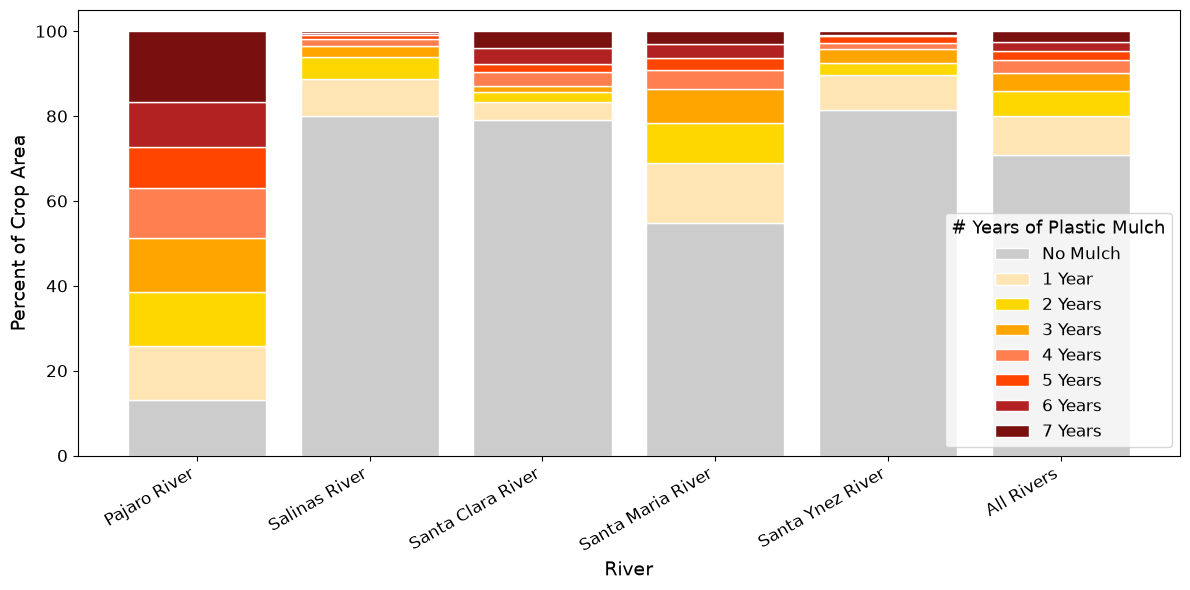

In [38]:
# Stacked bar chart for percent of crop area by mulch frequency class for each river, plus all rivers combined

categories = ['pct_nomulch'] + [f'pct_{i}' for i in range(1, n_years + 1)]  # n_years = 7
labels = ['No Mulch', '1 Year'] + [f'{i} Years' for i in range(2, n_years + 1)]
colors = ['#cccccc', '#ffe5b4', '#ffd700', '#ffa500', '#ff7f50', '#ff4500', '#b22222', '#7a0f0f']

# Prepare river names plus 'All Rivers'
rivers_list = list(freq_df['Name']) + ['All Rivers']

# Prepare percent data for each river
percent_data = [freq_df[cat].values for cat in categories]
percent_data = np.array(percent_data).T  # shape: (num_rivers, num_categories)

# Add the 'All Rivers' combined data from percent_sums
all_rivers_percent = percent_sums

# Stack percent data for plotting
percent_data = np.vstack([percent_data, all_rivers_percent])

xaxis = np.zeros(len(rivers_list))

plt.figure(figsize=(12, 6))
for idx, (cat, label, color) in enumerate(zip(categories, labels, colors)):
    plt.bar(rivers_list, percent_data[:, idx], bottom=xaxis, label=label, color=color, edgecolor='white')
    xaxis += percent_data[:, idx]

plt.ylabel('Percent of Crop Area', fontsize=14)
plt.xlabel('River', fontsize=14)
plt.xticks(rotation=30, ha='right', fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title='# Years of Plastic Mulch', fontsize=12, title_fontsize=13)
plt.tight_layout()

plt.show()

In [ ]:
# freq_df_county = pd.read_csv('data/MulchandCropFreq_v1_3_byCounty.csv') # v1.3, from Pro
freq_df_county = pd.read_csv('output/MulchandCropFreq_v1_4_byCounty.csv')

n_years = max(int(c.split('_')[1]) for c in freq_df_county.columns if c.startswith('count_') and c.split('_')[1].isdigit())

# add a column that's the total number of crop pixels with no mulching 
freq_df_county['count_nomulch'] = freq_df_county['count_crop'] - freq_df_county[[f'count_{i}' for i in range(1, n_years + 1)]].sum(axis=1)

# convert pixel counts to area in km2
pixel_area_km2 = 100 / 1e6  # area of one 10m pixel in km²
freq_df_county['areakm_crops'] = freq_df_county['count_crop'] * pixel_area_km2
freq_df_county['areakm_nomulch'] = freq_df_county['count_nomulch'] * pixel_area_km2
freq_df_county['pct_nomulch'] = (freq_df_county['areakm_nomulch'] / freq_df_county['areakm_crops']) * 100

# display(freq_df_county)

# calc the percent area in each freq class for each county, based on areakm_crop
for i in range(1, n_years + 1):
    freq_df_county[f'areakm_{i}'] = freq_df_county[f'count_{i}'] * pixel_area_km2
    freq_df_county[f'pct_{i}'] = (freq_df_county[f'areakm_{i}'] / freq_df_county['areakm_crops']) * 100

# calc cumulative area for 1+ years, 2+ years, 3+ years of mulching
freq_df_county['OnePlus_km2'] = freq_df_county[[f'areakm_{i}' for i in range(1, n_years + 1)]].sum(axis=1)
freq_df_county['OnePlus_pct'] = (freq_df_county['OnePlus_km2'] / freq_df_county['areakm_crops']) * 100
freq_df_county['TwoPlus_km2'] = freq_df_county[[f'areakm_{i}' for i in range(2, n_years + 1)]].sum(axis=1)
freq_df_county['TwoPlus_pct'] = (freq_df_county['TwoPlus_km2'] / freq_df_county['areakm_crops']) * 100
freq_df_county['ThreePlus_km2'] = freq_df_county[[f'areakm_{i}' for i in range(3, n_years + 1)]].sum(axis=1)
freq_df_county['ThreePlus_pct'] = (freq_df_county['ThreePlus_km2'] / freq_df_county['areakm_crops']) * 100

# calc cumulative area for 1+ years, 2+ years, 3+ years of mulching for county-level data
freq_df_county['RepeatMulch_pct_ofMulched'] = (freq_df_county['TwoPlus_km2'] / freq_df_county['OnePlus_km2']) * 100
display(freq_df_county[['County', 'RepeatMulch_pct_ofMulched']])

# ag areas across counties that was mulched at least once (as a percent of total crop area)
total_mulched1plus_km2 = freq_df_county['OnePlus_km2'].sum()
display(f'Total area across counties that was mulched at least once = {total_mulched1plus_km2:.2f} km²')

# of the area km2 that was mulched one or more times, how much was mulched two or more times
# total across all counties
total_repeat_mulch = (freq_df_county['TwoPlus_km2'].sum() / freq_df_county['OnePlus_km2'].sum()) * 100
display(f'Of the area that was mulched one or more times, how much was mulched two or more times = {total_repeat_mulch:.2f}%')

total_crops_km2_county = freq_df_county['areakm_crops'].sum()
total_mulched1plus_km2 = freq_df_county['OnePlus_km2'].sum()

,County,RepeatMulch_pct_ofMulched
0,Monterey County,71.805707
1,San Luis Obispo County,61.059580
2,Santa Barbara County,65.535030
3,Ventura County,69.981059
4,Santa Cruz County,71.994072


'Of the area that was mulched one or more times, how much was mulched two or more times = 68.75%'

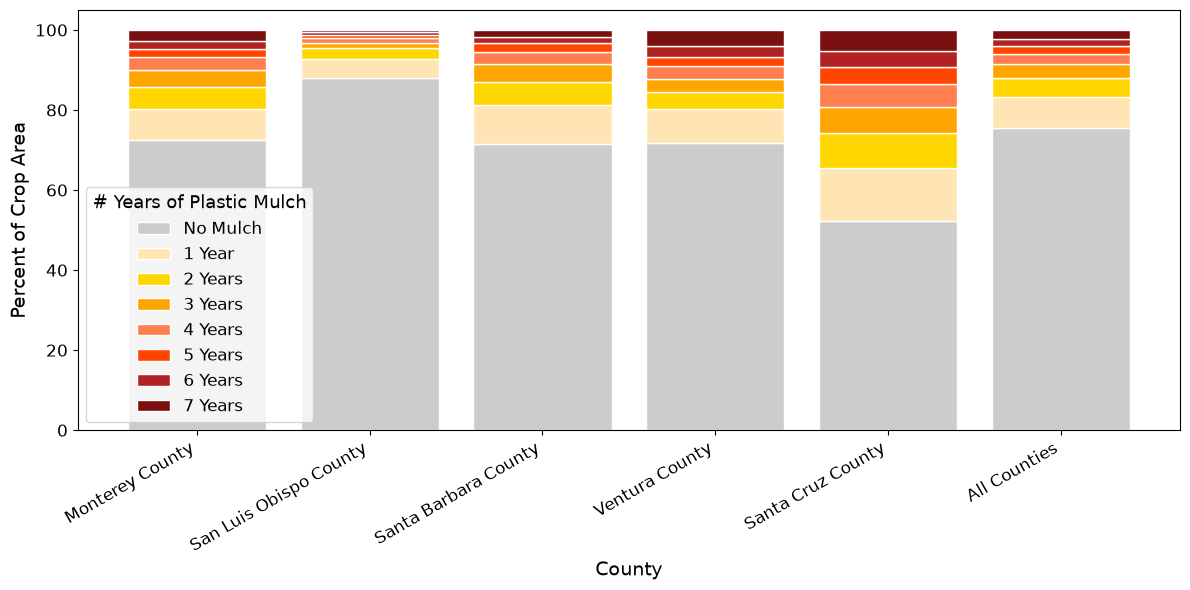

In [40]:
# Stacked bar chart for percent of crop area by mulch frequency class for each county, plus all counties combined

categories = ['pct_nomulch'] + [f'pct_{i}' for i in range(1, n_years + 1)]
labels = ['No Mulch', '1 Year'] + [f'{i} Years' for i in range(2, n_years + 1)]
colors = ['#cccccc', '#ffe5b4', '#ffd700', '#ffa500', '#ff7f50', '#ff4500', '#b22222', '#7a0f0f']

# Prepare county names plus 'All Counties'
counties_list = list(freq_df_county['County']) + ['All Counties']

# Prepare percent data for each county
percent_data = [freq_df_county[cat].values for cat in categories]
percent_data = np.array(percent_data).T  # shape: (num_counties, num_categories)

# All Counties combined: summed area per class / total crop area
freq_classes_county = ['areakm_nomulch'] + [f'areakm_{i}' for i in range(1, n_years + 1)]
all_counties_percent = (freq_df_county[freq_classes_county].sum() / total_crops_km2_county).values * 100

# Stack percent data for plotting
percent_data = np.vstack([percent_data, all_counties_percent])

xaxis = np.zeros(len(counties_list))

plt.figure(figsize=(12, 6))
for idx, (cat, label, color) in enumerate(zip(categories, labels, colors)):
    plt.bar(counties_list, percent_data[:, idx], bottom=xaxis, label=label, color=color, edgecolor='white')
    xaxis += percent_data[:, idx]

plt.ylabel('Percent of Crop Area', fontsize=14)
plt.xlabel('County', fontsize=14)
plt.xticks(rotation=30, ha='right', fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title='# Years of Plastic Mulch', fontsize=12, title_fontsize=13)
plt.tight_layout()

plt.show()